<img src="logo.png" alt="Vegeta" width="240">

# Kestrel-4Q — a zero-stagger biplane quadrotor tailsitter, and its transitions through the stall

**Kestrel-4Q** is a concept for a small electric UAV that takes off and lands standing on its tail like a quadcopter
and cruises on two wings like an aeroplane. Two straight, equal-span wings sit one above the other with their leading
edges at the **same** station (zero stagger), braced by carbon posts and an X of diagonals; a slim pod between them
carries the battery, the electronics and a forward-looking camera; **four fixed propellers**, one at each wing, all
thrust along the pod's axis — there is no tilt mechanism: the whole aircraft pitches 90° between the hover and the
cruise.

<img src="designs/data/kestrel_concept.webp" alt="Kestrel-4Q concept render" width="640">

*The concept render: appearance and intended operating principle, not a mechanical drawing.*

**The question of this notebook** is the one the concept cannot answer by looking at it: **does it fly through its
transitions?** Going from the hover to the cruise and back, a tailsitter sweeps its angle of attack from 90° to 5° and
back, and between ~11° and ~60° its wing is stalled. Can the four motors, their propellers and the controller hold the
attitude and the height through that stall — forward and back — and with what margin? On the way there, the
specification's own *engineering hold point*: can four fixed, parallel rotors control the aircraft at all?

```
CAD (Dedalus): two wings at one station, pod, truss, nacelles, fin plate, feet ─► layout, clearances, mass table, CG, inertia
Boreas: 9x6 on a 2216 880 KV, 4S ─► full thrust and torque/thrust against the inflow ─► hover, thrust-to-weight
allocation matrix ─► rank per sense of rotation, attainable moments, a motor out, the hover in wind, roll authority
vortex lattice (biplane) + drag build-up ─► neutral point, full-range polar, cruise power, trim by differential thrust
transition model (pitch plane, blown and free-stream spans) ─► hover→cruise and cruise→hover, the matrix, the verdict
Aeromant CFD: the airframe at the transition points with four rotor disks ─► the polar's check ─► the transitions again
plane frame: the truss braced / posts / none ─► stresses, buckling, propeller gap ─► standing on the feet in wind
```

The design modules: `designs/kestrel.py` (CAD and layout), `kestrel_systems.py` (parts, masses, drive tables),
`kestrel_control.py` (the hold point), `kestrel_flight.py` (aerodynamics and cruise), `kestrel_transition.py` (the
transitions), `kestrel_cfd.py` (the CFD and its feedback), `kestrel_structure.py` (truss and ground stance),
`kestrel_drawings.py`; Aeromant's new `aircraft_quad_rotor_disks` template. **Status: concept study** — every number
is an input of this study or a first estimate, none is a validated design value.

**How this notebook is built: a loop, not a pipeline.** Every pass through it estimates, checks the numbers against
the study's targets, changes what fails and goes round again — the tables headed *check* and the *iteration log* at
the end keep the score:

| iteration | what is plugged in | what it changes |
|---|---|---|
| 0 | the envelope: the spec's numbers, the layout's lengths and five assumptions (§ 0) | nothing yet — the numbers to beat |
| 1 | the tools: the CAD's mass table, Boreas, the lattice, the drag build-up (§ 1–5) | the battery's station for the static margin |
| 2 | the transition model (§ 6) | the effectors (elevons), the schedule (≥ 3 s), the back entry speed |
| 3 | the CFD, where it has been run — this notebook's own run or the test campaign of notebook 40 (§ 7) | the polar's stall and drag; the matrix flown again |
| 4–8 | Part II: the payload bay, elevons, faired struts, the section, the bracing (§ 11–15) | each proved or disproved on its own numbers |
| 9 | Kestrel-4Q-2 with the slow-entry rule (§ 16) | the design this study hands on |

A failed computation is a result here, not a crash: a CFD case that diverges or fails is listed as such and left out
of the correction, a transition that diverges is a failed transition.

In [1]:
# DEBUG: test the notebook end to end before the full run (FEA and CFD mocked). On here or from the shell:
#   VEGETA_DEBUG=1 jupyter nbconvert --to notebook --execute 38_kestrel.ipynb --output 38_kestrel-run.ipynb
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, shutil, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vegeta import dedalus, aeromant
sys.path.insert(0, "designs")
import kestrel, kestrel_systems as ks, kestrel_control as kc, kestrel_flight as kf
import kestrel_transition as kt, kestrel_cfd as kcfd, kestrel_structure as kst, kestrel_drawings as kd, kestrel_xwing as kx
import kestrel_loop as kl
LOG = kl.IterationLog()
def show_checks(checks, title):
    t = kl.check_table(checks, title); display(t); print(f"{title}: {t.attrs['passes']} of {t.attrs['of']} hold" + (f" — failing: {', '.join(kl.failing(checks))}" if not kl.all_hold(checks) else ""))

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
RUNS = Path("_runs/kestrel"); RUNS.mkdir(parents=True, exist_ok=True)
OUT = Path("output/38_kestrel"); OUT.mkdir(parents=True, exist_ok=True)
shutil.copy("designs/kestrel.py", RUNS / "kestrel.py")
design = dedalus.load_design(f"{RUNS / 'kestrel.py'}:Kestrel4Q")
QUICK = os.environ.get("KESTREL_QUICK") == "1"
RUN_CFD = os.environ.get("VEGETA_SKIP_OPENFOAM") != "1"
STATUS = {}
print(f"DEBUG {DEBUG} | QUICK {QUICK} | CFD {'on' if RUN_CFD else 'NOT RUN (VEGETA_SKIP_OPENFOAM=1)'}")
SPEC = pd.Series({"configuration": "electric quadrotor tailsitter, two load-bearing wings", "wings": "zero stagger, equal span, straight",
                  "rotors": "exactly four, fixed, thrust axes parallel to the pod", "take-off mass (this study's target) [kg]": "≤ 2.0",
                  "thrust-to-weight in the hover": "≥ 2", "cruise (survey) [m/s]": f"{kf.V_CRUISE:g}", "endurance at cruise [min]": "≥ 20",
                  "transitions": "both ways, height within 3 m (10 m gain going back), attitude within 10°", "wind for operations [m/s]": "8"},
                 name="Kestrel-4Q — the targets this study sets")
display(SPEC.to_frame())
pd.DataFrame(design.params.table()).set_index("name")

DEBUG False | QUICK False | CFD NOT RUN (VEGETA_SKIP_OPENFOAM=1)


,Kestrel-4Q — the targets this study sets
configuration,"electric quadrotor tailsitter, two load-bearing wings"
wings,"zero stagger, equal span, straight"
rotors,"exactly four, fixed, thrust axes parallel to the pod"
take-off mass (this study's target) [kg],≤ 2.0
thrust-to-weight in the hover,≥ 2
cruise (survey) [m/s],16
endurance at cruise [min],≥ 20
transitions,"both ways, height within 3 m (10 m gain going back), attitude within 10°"
wind for operations [m/s],8


,default,units,min,max,description
name,,,,,
part,aircraft,NaN,NaN,NaN,what to build
span,1000.0,mm,300.00,NaN,span of each wing (both equal)
chord,140.0,mm,40.00,NaN,"chord of each wing (constant, straight wings)"
gap,280.0,mm,80.00,NaN,vertical distance between the wings' chord planes
wing_le_x,200.0,mm,50.00,NaN,"both leading edges, from the nose tip (zero stagger)"
thickness,0.12,,0.06,0.20,NACA thickness ratio
camber,0.0,,0.00,0.06,"NACA camber (0: symmetric, no pitching moment to trim without a tail)"
camber_pos,0.4,,0.10,0.90,
spar_x,0.3,,0.10,0.60,"main spar (and post) station, fraction of chord"


## 0. Iteration 0 — the envelope

Before any tool runs: the aircraft from the targets and the layout's lengths alone — the wing area from span and
chord, the wing loading at 2.0 kg, the cruise lift coefficient at 16 m/s, the stall speed with an assumed CL max of
0.9, the hover thrust per rotor and its power from momentum theory, the cruise power from an assumed L/D of 6 and the
battery's usable energy, the static margin with the CG at 10 % of the chord. These are the numbers the tools must
beat, and the first check of whether the concept closes at all.

In [3]:
ENV = kl.envelope(mass_kg=2.0)
display(pd.Series({k: v for k, v in ENV.items() if k != "assumptions"}, name="iteration 0 — the envelope").round(3).to_frame())
display(pd.Series(ENV["assumptions"], name="assumed").to_frame().T)
CHK0 = [kl.check("take-off mass [kg]", ENV["take-off mass [kg]"]), kl.check("endurance at the cruise [min]", ENV["endurance at the cruise [min]"]),
        kl.check("static margin [chords]", ENV["static margin [chords]"]), kl.check("stall speed / cruise speed", ENV["stall speed / cruise speed"]),
        kl.check("cruise CL / CL max", ENV["cruise CL / CL max"]),
        kl.check("hover power / battery → hover time [min]", ENV["hover time [min]"], "≥", 5.0, note="the hover is for take-off, landing and the transitions")]
show_checks(CHK0, "iteration 0 — the envelope")
LOG.add("0 — envelope", changed="—", source="spec + layout + 5 assumptions", checks=CHK0,
        **{k: ENV[k] for k in ("take-off mass [kg]", "static margin [chords]", "stall speed [m/s]", "cruise power [W]", "endurance at the cruise [min]")},
        **{"L/D at the cruise": ENV["assumptions"]["L/D at the cruise"], "hover thrust / weight": 2.0})

,iteration 0 — the envelope
take-off mass [kg],2.000
wing area [m²],0.280
wing loading [N/m²],70.047
cruise CL,0.447
CL max assumed,0.900
cruise CL / CL max,0.496
stall speed [m/s],11.273
stall speed / cruise speed,0.705
hover thrust per rotor [N],4.903
full thrust per rotor needed [N],9.807


,CL max of the wings,L/D at the cruise,figure of merit in the hover,propulsive efficiency in cruise,avionics and payload power [W]
assumed,0.9,6.0,0.6,0.55,13.0


iteration 0 — the envelope,value,target,holds,note
check,,,,
take-off mass [kg],2,≤ 2,✔,
endurance at the cruise [min],21.7,≥ 20,✔,
static margin [chords],0.12,0.05 – 0.15,✔,
stall speed / cruise speed,0.705,≤ 0.8,✔,
cruise CL / CL max,0.496,≤ 0.6,✔,
hover power / battery → hover time [min],10.3,≥ 5,✔,"the hover is for take-off, landing and the transitions"


iteration 0 — the envelope: 6 of 6 hold


{'iteration': '0 — envelope',
 'what changed': '—',
 'source': 'spec + layout + 5 assumptions',
 'take-off mass [kg]': 2.0,
 'static margin [chords]': 0.11999999999999986,
 'stall speed [m/s]': 11.272546064868418,
 'cruise power [W]': 108.09478787878787,
 'endurance at the cruise [min]': 21.687632179164865,
 'L/D at the cruise': 6.0,
 'hover thrust / weight': 2.0,
 'checks holding': '6 / 6',
 'failing': '—'}

## 1. The aircraft

Both wings are built from one leading-edge station: zero stagger is not a parameter that could drift. The layout's
rules are checked before anything is built: the upper and lower propeller discs clear each other (the gap minus a
diameter), the discs clear the pod, the propeller plane is ahead of the leading edge, the nacelles stay on the wings,
the feet reach aft of the pod.

layout rules: all hold


,volume [cm³],area [cm²],size [mm]
aircraft,14639.183649,14483.665904,545 × 1009 × 632
airframe,14312.496141,11164.037883,545 × 1000 × 632
wing,1607.662884,2841.493742,137 × 1000 × 17
pod,10403.580534,2992.433751,475 × 110 × 274
truss,76.773891,465.825365,8 × 788 × 285
nacelle,139.350725,184.081876,177 × 34 × 34
tail,560.092328,2912.105266,261 × 786 × 632


,span,chord,gap,h,x_le,x_te,x_ac,x_spar,S_wing,S_ref,...,fin_root_x,foot_rod_length,elevons,elevon_cf,elevon_y_in,elevon_span_side,x_hinge,S_elevon,diagonals,posts
"layout [m, m²]",1.0,0.14,0.28,0.14,0.2,0.34,0.235,0.242,0.14,0.28,...,0.28,0.256,0,0.28,0.275,0.225,0.3008,0.0353,4,2


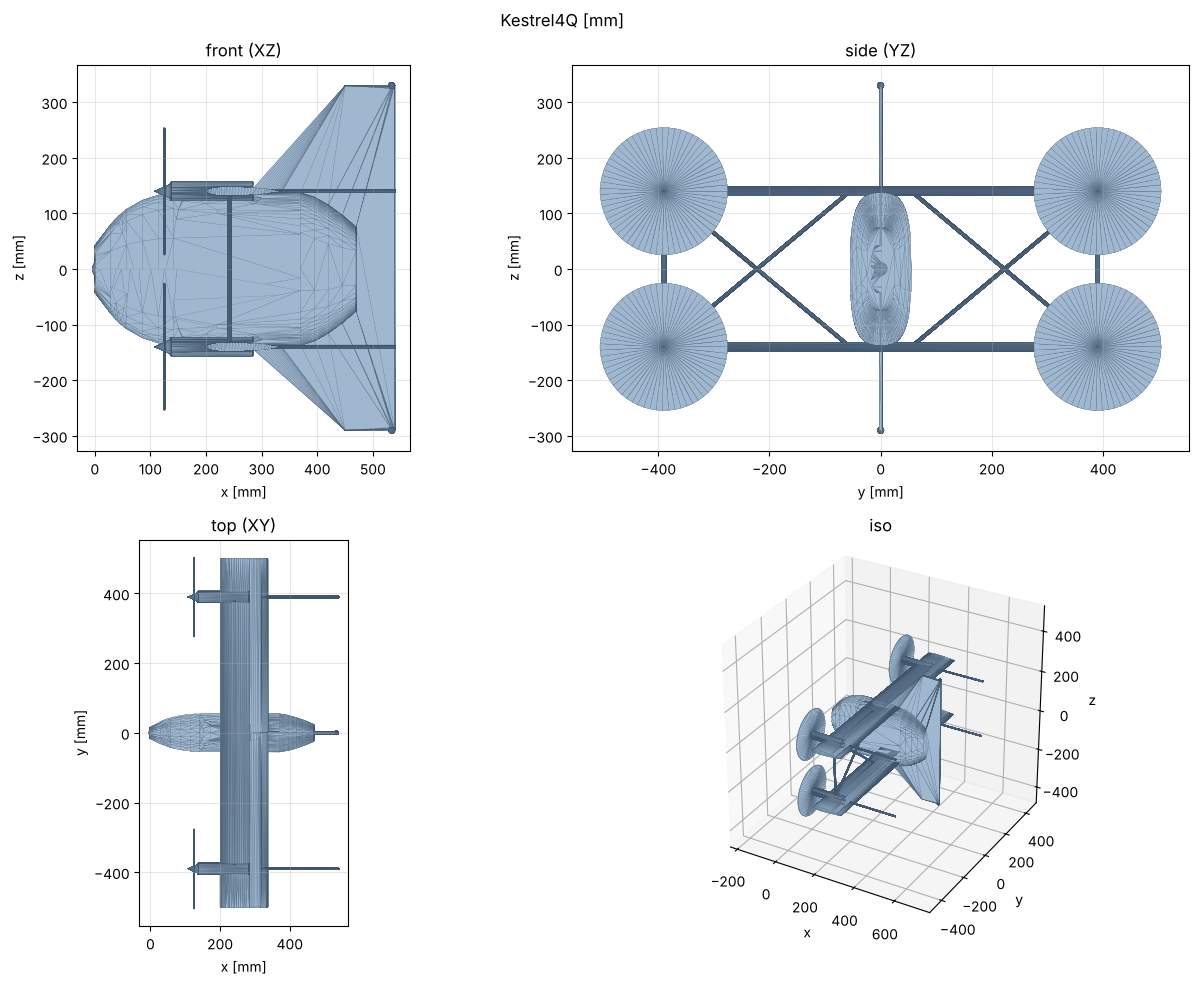

In [4]:
P = design.resolve()
L = kestrel.Kestrel4Q.layout(P)
print("layout rules:", kestrel.Kestrel4Q.checks(P) or "all hold")
parts = {k: design.generate(part=k) for k in ("aircraft", "airframe", "wing", "pod", "truss", "nacelle", "tail")}
cad = {k: g.export(RUNS / "cad" / k, stl_tolerance=0.3) for k, g in parts.items()}
display(pd.DataFrame({k: {"volume [cm³]": (g.measure()["volume"] or 0) / 1e3, "area [cm²]": g.measure()["surface_area"] / 1e2,
                          "size [mm]": " × ".join(f"{d:.0f}" for d in g.measure()["dimensions"])} for k, g in parts.items()}).T)
lay = pd.Series({k: v for k, v in L.items() if isinstance(v, (int, float))}, name="layout [m, m²]")
display(lay.round(4).to_frame().T)
dedalus.plot_views(parts["aircraft"], figsize=(13, 10)); plt.show()

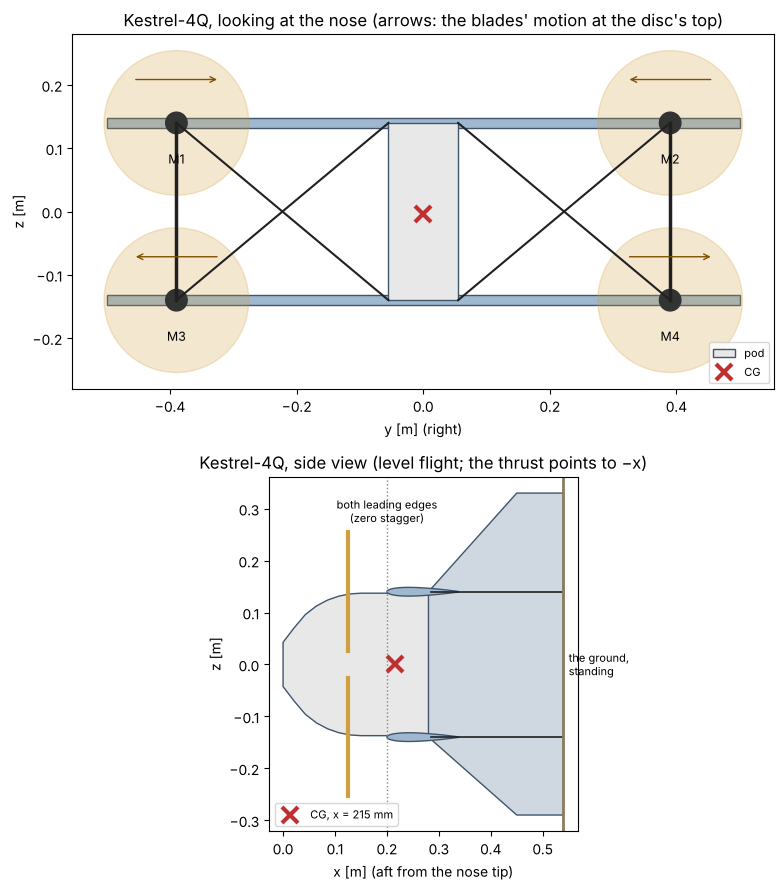

In [5]:
TABLE = ks.mass_table(P)
CI = ks.cg_inertia(TABLE)
fig, ax = plt.subplots(2, 1, figsize=(12, 9))
kd.front_view(P, cg=CI, ax=ax[0]); kd.side_view(P, x_cg=CI["x_cg"], ax=ax[1]); plt.tight_layout(); plt.show()

## 2. Masses, centre of gravity, inertia

The structure from the layout's lengths and areas with assumed densities (balsa-composite wing panels, carbon tubes,
printed joints), the bought parts from `kestrel_systems.COMPONENTS`, a growth margin. The battery slides in the pod to
put the CG 10 % of the chord behind the leading edge — the static margin in section 5 says whether that is right.

In [6]:
mt = pd.DataFrame(TABLE).set_index("item")[["mass_kg", "x", "y", "z", "group"]]
display(mt.assign(mass_g=lambda d: d.mass_kg * 1000).drop(columns="mass_kg").round(3))
grp = pd.Series(ks.groups(TABLE), name="kg")
display(grp.round(3).to_frame().T)
print(f"take-off mass {CI['mass_kg']:.3f} kg; CG x {CI['x_cg'] * 1000:.1f} mm (battery at {CI['battery_x'] * 1000:.0f} mm, "
      f"bay {ks.battery_range(P)[0] * 1000:.0f}-{ks.battery_range(P)[1] * 1000:.0f} mm), z {CI['z_cg'] * 1000:+.1f} mm; "
      f"Ixx {CI['Ixx']:.4f}, Iyy {CI['Iyy']:.4f}, Izz {CI['Izz']:.4f} kg·m²")

,x,y,z,group,mass_g
item,,,,,
motor M1,0.150,-0.390,0.140,propulsion,66.000
propeller M1,0.125,-0.390,0.140,propulsion,14.000
ESC M1,0.220,-0.390,0.140,propulsion,14.000
nacelle M1,0.205,-0.390,0.140,structure,12.000
motor M2,0.150,0.390,0.140,propulsion,66.000
propeller M2,0.125,0.390,0.140,propulsion,14.000
ESC M2,0.220,0.390,0.140,propulsion,14.000
nacelle M2,0.205,0.390,0.140,structure,12.000
motor M3,0.150,-0.390,-0.140,propulsion,66.000


,propulsion,structure,systems,payload,margin
kg,0.736,0.625,0.16,0.105,0.06


take-off mass 1.686 kg; CG x 214.8 mm (battery at 220 mm, bay 220-300 mm), z -4.5 mm; Ixx 0.1063, Iyy 0.0221, Izz 0.0980 kg·m²


## 3. Propulsion

One drive: a 9x6 propeller on a 2216-class 880 KV motor on 4S, through Boreas (BEMT with the generic section, the
motor's first-order model, the battery). The transition model reads three tables against the axial inflow: the full
thrust, the torque-to-thrust ratio κ — the rotor's reaction torque per newton, the **only** lever about the thrust axis
without control surfaces — and the electrical power. Boreas's generic section reads ~25 % low on static thrust: the
control margins below are on the safe side of it.

,thrust_N,rpm,current_A,electrical_W,throttle,figure_of_merit,T_max_N,T_W,kappa_m,total_W
"hover, one drive",4.134,6709.9298,6.6538,55.1622,0.5602,0.5649,11.9606,2.8932,0.0162,220.6488


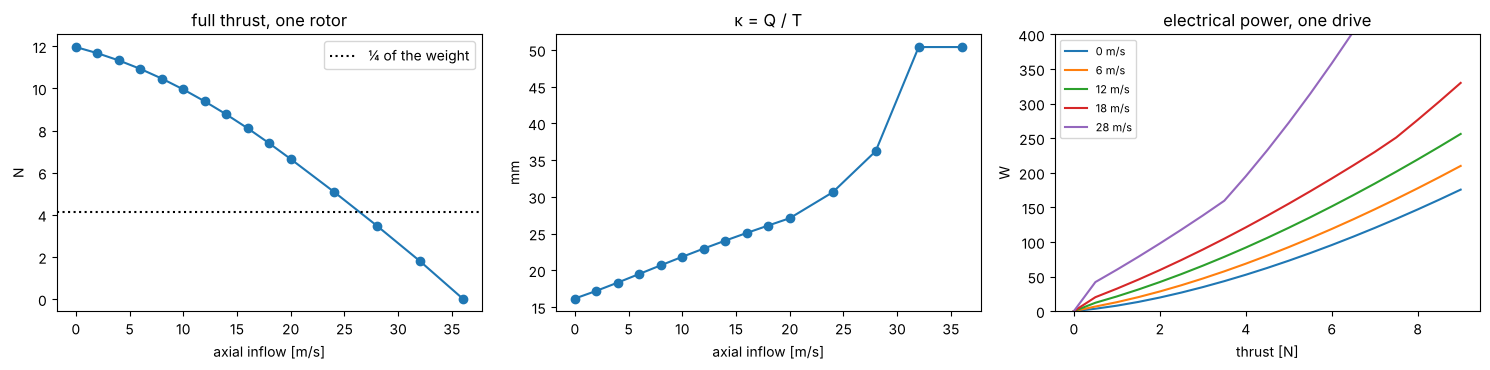

In [7]:
DR = ks.drive_table()
HP = ks.hover_point(CI["mass_kg"])
display(pd.Series(HP, name="hover, one drive").round(4).to_frame().T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(DR.V, DR.T_max, "o-"); ax[0].axhline(CI["mass_kg"] * ks.G / 4, color="k", ls=":", label="¼ of the weight"); ax[0].set(xlabel="axial inflow [m/s]", ylabel="N", title="full thrust, one rotor"); ax[0].legend()
ax[1].plot(DR.V, np.array(DR.kappa) * 1000, "o-"); ax[1].set(xlabel="axial inflow [m/s]", ylabel="mm", title="κ = Q / T")
for i, v in enumerate(DR.V[::3]):
    j = list(DR.V).index(v)
    ax[2].plot(DR.T, DR.P[j], label=f"{v:g} m/s")
ax[2].set(xlabel="thrust [N]", ylabel="W", title="electrical power, one drive", ylim=(0, 400)); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. The hold point: can four fixed, parallel rotors control it?

The allocation matrix maps the four thrusts to the collective thrust and the three moments about the CG. A rotor at
(dx, y, dz) from the CG pushing toward the nose gives the moment (0, −dz·T, y·T): the **vertical** offset (the gap)
pitches, the **spanwise** offset yaws (in cruise; in the hover it tilts sideways), and a fore–aft offset gives nothing
at all — in a tailsitter the thrust axis is the body axis. The moment about the thrust axis itself (the heading in the
hover, the roll in cruise) only comes from the rotors' reaction torques, ±κ·T. Standing nose-up, the y–z plane is
horizontal and the illustrated 2 × 2 layout is a quadcopter's X seen from above. So the layout is the right one; what
decides is **which way each rotor turns**.

In [8]:
CG = {"x_cg": CI["x_cg"], "y_cg": CI["y_cg"], "z_cg": CI["z_cg"]}
RANK = kc.rank_table(P, kappa=float(DR.kap(0.0)), cg=CG)
display(RANK)
HA = kc.hover_authority(P, mass_kg=CI["mass_kg"], cg=CG, inertia=CI["I"])
display(HA.round(3))
MO = kc.motor_out(P, mass_kg=CI["mass_kg"], cg=CG)
display(MO)
HW = kc.hover_wind(P, mass_kg=CI["mass_kg"], cg=CG)
display(HW.round(2))

,senses (M1..M4),mirror-symmetric,rank,"σ (N, N·m)",condition,never produced,verdict
"diagonal pairs (M1, M4 | M2, M3)","(1, -1, -1, 1)",True,4,"2, 0.78, 0.28, 0.0323",61.907343,—,full control (thrust + 3 moments)
"side columns alike (M1, M3 | M2, M4)","(1, -1, 1, -1)",True,3,"2, 0.781, 0.28, 2.31e-17",inf,+1.00·L + -0.04·N,NOT controllable in the hover
"rows alike (M1, M2 | M3, M4)","(1, 1, -1, -1)",False,3,"2, 0.78, 0.282, 2.62e-17",inf,+0.00·T + -1.00·L + +0.12·M,NOT controllable in the hover
all the same way,"(1, 1, 1, 1)",False,3,"2, 0.78, 0.28, 7.82e-18",inf,+0.02·T + +1.00·L,NOT controllable in the hover


,most negative [N·m],most positive [N·m],inertia [kg·m²],angular acceleration [rad/s²]
about the thrust axis (hover heading / cruise roll),-0.242,0.242,0.106,2.280
about y (pitch-over / cruise pitch),-2.249,2.101,0.022,94.993
about z (hover tilt sideways / cruise yaw),-5.853,5.853,0.098,59.698


,thrusts of the others [N],within limits,unbalanced torque about the axis [N·m],hover
M1 out,"8.00, 8.27, 0.26",True,0.258558,"flies on one diagonal pair (the partner idles): holds thrust and tilt, spins about its..."
M2 out,"8.00, 0.26, 8.27",True,-0.258558,"flies on one diagonal pair (the partner idles): holds thrust and tilt, spins about its..."
M3 out,"8.27, -0.26, 8.53",False,-0.275666,cannot hold the weight level
M4 out,"-0.26, 8.27, 8.53",False,0.275666,cannot hold the weight level


,wing drag [N],lean into the wind [deg],thrust per rotor [N],T_max per rotor [N],pitch moment left [N·m]
2 m/s,0.82,2.85,4.14,11.96,2.10
4 m/s,3.29,11.26,4.22,11.96,2.14
6 m/s,7.41,24.13,4.53,11.96,2.32
8 m/s,13.17,38.54,5.29,11.96,2.72
10 m/s,20.58,51.22,6.60,11.96,2.88


Only the **diagonal pairing** (M1 and M4 one way, M2 and M3 the other) gives the full rank. The mirror-symmetric
alternative — each side's two rotors turning alike, the "stacked twin" look — makes the reaction-torque row a multiple
of the yaw row: the heading in the hover is lost. The heading lever is the weak one (κ ≈ 16 mm against a half gap of
140 mm and a motor station of 390 mm): ~2 rad/s² of heading acceleration against ~100 rad/s² in pitch. A rotor out in
the hover leaves its diagonal partner idle and an unbalanced torque about the thrust axis: the aircraft can hold its
thrust and tilt while it spins (a reduced-attitude controller), or it needs a parachute — it cannot hold its heading.
Standing in the hover broadside to a wind, the wings are a sail: at 8 m/s it must lean ~40° into it. Turning edge-on
to the wind (yaw) is the operating rule.

## 5. Aerodynamics: the biplane, the drag of the bracing, the polar, the cruise

PEREGRINE's vortex lattice on the two wings at z = ±gap/2 against one of them alone and against a monoplane of the
same span and area — Prandtl's biplane theory puts the induced drag at (1 + σ)/2 of the monoplane's, σ ≈ 0.35 at this
gap/span of 0.28 (the lattice should land near 0.68). The neutral point adds the pod and the four propellers' normal
force ahead of the CG (De Young's blade-element estimate; the momentum bound of a disk turning the whole cross-flow
is shown beside it).

,CLa,k,e,AR,S,x_np,upper share
biplane,4.0784,0.0599,1.4875,3.5714,0.28,0.2331,0.5
one wing alone,4.5576,0.0433,1.0281,7.1429,0.14,0.2437,NaN
"monoplane, same span and area",3.5528,0.0847,1.0522,3.5714,0.28,0.2650,NaN


,lift slope vs two isolated wings,induced drag vs the monoplane,gap / chord,gap / span
biplane factors,0.895,0.707,2.0,0.28


,round tubes [cm²],faired struts [cm²]
wings (2),24.51,24.51
pod (between the wings),6.85,6.85
fin plate,4.09,4.09
nacelles (4),6.44,6.44
posts (2),49.28,5.38
diagonals (4),73.92,8.06
"foot rods (4), axial",0.23,0.23
camera dome,4.07,4.07


Cd0: round 0.0665 (bracing 73 %), faired 0.0234 (bracing 23 %)


,x_np_wings,x_np,Cma_wings,Cma_pod,Cma_props,Cma,static_margin,x_cg
neutral point,0.2331,0.2282,-0.5304,0.0665,0.0647,-0.3992,0.0955,0.2148


propellers' normal force slope at 16 m/s: estimate 4.5 N/rad, momentum bound 53.0 N/rad


,cl_alpha,cd0,k,cl_max,cd90,alpha0,width,source
polar,4.07843,0.066549,0.066573,0.81,1.238571,0.0,0.02618,model


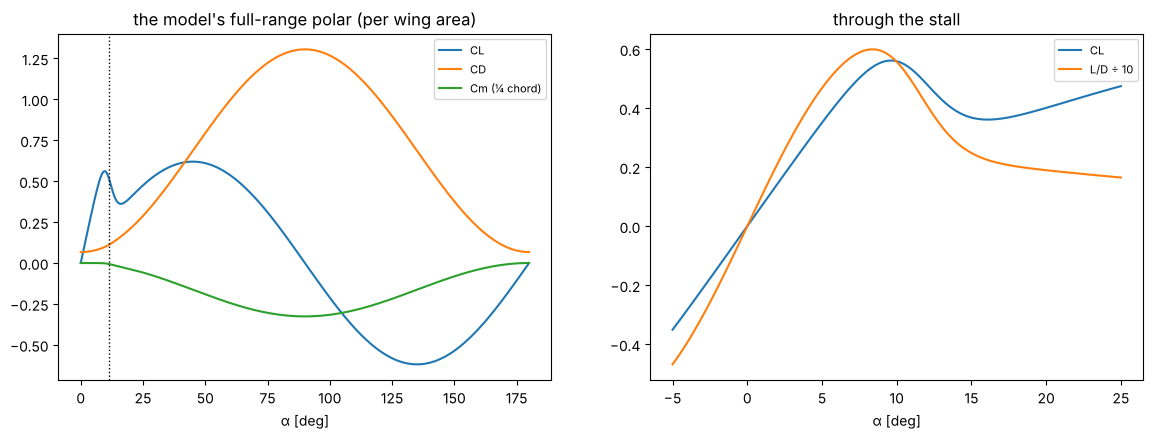

In [9]:
A = kf.aero(P)
display(pd.DataFrame({k: v for k, v in A.items() if k != "factors"}).T.round(4))
display(pd.Series(A["factors"], name="biplane factors").round(3).to_frame().T)
D_round, D_faired = kf.drag_buildup(P), kf.drag_buildup(P, faired=True)
dtab = pd.DataFrame({"round tubes": D_round["parts_m2"], "faired struts": D_faired["parts_m2"]}) * 1e4
display(dtab.round(2).rename(columns=lambda c: c + " [cm²]"))
print(f"Cd0: round {D_round['Cd0']:.4f} (bracing {D_round['bracing_share'] * 100:.0f} %), faired {D_faired['Cd0']:.4f} (bracing {D_faired['bracing_share'] * 100:.0f} %)")
NP = kf.neutral_point(P, x_cg=CI["x_cg"], a=A)
display(pd.Series(NP, name="neutral point").round(4).to_frame().T)
print(f"propellers' normal force slope at 16 m/s: estimate {kf.prop_normal_force_slope(16, 0.8, P):.1f} N/rad, momentum bound {kf.prop_normal_force_slope(16, 0.8, P, bound=True):.1f} N/rad")
POL = kf.polar(P, a=A)
display(pd.Series(POL.__dict__, name="polar").to_frame().T)
kd.polar_figure(POL); plt.show()

round tubes


,CL,feasible,note,α [deg],L/D,drag [N],Cm about CG,upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km]
V [m/s],,,,,,,,,,,,,
9.0,1.190,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10.0,0.964,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11.0,0.797,True,the upper pair below T_min: thrust alone cannot trim,11.195,7.323,2.258,-0.076,0.152,0.978,False,58.326,40.194,26.528
12.0,0.670,True,the upper pair below T_min: thrust alone cannot trim,9.407,6.946,2.381,-0.064,0.181,1.009,False,64.590,36.296,26.133
13.0,0.571,True,the upper pair below T_min: thrust alone cannot trim,8.015,6.467,2.557,-0.054,0.224,1.055,False,73.015,32.108,25.044
14.0,0.492,True,,6.911,5.951,2.779,-0.047,0.277,1.112,True,83.173,28.186,23.676
15.0,0.429,True,,6.020,5.440,3.040,-0.041,0.341,1.179,True,95.703,24.496,22.046
16.0,0.377,True,,5.291,4.956,3.336,-0.036,0.412,1.256,True,110.216,21.270,20.419
17.0,0.334,True,,4.687,4.511,3.666,-0.032,0.492,1.341,True,127.558,18.378,18.746


faired struts


,CL,feasible,note,α [deg],L/D,drag [N],Cm about CG,upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km]
V [m/s],,,,,,,,,,,,,
9.0,1.190,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10.0,0.964,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11.0,0.797,True,the upper pair below T_min: thrust alone cannot trim,11.195,12.128,1.363,-0.076,-0.065,0.747,False,43.635,53.725,35.459
12.0,0.670,True,the upper pair below T_min: thrust alone cannot trim,9.407,12.568,1.316,-0.064,-0.077,0.734,False,45.745,51.248,36.899
13.0,0.571,True,the upper pair below T_min: thrust alone cannot trim,8.015,12.651,1.307,-0.054,-0.079,0.732,False,48.493,48.344,37.708
14.0,0.492,True,the upper pair below T_min: thrust alone cannot trim,6.911,12.442,1.329,-0.047,-0.073,0.738,False,51.552,45.475,38.199
15.0,0.429,True,the upper pair below T_min: thrust alone cannot trim,6.020,12.019,1.376,-0.041,-0.062,0.750,False,55.240,42.439,38.195
16.0,0.377,True,the upper pair below T_min: thrust alone cannot trim,5.291,11.458,1.443,-0.036,-0.046,0.767,False,59.217,39.588,38.005
17.0,0.334,True,the upper pair below T_min: thrust alone cannot trim,4.687,10.819,1.528,-0.032,-0.025,0.789,False,63.853,36.715,37.449


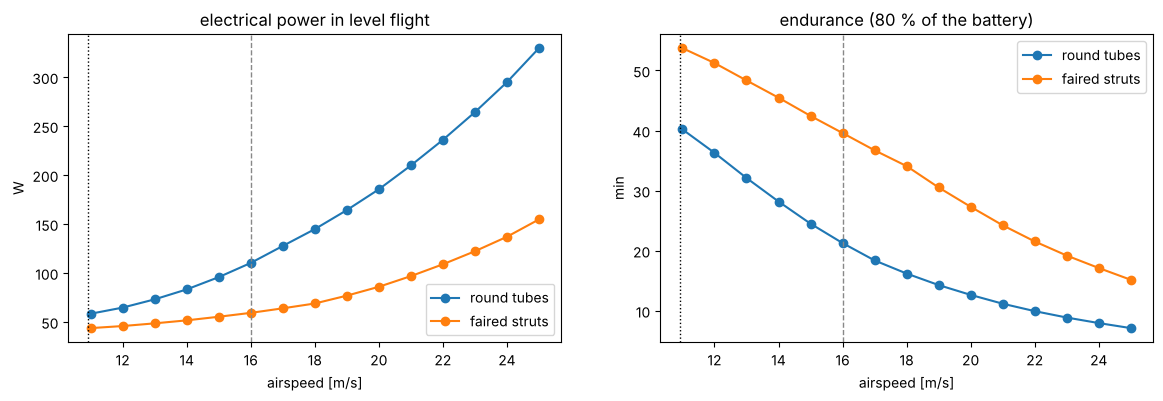

,torque lever [N·m],ailerons [N·m],ratio,aileron span per side [m]
V,,,,
12.0,0.422,2.168,5.131,0.224
16.0,0.394,3.906,9.911,0.224
20.0,0.347,6.176,17.821,0.224


In [10]:
CRU = {"round tubes": kf.cruise(P, mass_kg=CI["mass_kg"], x_cg=CI["x_cg"], z_cg=CI["z_cg"], pol=POL),
       "faired struts": kf.cruise(P, mass_kg=CI["mass_kg"], x_cg=CI["x_cg"], z_cg=CI["z_cg"], pol=kf.polar(P, a=A, faired=True))}
for k, c in CRU.items():
    print(k); display(c.round(3))
VS = kf.stall_speed(P, mass_kg=CI["mass_kg"], pol=POL)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, c in CRU.items():
    c = c[c["feasible"]]
    ax[0].plot(c.index, c["electrical [W]"], "o-", label=k); ax[1].plot(c.index, c["endurance [min]"], "o-", label=k)
for a_ in ax:
    a_.axvline(VS, color="k", ls=":", lw=1); a_.axvline(kf.V_CRUISE, color="#888", ls="--", lw=1); a_.set_xlabel("airspeed [m/s]"); a_.legend()
ax[0].set(ylabel="W", title="electrical power in level flight"); ax[1].set(ylabel="min", title="endurance (80 % of the battery)")
plt.show()
RA = pd.DataFrame([kc.roll_authority(P, V=v, thrust_each=float(CRU["round tubes"].loc[v, "upper rotor [N]"]), cl_alpha_3d=POL.cl_alpha)
                   for v in (12.0, 16.0, 20.0)]).set_index("V")
display(RA.round(3))

**Check — iteration 1, the tools plugged in.** The envelope's numbers against the tools', and the targets. The one
knob this pass turns is the battery's station: the mass table puts the CG where it is told (10 % of the chord) and
the static margin follows — the sweep below shows what moving the target does, and whether the battery can still
reach it inside its bay.

In [11]:
W_ = CI["mass_kg"] * ks.G
CL16 = W_ / (0.5 * ks.RHO0 * kf.V_CRUISE ** 2 * L["S_ref"])
c16 = CRU["round tubes"].loc[16.0]
CMP1 = pd.DataFrame({"envelope (iteration 0)": {"take-off mass [kg]": ENV["take-off mass [kg]"], "cruise CL": ENV["cruise CL"], "CL max": ENV["CL max assumed"],
                                                "stall speed [m/s]": ENV["stall speed [m/s]"], "hover power [W]": ENV["hover power, momentum theory [W]"],
                                                "cruise power at 16 m/s [W]": ENV["cruise power [W]"], "L/D at 16 m/s": ENV["assumptions"]["L/D at the cruise"],
                                                "endurance at 16 m/s [min]": ENV["endurance at the cruise [min]"], "static margin": ENV["static margin [chords]"], "hover T/W": 2.0},
                     "tools (iteration 1)": {"take-off mass [kg]": CI["mass_kg"], "cruise CL": CL16, "CL max": POL.cl_max, "stall speed [m/s]": VS, "hover power [W]": HP["total_W"],
                                             "cruise power at 16 m/s [W]": c16["electrical [W]"], "L/D at 16 m/s": c16["L/D"], "endurance at 16 m/s [min]": c16["endurance [min]"],
                                             "static margin": NP["static_margin"], "hover T/W": HP["T_W"]}})
CMP1["tools / envelope"] = CMP1["tools (iteration 1)"] / CMP1["envelope (iteration 0)"]
display(CMP1.round(3))
# the knob: the CG target (the battery's station) against the static margin
SM_SWEEP = {}
for frac in (0.06, 0.08, 0.10, 0.12, 0.15):
    ci_ = ks.cg_inertia(ks.mass_table(P, x_cg_target=L["x_le"] + frac * L["chord"]))
    SM_SWEEP[f"CG at {frac:.0%} of the chord"] = {"CG x [mm]": ci_["x_cg"] * 1000, "battery x [mm]": ci_["battery_x"] * 1000, "battery at its stop": ci_["battery_clipped"],
                                                   "static margin": kf.neutral_point(P, x_cg=ci_["x_cg"], a=A)["static_margin"]}
display(pd.DataFrame(SM_SWEEP).T.round(3))
CHK1 = [kl.check("layout rules broken", len(kestrel.Kestrel4Q.checks(P)), "≤", 0), kl.check("take-off mass [kg]", CI["mass_kg"]), kl.check("hover thrust / weight", HP["T_W"]),
        kl.check("battery inside its bay (not at a stop)", not CI["battery_clipped"], "==", True, note="at its forward stop: the margin is the bay's position, not the battery's (§ 11)"),
        kl.check("static margin [chords]", NP["static_margin"]),
        kl.check("stall speed / cruise speed", VS / kf.V_CRUISE), kl.check("cruise CL / CL max", CL16 / POL.cl_max), kl.check("endurance at the cruise [min]", c16["endurance [min]"]),
        kl.check("trim by thrust alone at the cruise", bool(c16["trim by thrust"]), "==", True, note="fails with faired struts: elevons (§ 6, Part II)")]
show_checks(CHK1, "iteration 1 — the tools")
LOG.add("1 — CAD, Boreas, lattice, drag build-up", changed="the CG target at 10 % of the chord (battery station)", source="kestrel_systems, Boreas, PEREGRINE lattice", checks=CHK1,
        **{"take-off mass [kg]": CI["mass_kg"], "static margin [chords]": NP["static_margin"], "hover thrust / weight": HP["T_W"], "stall speed [m/s]": VS, "Cd0": POL.cd0,
           "L/D at the cruise": c16["L/D"], "cruise power [W]": c16["electrical [W]"], "endurance at the cruise [min]": c16["endurance [min]"]})

,envelope (iteration 0),tools (iteration 1),tools / envelope
take-off mass [kg],2.000,1.686,0.843
cruise CL,0.447,0.377,0.843
CL max,0.900,0.810,0.900
stall speed [m/s],11.273,10.910,0.968
hover power [W],228.266,220.649,0.967
cruise power at 16 m/s [W],108.095,110.216,1.020
L/D at 16 m/s,6.000,4.956,0.826
endurance at 16 m/s [min],21.688,21.270,0.981
static margin,0.120,0.096,0.796
hover T/W,2.000,2.893,1.447


,CG x [mm],battery x [mm],battery at its stop,static margin
CG at 6% of the chord,214.848127,220.0,True,0.095525
CG at 8% of the chord,214.848127,220.0,True,0.095525
CG at 10% of the chord,214.848127,220.0,True,0.095525
CG at 12% of the chord,216.8,229.142389,False,0.081583
CG at 15% of the chord,221.0,248.814796,False,0.051583


iteration 1 — the tools,value,target,holds,note
check,,,,
layout rules broken,0,≤ 0,✔,
take-off mass [kg],1.69,≤ 2,✔,
hover thrust / weight,2.89,≥ 2,✔,
battery inside its bay (not at a stop),no,== yes,✘,"at its forward stop: the margin is the bay's position, not the battery's (§ 11)"
static margin [chords],0.0955,0.05 – 0.15,✔,
stall speed / cruise speed,0.682,≤ 0.8,✔,
cruise CL / CL max,0.465,≤ 0.6,✔,
endurance at the cruise [min],21.3,≥ 20,✔,
trim by thrust alone at the cruise,yes,== yes,✔,"fails with faired struts: elevons (§ 6, Part II)"


iteration 1 — the tools: 8 of 9 hold — failing: battery inside its bay (not at a stop)


{'iteration': '1 — CAD, Boreas, lattice, drag build-up',
 'what changed': 'the CG target at 10 % of the chord (battery station)',
 'source': 'kestrel_systems, Boreas, PEREGRINE lattice',
 'take-off mass [kg]': 1.6862063482324605,
 'static margin [chords]': np.float64(0.09552453569798042),
 'hover thrust / weight': 2.893213038200698,
 'stall speed [m/s]': 10.910411381833859,
 'Cd0': 0.06654869740668531,
 'L/D at the cruise': np.float64(4.956275655891227),
 'cruise power [W]': np.float64(110.21562126390147),
 'endurance at the cruise [min]': np.float64(21.27030608834237),
 'checks holding': '8 / 9',
 'failing': 'battery inside its bay (not at a stop)'}

The trim: with a symmetric section and no tail, the moment about the CG at a positive lift is nose-down by the
static margin; the lower pair pushes harder than the upper to hold the nose up. Where the upper pair would have to
drop below idle, thrust alone cannot trim — the elevons (trailing-edge surfaces on the blown outer panels) do it.
The roll in cruise: the rotors' reaction torque is a weak lever; ailerons on the blown panels are an order of
magnitude stronger. Both point the same way: the minimal concept needs **elevons** on the outer panels.

## 6. The transitions — hover to cruise and back, through the stall

`kestrel_transition` flies the aircraft in the vertical plane (x, z, pitch). Each wing is split into the span blown
by its two propellers and the rest: the slipstream adds a velocity Δv along the body axis, so the blown span sees a
much smaller angle of attack and a larger dynamic pressure than the free stream. The controller knows nothing of the
aerodynamic moment: a pitch schedule, a PID on pitch with gains scheduled on the airspeed, the height held with the
collective (a vertical-speed command limited to +3 / −2 m/s), the moment allocated to the differential thrust and the
elevons, the collective giving way when the rotors saturate. Roll is checked along the trajectory: the rolling
moment of one side's free-stream panels stalling first, against what the rotors and the elevons have left.

First the nominal pair: 3 s pitch schedules, still air.

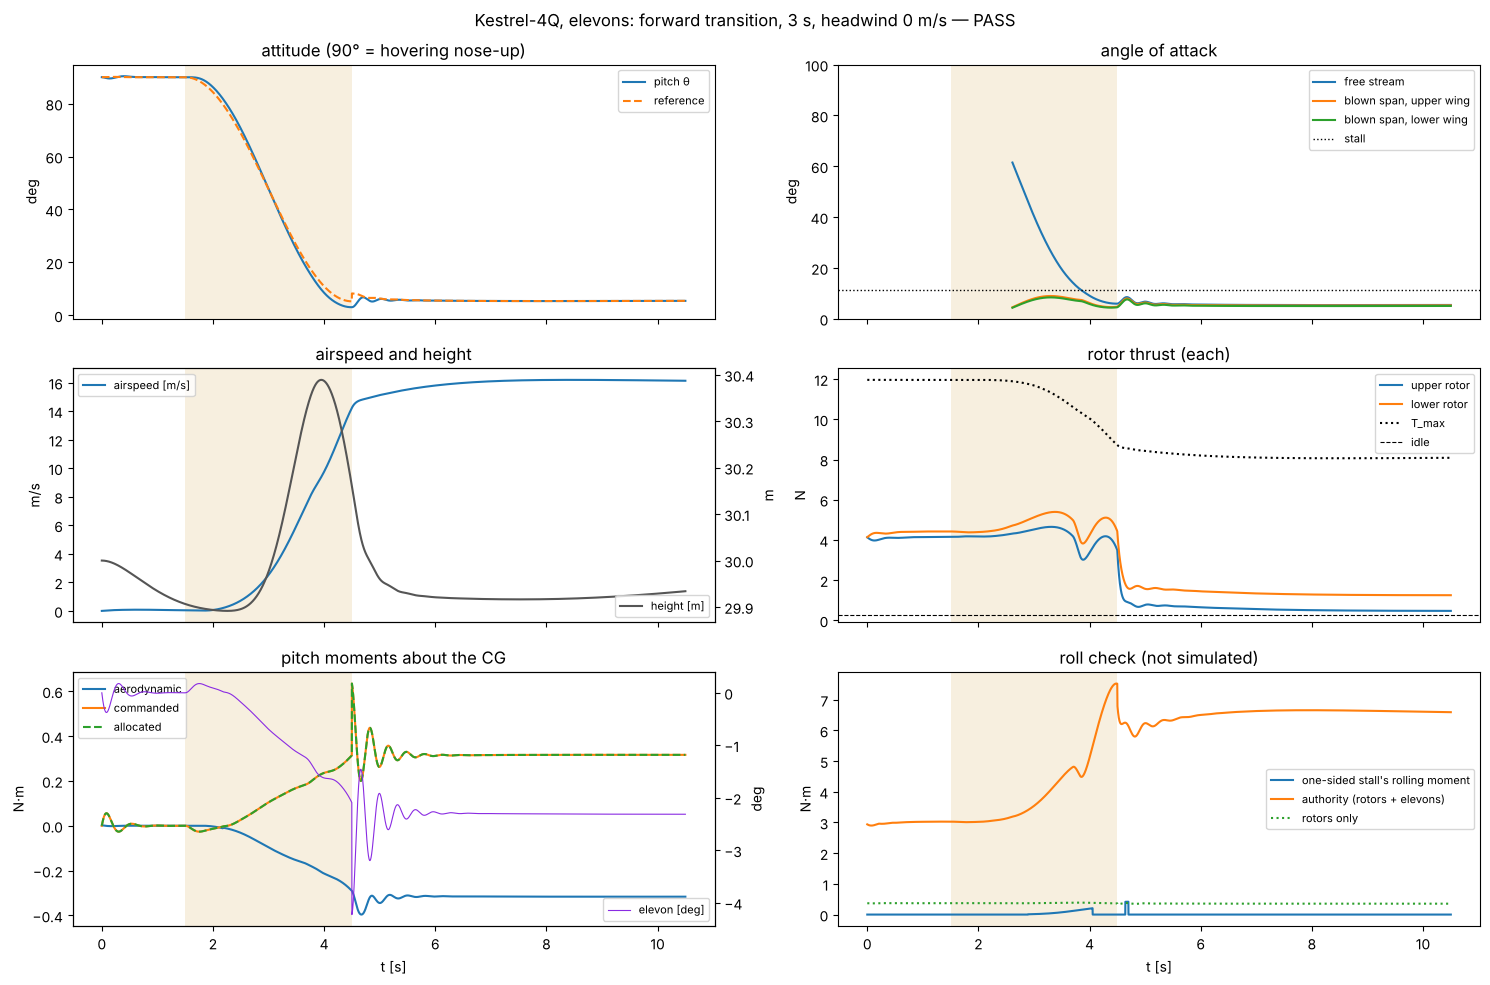

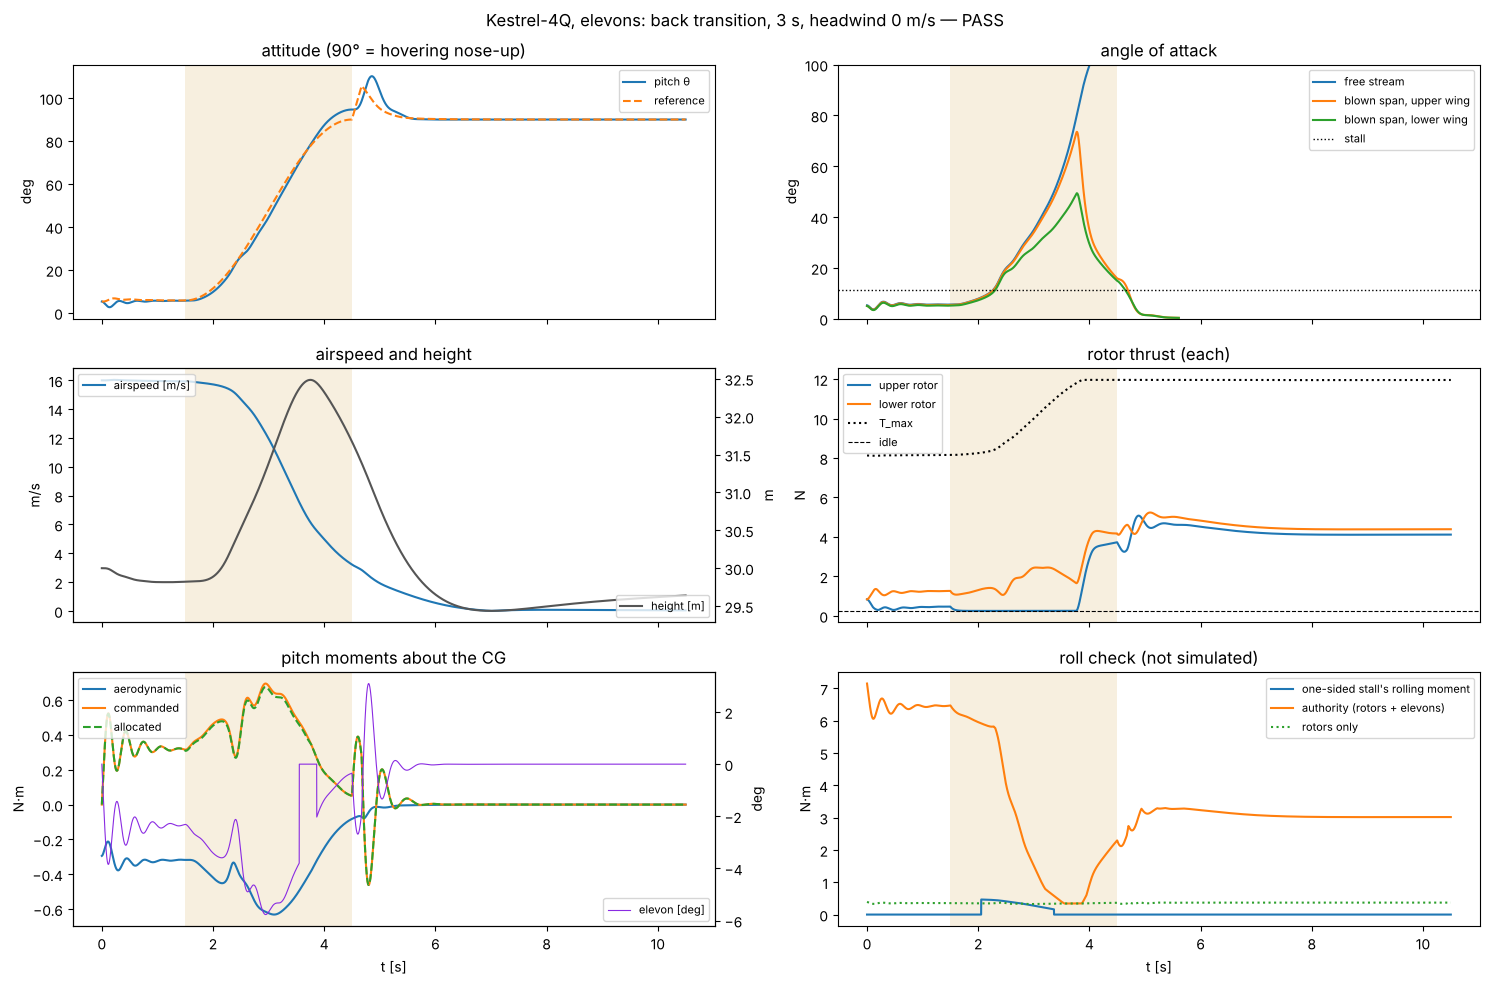

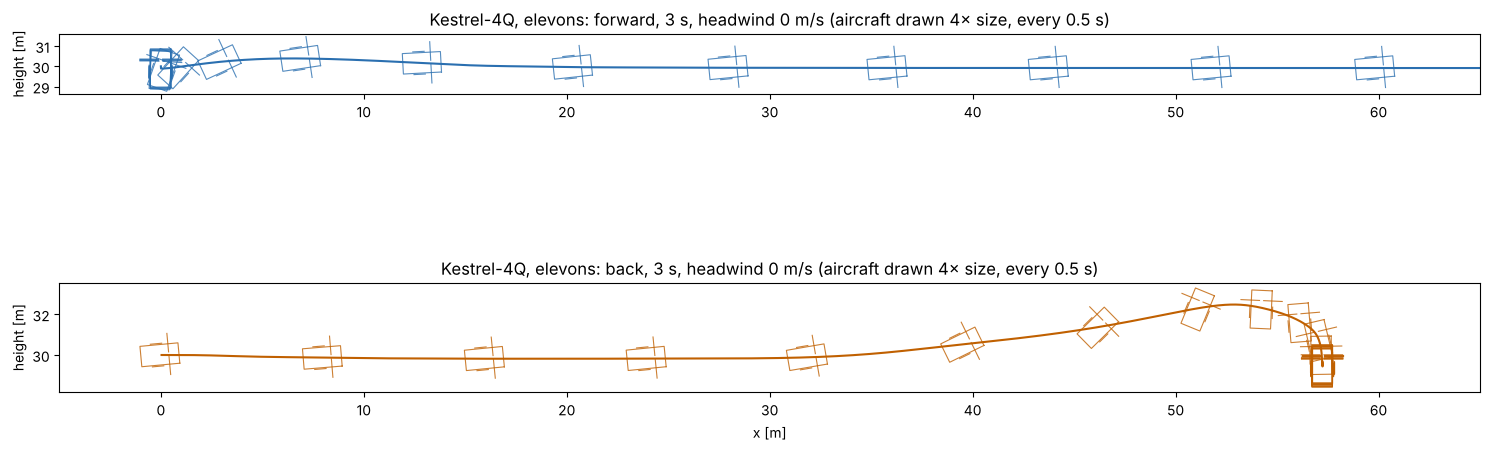

,height loss [m],height gain [m],pitch error max [deg],α free-stream max in transition [deg],"time stalled, free stream [s]",α blown max while stalled [deg],moment shortfall [s],collective given way [s],least pitch margin,peak rotor thrust / T_max,...,speed at the end [m/s],distance [m],energy [Wh],duration [s],hover reached at [s],holds height,holds attitude,roll holds,diverged at [s],pass
forward,0.108397,0.389127,2.46243,46.093714,0.952,8.96512,0.0,0.0,0.821535,0.554913,...,16.130228,108.408906,0.533587,10.5,NaN,True,True,True,NaN,True
back,0.563704,2.486073,4.654027,122.943503,1.502,73.480119,0.0,2.308,0.767543,0.437897,...,0.040785,57.21126,0.528044,10.5,6.062,True,True,True,NaN,True


In [12]:
VEH = kt.make_vehicle(P, aero=A, name="Kestrel-4Q, elevons")
NOM = {k: kt.simulate(VEH, k, t_tr=3.0) for k in ("forward", "back")}
for ep in NOM.values():
    kd.episode_figure(ep, VEH); plt.show()
kd.path_figure(list(NOM.values()), VEH, x_max=65); plt.show()
display(pd.DataFrame({k: ep.metrics for k, ep in NOM.items()}).T)

**The matrix.** Three vehicles — the baseline with elevons, the same with the rotors as the only effectors (the
minimal concept of the specification), and the heavy one (2.0 kg: a 0.3 kg payload at the quarter chord, the CG
moved aft) — both directions, three schedule lengths, still air and a 6 m/s headwind. Then a 3 m/s vertical gust in
the middle of the pitch schedule.

In [13]:
VEHICLES = {"elevons": VEH, "rotors only": kt.make_vehicle(P, aero=A, elevons=False, name="Kestrel-4Q, rotors only"),
            "2.0 kg, CG aft": kt.make_vehicle(P, aero=A, extra_kg=0.3, name="Kestrel-4Q, 2.0 kg")}
print({k: f"{v.mass:.2f} kg, CG {v.x_cg * 1000:.0f} mm, static margin {kf.neutral_point(P, x_cg=v.x_cg, a=A)['static_margin']:.3f}" for k, v in VEHICLES.items()})
durs = (1.5, 3.0) if QUICK else (1.5, 3.0, 5.0)
MAT, EPS = kt.matrix(VEHICLES, durations=durs, headwinds=(0.0, 6.0), progress=True)
cols = ["height loss [m]", "height gain [m]", "pitch error max [deg]", "time stalled, free stream [s]", "α blown max while stalled [deg]",
        "moment shortfall [s]", "least pitch margin", "peak rotor thrust / T_max", "elevon max [deg]", "roll demand / authority",
        "roll demand / rotors' authority", "pass"]
display(MAT[cols].astype({c: float for c in cols if c != "pass"}).round(2))
VER = kt.verdict(MAT)
for k, v in VER.items():
    print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
MAT.to_csv(OUT / "transition_matrix.csv")

{'elevons': '1.69 kg, CG 215 mm, static margin 0.096', 'rotors only': '1.69 kg, CG 215 mm, static margin 0.096', '2.0 kg, CG aft': '1.99 kg, CG 218 mm, static margin 0.074'}


transitions:   0%|          | 0/36 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
vehicle        direction t_tr [s] headwind [m/s]                                                                                                                                                                      
elevons        forward   1.5      0.0                        3.26             0.38                   7.86                           0.28                             5.54                   0.0                0.74   
                                  6.0                        0.31             0.09                   4.52                           1.12                            19.29                   0.0                0.83   
                         3.0      0.0                        0.11             0.39                   2.46                           0.95                             8.97                   0.0                0.82   
                                  6.0                        0.45             0.09                   1.91                           2.50                            19.37                   0.0                0.81   
                         5.0      0.0                        1.12             0.37                   1.55                           2.55                            15.11                   0.0                0.77   
                                  6.0                        1.44             0.43                   1.31                           4.47                            20.81                   0.0                0.80   
               back      1.5      0.0                        0.31             1.60                   7.51                           0.98                            75.36                   0.0                0.66   
                                  6.0                        0.18             1.60                   7.51                           0.98                            75.36                   0.0                0.66   
                         3.0      0.0                        0.56             2.49                   4.65                           1.50                            73.48                   0.0                0.77   
                                  6.0                        0.18             2.49                   4.65                           1.50                            73.48                   0.0                0.77   
                         5.0      0.0                        0.93             3.40                   2.35                           1.84                            61.55                   0.0                0.83   
                                  6.0                        0.46             3.40                   2.35                           1.84                            61.55                   0.0                0.83   
rotors only    forward   1.5      0.0                        0.79             0.29                   7.84                           0.27                             5.51                   0.0                0.56   
                                  6.0                        0.18             0.14                   4.43                           1.10                            19.06                   0.0                0.71   
                         3.0      0.0                        0.11             0.43                   2.44                           0.92                             8.80                   0.0                0.76   
                                  6.0                        0.22             0.14                   1.96                           2.45                            19.15                   0.0                0.75   
                         5.0      0.0                        0.71             0.41                   1.69                           2.44                            14.77           

2.0 kg, CG aft: 11 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails holds height, holds attitude
elevons: 11 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails holds height
rotors only: 3 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails roll holds
   - forward 1.5 s, headwind 6 m/s: fails roll holds
   - forward 5 s, headwind 6 m/s: fails roll holds
   - back 1.5 s, headwind 0 m/s: fails roll holds
   - back 1.5 s, headwind 6 m/s: fails roll holds
   - back 3 s, headwind 0 m/s: fails roll holds
   - back 3 s, headwind 6 m/s: fails roll holds
   - back 5 s, headwind 0 m/s: fails roll holds
   - back 5 s, headwind 6 m/s: fails roll holds


In [14]:
GUST = {(k, g): kt.simulate(VEH, k, t_tr=3.0, gust_up=g) for k in ("forward", "back") for g in (3.0, -3.0)}
display(pd.DataFrame({f"{k}, gust {g:+g} m/s": ep.metrics for (k, g), ep in GUST.items()}).T[cols])

,height loss [m],height gain [m],pitch error max [deg],"time stalled, free stream [s]",α blown max while stalled [deg],moment shortfall [s],least pitch margin,peak rotor thrust / T_max,elevon max [deg],roll demand / authority,roll demand / rotors' authority,pass
"forward, gust +3 m/s",0.108397,0.370516,2.404143,0.728,18.99667,0.0,0.823197,0.558154,4.183446,0.067814,1.119177,True
"forward, gust -3 m/s",0.180222,0.10307,2.793787,0.718,9.980371,0.0,0.836622,0.599041,3.88185,0.041451,0.566733,True
"back, gust +3 m/s",0.815825,3.480875,5.328361,1.582,72.366569,0.0,0.683348,0.421986,7.875609,0.317925,1.36386,True
"back, gust -3 m/s",0.402473,1.713764,4.696372,1.436,73.326809,0.0,0.767814,0.428229,5.76631,0.296761,1.36386,True


**The back transition's strategies.** Pitching up from the cruise, the wing first lifts the aircraft (the balloon);
the height loop then cuts the thrust, the slipstream fades, the blown span stalls with the rest and the rotors near
idle have little room for torque. Two remedies: slow down first (enter at 13 m/s instead of 16), or keep a floor
under the collective through the pitch schedule (half the hover thrust).

In [15]:
STRAT = {}
for ve in (16.0, 13.0):
    for fl in (0.0, 0.5):
        for el, veh in (("elevons", VEH), ("rotors only", VEHICLES["rotors only"])):
            STRAT[(el, ve, fl)] = kt.simulate(veh, "back", t_tr=3.0, V_entry=ve, floor=fl).metrics
ST = pd.DataFrame(STRAT).T
ST.index.names = ["effectors", "entry speed [m/s]", "collective floor"]
display(ST[cols])

,,,height loss [m],height gain [m],pitch error max [deg],"time stalled, free stream [s]",α blown max while stalled [deg],moment shortfall [s],least pitch margin,peak rotor thrust / T_max,elevon max [deg],roll demand / authority,roll demand / rotors' authority,pass
effectors,entry speed [m/s],collective floor,,,,,,,,,,,,
elevons,16.0,0.0,0.563704,2.486073,4.654027,1.502,73.480119,0.0,0.767543,0.437897,5.76977,0.279912,1.36386,True
rotors only,16.0,0.0,1.553317,5.491672,4.505333,1.472,72.256826,0.0,0.682712,0.424082,0.0,1.796607,1.796607,False
elevons,16.0,0.5,0.184943,11.79642,3.827278,1.954,33.452226,0.0,0.779909,0.366149,5.136526,0.129454,1.834248,False
rotors only,16.0,0.5,0.114818,15.741021,3.266835,1.744,27.691691,0.0,0.627153,0.433657,0.0,2.362829,2.362829,False
elevons,13.0,0.0,0.625236,0.075871,4.300513,1.832,43.926041,0.0,0.783911,0.418678,5.086538,0.224257,0.904635,True
rotors only,13.0,0.0,0.254608,0.997246,4.409534,1.508,61.974899,0.0,0.742005,0.42054,0.0,1.060931,1.060931,False
elevons,13.0,0.5,1.426482,5.146756,4.213055,1.922,41.927504,0.0,0.781172,0.423697,5.119104,0.169144,1.175598,True
rotors only,13.0,0.5,2.032691,7.632559,4.001971,1.948,37.664748,0.0,0.742005,0.425505,0.0,1.393073,1.393073,False


**Check — iteration 2, the transition model.** The first pass (rotors only, every schedule, the cruise entry) fails;
the loop turns three knobs — elevons on the blown outer panels, no pitch-over faster than 3 s, the back transition
entered at 13 m/s — and the matrix is read again on those rules.

In [16]:
def passes(df, **sel):
    sub = df
    for lvl, val in sel.items():
        sub = sub[sub.index.get_level_values(lvl).isin(val if isinstance(val, (tuple, list)) else [val])]
    return int(sub["pass"].astype(bool).sum()), len(sub)
ro_all, el_all = passes(MAT, vehicle="rotors only"), passes(MAT, vehicle="elevons")
el_slow = passes(MAT, vehicle="elevons", **{"t_tr [s]": [d for d in durs if d >= 3.0]})
back13 = ST.xs(("elevons", 13.0, 0.0))
CHK2 = [kl.check("rotors only, every schedule, cruise entry: passing", ro_all[0] / ro_all[1], "≥", 1.0, note=f"{ro_all[0]} of {ro_all[1]}: fails on roll"),
        kl.check("elevons, every schedule: passing", el_all[0] / el_all[1], "≥", 1.0, note=f"{el_all[0]} of {el_all[1]}: the 1.5 s pitch-over sinks"),
        kl.check("elevons, schedules ≥ 3 s: passing", el_slow[0] / el_slow[1], "≥", 1.0, note=f"{el_slow[0]} of {el_slow[1]}"),
        kl.check("height loss in a transition [m]", float(MAT.xs("elevons", level=0).xs(3.0, level="t_tr [s]")["height loss [m]"].astype(float).max()), note="3 s schedules"),
        kl.check("back transition entered at 13 m/s: height gain [m]", float(back13["height gain [m]"]), "≤", float(kt.CRITERIA["height gain, back [m]"])),
        kl.check("back at 13 m/s: blown span's α while stalled [deg]", float(back13["α blown max while stalled [deg]"]), "≤", 45.0, note="the regime the model knows least"),
        kl.check("gusts ±3 m/s, both ways: passing", sum(bool(ep.metrics["pass"]) for ep in GUST.values()) / len(GUST), "≥", 1.0)]
show_checks(CHK2, "iteration 2 — the transitions")
LOG.add("2 — transition model", changed="elevons; pitch-over ≥ 3 s; back entry 13 m/s", source="kestrel_transition (model polar)", checks=CHK2,
        **{"take-off mass [kg]": VEH.mass, "static margin [chords]": NP["static_margin"], "hover thrust / weight": HP["T_W"], "stall speed [m/s]": VS, "Cd0": POL.cd0,
           "L/D at the cruise": c16["L/D"], "cruise power [W]": c16["electrical [W]"], "endurance at the cruise [min]": c16["endurance [min]"],
           "transitions passing": f"{el_slow[0]} of {el_slow[1]} (≥ 3 s)"})

iteration 2 — the transitions,value,target,holds,note
check,,,,
"rotors only, every schedule, cruise entry: passing",0.25,≥ 1,✘,3 of 12: fails on roll
"elevons, every schedule: passing",0.917,≥ 1,✘,11 of 12: the 1.5 s pitch-over sinks
"elevons, schedules ≥ 3 s: passing",1,≥ 1,✔,8 of 8
height loss in a transition [m],0.564,≤ 3,✔,3 s schedules
back transition entered at 13 m/s: height gain [m],0.0759,≤ 10,✔,
back at 13 m/s: blown span's α while stalled [deg],43.9,≤ 45,✔,the regime the model knows least
"gusts ±3 m/s, both ways: passing",1,≥ 1,✔,


iteration 2 — the transitions: 5 of 7 hold — failing: rotors only, every schedule, cruise entry: passing, elevons, every schedule: passing


{'iteration': '2 — transition model',
 'what changed': 'elevons; pitch-over ≥ 3 s; back entry 13 m/s',
 'source': 'kestrel_transition (model polar)',
 'take-off mass [kg]': 1.6862063482324605,
 'static margin [chords]': np.float64(0.09552453569798042),
 'hover thrust / weight': 2.893213038200698,
 'stall speed [m/s]': 10.910411381833859,
 'Cd0': 0.06654869740668531,
 'L/D at the cruise': np.float64(4.956275655891227),
 'cruise power [W]': np.float64(110.21562126390147),
 'endurance at the cruise [min]': np.float64(21.27030608834237),
 'transitions passing': '8 of 8 (≥ 3 s)',
 'checks holding': '5 / 7',
 'failing': 'rotors only, every schedule, cruise entry: passing, elevons, every schedule: passing'}

## 7. The transitions in CFD

The polar of section 5 is an estimate: attached flow blended into a flat plate, the slipstream from momentum theory,
each wing part on its own. At the points the aircraft actually flies — from the nominal transitions, the first time
the free-stream angle of attack passes 80, 60, 45, 30, 20, 15 and 10° going forward and coming back, plus the hover —
Aeromant solves the airframe in steady RANS (k-ω SST) with the **four propellers as rotor disks** at the rpm Boreas
gives for each pair's thrust at that inflow (`aircraft_quad_rotor_disks`). The bare airframe from 0 to 90° at 10 m/s
is the reference stall. Solved, the CFD's coefficients minus the model's at the same points become a correction the
transition model adds to its airframe forces, and the transitions are flown again. Without OpenFOAM the cases are
prepared and listed as NOT RUN (`VEGETA_SKIP_OPENFOAM=1`). A case that fails or diverges is a result too: it is listed
with its reason and left out of the correction — the first campaign lost all fourteen blown cases to the solver's
numerics (since changed in the template) and solved the ten bare ones.

In [17]:
PTS = kcfd.points(list(NOM.values()), mass_kg=VEH.mass)
CSPEC = kcfd.specs(PTS, sweep=not QUICK)
CFDT = kcfd.not_run_table(CSPEC)
CFD_SOLVED = False
if RUN_CFD:
    try:
        CASES = kcfd.plan(RUNS / "cfd", PTS, x_cg_m=VEH.x_cg, z_cg_m=VEH.z_cg, sweep=not QUICK)
        names = list(CASES)
        res = aeromant.run_cases([CASES[n] for n in names], jobs=1, processors=4, progress=True, cache=True)
        CFDT = kcfd.table(dict(zip(names, res)), CSPEC)           # solved / diverged / FAILED per case: a failure is a result
        CFD_SOLVED = bool((CFDT["status"] == "solved").any())
        print(kcfd.summary(CFDT)["line"])
        kcfd.save_records(CFDT, kcfd.RESULTS_JSON, key="4Q-1", meta={"source": "38_kestrel", "quality": "screening", "aircraft": "Kestrel-4Q (Part I CAD)"})
    except Exception as exc:                                   # no OpenFOAM, no CAD kernel: the plan stays NOT RUN
        print("CFD not run:", exc)
STATUS["CFD"] = kcfd.summary(CFDT)["line"] if CFD_SOLVED else "NOT RUN here"
display(CFDT)
CFDT.to_csv(OUT / "cfd_cases.csv")

,status,α [deg],V [m/s],source,template,rpm upper,rpm lower,Re (chord)
"forward 3 s: α 53°, 1.5 m/s, T 4.38/4.85 N",NOT RUN,52.894182,1.502634,forward 3 s,aircraft_quad_rotor_disks,6959.416668,7323.375427,14408.817654
"forward 3 s: α 45°, 2.1 m/s, T 4.47/5.02 N",NOT RUN,44.904703,2.100062,forward 3 s,aircraft_quad_rotor_disks,7069.55626,7488.626383,20137.576076
"forward 3 s: α 30°, 3.8 m/s, T 4.64/5.33 N",NOT RUN,29.973069,3.822928,forward 3 s,aircraft_quad_rotor_disks,7349.58457,7860.588523,36658.217085
"forward 3 s: α 20°, 5.8 m/s, T 4.58/5.36 N",NOT RUN,19.995271,5.808294,forward 3 s,aircraft_quad_rotor_disks,7546.298155,8109.622579,55695.971179
"forward 3 s: α 15°, 7.3 m/s, T 4.28/5.08 N",NOT RUN,14.997513,7.3228,forward 3 s,aircraft_quad_rotor_disks,7548.470859,8130.479978,70218.628002
"forward 3 s: α 10°, 9.3 m/s, T 3.10/3.94 N",NOT RUN,9.988898,9.285929,forward 3 s,aircraft_quad_rotor_disks,6965.549177,7631.274908,89043.15222
"back 3 s: α 80°, 6.0 m/s, T 0.27/1.66 N",NOT RUN,80.130305,6.032658,back 3 s,aircraft_quad_rotor_disks,1889.195452,4315.347784,57847.405862
"back 3 s: α 60°, 7.7 m/s, T 0.25/2.08 N",NOT RUN,60.038309,7.692476,back 3 s,aircraft_quad_rotor_disks,2378.065278,5106.871166,73763.470179
"back 3 s: α 45°, 9.9 m/s, T 0.25/2.45 N",NOT RUN,45.073565,9.943418,back 3 s,aircraft_quad_rotor_disks,3199.348591,5983.138945,95347.845625
"back 3 s: α 30°, 13.0 m/s, T 0.25/2.07 N",NOT RUN,30.020389,13.024933,back 3 s,aircraft_quad_rotor_disks,4478.501063,6526.059131,124896.61674


**Plug in — iteration 3.** Whatever CFD exists for this airframe is read from `designs/data/kestrel_cfd_results.json`:
this notebook's own run above, or the test campaign of **notebook 40** (`40_kestrel_tests`, every case at the quality
it is given), or a run on another machine. The bare sweep is read against the model's polar first — the lift slope,
CL max and where it is, the zero-lift drag, the static margin from Cmα — then the correction is built: from the blown
cases if any solved (in α and the slipstream ratio μ), else from the bare sweep (in α, the model keeping the blowing),
and the matrix is flown again on it. The verdicts, model and CFD, stand side by side.

campaign: {'source': '38_kestrel run on an OpenFOAM machine (uploaded notebook), Part I points, screening quality, 400 iterations', 'aircraft': 'Kestrel-4Q (round struts, NACA 0012, no elevons in the CAD)', 'quality': 'screening', 'date': '2026-10-16'}


,solved,diverged,FAILED,NOT RUN,n,solved with rotor disks,solved bare,with rotor disks
cases,10,2,12,0,24,0,10,14


,status,note,rotor disks,α [deg],V [m/s]
"forward 3 s: α 53°, 1.5 m/s, T 4.63/4.64 N",diverged,diverged: |coefficients| beyond 1e90,True,52.8861,1.50599
"forward 3 s: α 45°, 2.1 m/s, T 4.73/4.80 N",FAILED,step solver failed (log not in the notebook),True,44.998494,2.095608
"forward 3 s: α 30°, 3.8 m/s, T 4.91/5.11 N",FAILED,step solver failed (log not in the notebook),True,29.934512,3.832142
"forward 3 s: α 20°, 5.8 m/s, T 4.85/5.14 N",diverged,diverged: |coefficients| beyond 1e90,True,19.948691,5.824897
"forward 3 s: α 15°, 7.3 m/s, T 4.54/4.88 N",FAILED,step solver failed (log not in the notebook),True,14.964813,7.345324
"forward 3 s: α 10°, 9.3 m/s, T 3.29/3.79 N",FAILED,step solver failed (log not in the notebook),True,9.985109,9.312609
"back 3 s: α 80°, 6.1 m/s, T 0.29/1.58 N",FAILED,step solver failed (log not in the notebook),True,80.069949,6.134746
"back 3 s: α 60°, 7.8 m/s, T 0.25/1.98 N",FAILED,step solver failed (log not in the notebook),True,60.063531,7.77732
"back 3 s: α 45°, 10.0 m/s, T 0.25/2.35 N",FAILED,step solver failed (log not in the notebook),True,45.013034,10.013281
"back 3 s: α 30°, 13.0 m/s, T 0.25/2.02 N",FAILED,step solver failed (log not in the notebook),True,30.015775,13.038355


,α [deg],CL CFD,CL model,ΔCL,CD CFD,CD model,ΔCD,Cm CFD,Cm model,ΔCm,converged
"bare airframe, α 0°, 10 m/s",0.0,-0.048798,0.0,-0.048798,0.053229,0.066549,-0.01332,0.02103,0.002131,0.018899,False
"bare airframe, α 5°, 10 m/s",5.0,0.319246,0.352045,-0.032799,0.08082,0.075034,0.005786,-0.030379,-0.049811,0.019432,False
"bare airframe, α 10°, 10 m/s",10.0,0.507562,0.5645,-0.056938,0.134349,0.101314,0.033035,-0.07048,-0.084367,0.013887,False
"bare airframe, α 15°, 10 m/s",15.0,0.541091,0.379896,0.161195,0.197516,0.151589,0.045927,-0.088153,-0.074912,-0.013241,False
"bare airframe, α 20°, 10 m/s",20.0,0.571487,0.42127,0.150217,0.296818,0.218724,0.078094,-0.132917,-0.100202,-0.032715,False
"bare airframe, α 30°, 10 m/s",30.0,0.571837,0.576299,-0.004462,0.45992,0.399271,0.060649,-0.120245,-0.172552,0.052307,False
"bare airframe, α 45°, 10 m/s",45.0,0.614804,0.684567,-0.069763,0.752433,0.751116,0.001317,-0.203169,-0.292263,0.089094,False
"bare airframe, α 60°, 10 m/s",60.0,0.449682,0.605558,-0.155876,0.935665,1.115406,-0.179741,-0.241783,-0.403025,0.161242,False
"bare airframe, α 75°, 10 m/s",75.0,0.207578,0.354231,-0.146653,0.856935,1.388556,-0.531621,-0.21171,-0.481212,0.269502,False
"bare airframe, α 90°, 10 m/s",90.0,0.060415,0.0,0.060415,0.767666,1.489763,-0.722097,-0.229449,-0.509726,0.280277,False


,CFD,model
CLα [1/rad],3.188,3.234
CL max,0.615,0.685
α at CL max [deg],45.000,45.000
CL max below 20°,0.541,0.564
α of it [deg],15.000,10.000
CD at the lowest α,0.053,0.067
Cmα [1/rad],-0.524,-0.496
static margin from Cmα [chords],0.164,0.153


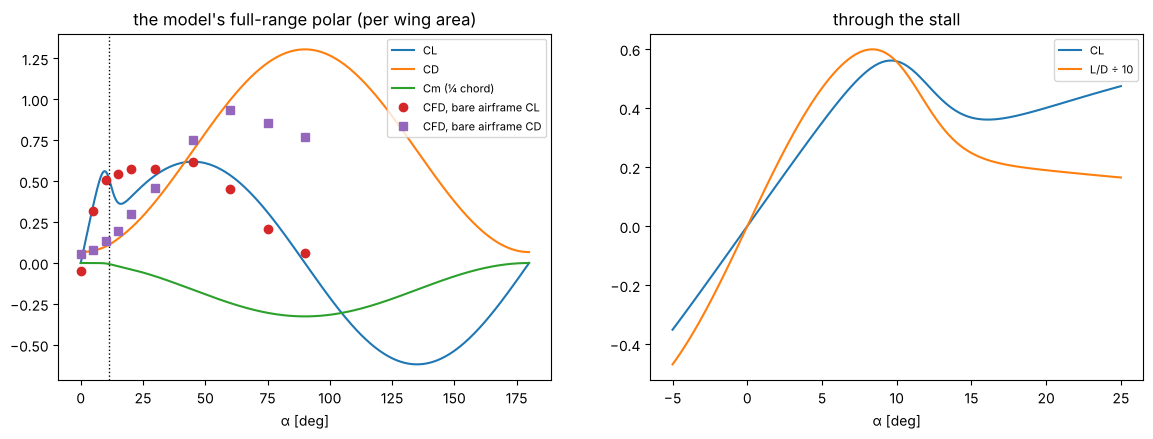

correction from the sweep (10 points)


transitions:   0%|          | 0/24 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
vehicle          direction t_tr [s] headwind [m/s]                                                                                                                                                                      
elevons, CFD     forward   1.5      0.0                        0.86             0.12                   7.39                           0.27                             5.55                   0.0                0.76   
                                    6.0                        0.42             0.04                   4.30                           1.09                            20.81                   0.0                0.85   
                           3.0      0.0                        0.16             0.42                   2.25                           0.93                             8.92                   0.0                0.82   
                                    6.0                        0.30             0.09                   2.27                           2.38                            20.81                   0.0                0.82   
                           5.0      0.0                        0.60             0.36                   2.12                           2.38                            14.85                   0.0                0.79   
                                    6.0                        0.71             0.17                   1.45                           4.27                            20.91                   0.0                0.82   
                 back      1.5      0.0                        0.29             0.82                   6.40                           0.84                            76.49                   0.0                0.74   
                                    6.0                        0.21             0.82                   6.40                           0.84                            76.49                   0.0                0.74   
                           3.0      0.0                        0.30             1.31                   3.31                           1.41                            63.29                   0.0                0.81   
                                    6.0                        0.21             1.31                   3.31                           1.41                            63.29                   0.0                0.81   
                           5.0      0.0                        0.26             1.34                   1.92                           2.12                            48.45                   0.0                0.85   
                                    6.0                        0.24             1.34                   1.92                           2.12                            48.45                   0.0                0.85   
rotors only, CFD forward   1.5      0.0                        0.73             0.17                   7.45                           0.26                             5.52                   0.0                0.59   
                                    6.0                        0.32             0.10                   4.22                           1.07                            20.70                   0.0                0.74   
                           3.0      0.0                        0.11             0.46                   2.19                           0.90                             8.79                   0.0                0.76   
                                    6.0                        0.23             0.16                   2.31                           2.35                            20.70                   0.0                0.77   
                           5.0      0.0                        0.35             0.40                   2.09                           2.31        

,model,CFD (sweep)
elevons,11 of 12,12 of 12
rotors only,3 of 12,1 of 12


elevons, CFD: 12 of 12 pass
rotors only, CFD: 1 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails roll holds
   - forward 1.5 s, headwind 6 m/s: fails roll holds
   - forward 3 s, headwind 0 m/s: fails roll holds
   - forward 3 s, headwind 6 m/s: fails roll holds
   - forward 5 s, headwind 0 m/s: fails roll holds
   - back 1.5 s, headwind 0 m/s: fails roll holds
   - back 1.5 s, headwind 6 m/s: fails roll holds
   - back 3 s, headwind 0 m/s: fails roll holds
   - back 3 s, headwind 6 m/s: fails roll holds
   - back 5 s, headwind 0 m/s: fails roll holds
   - back 5 s, headwind 6 m/s: fails roll holds


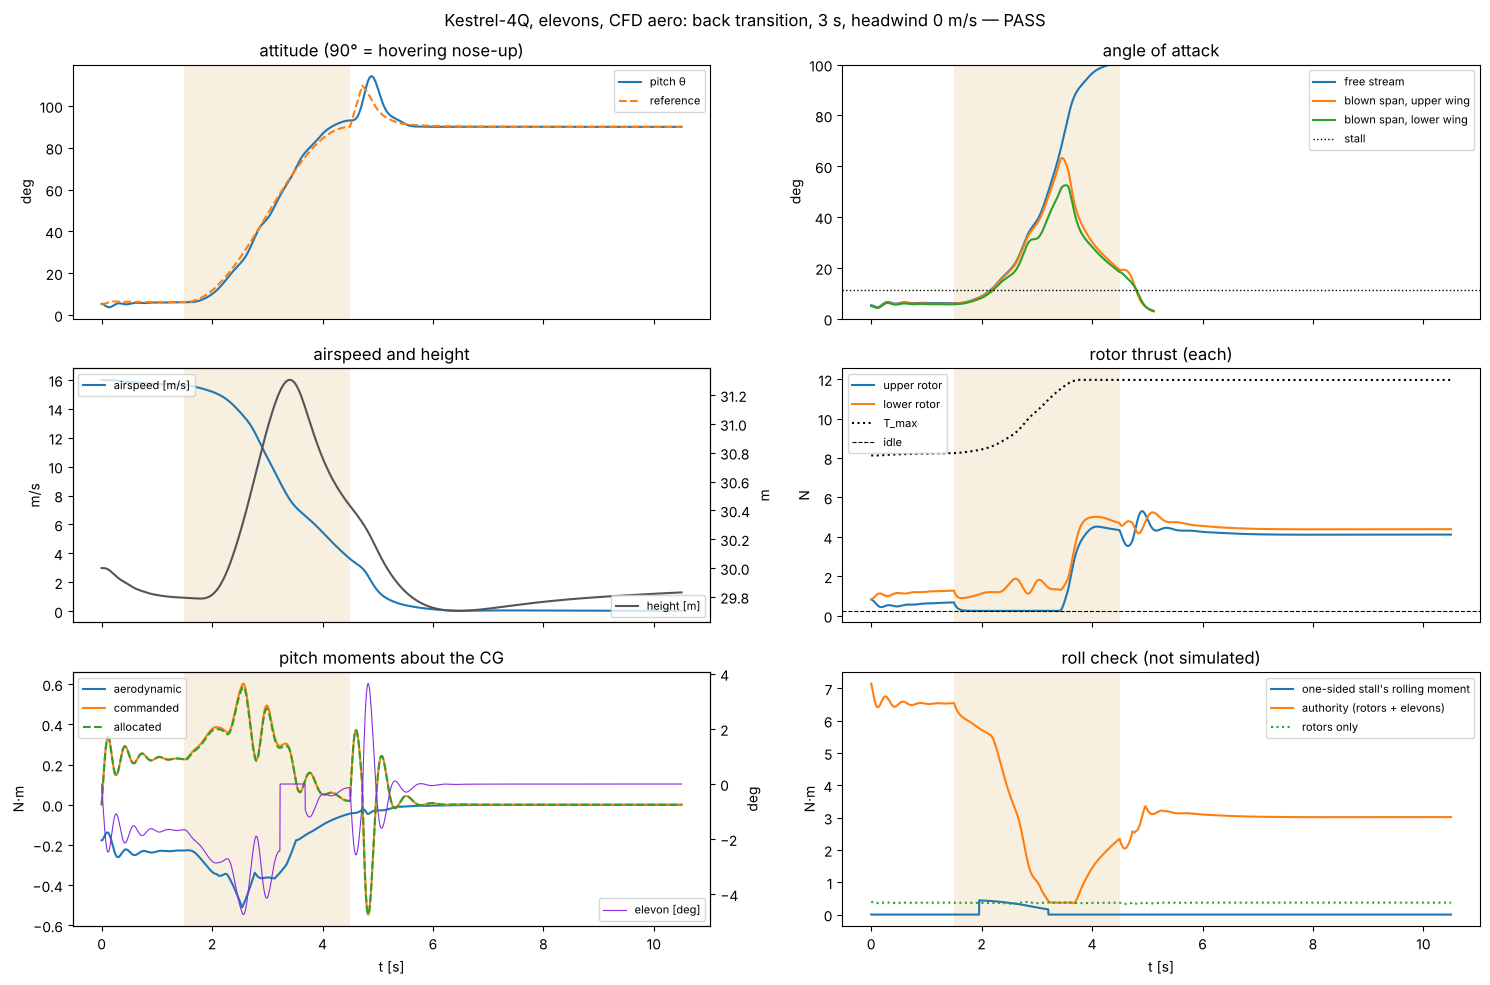

the stall's peak on the sweep's angles: CFD CL 0.54 at 15°, model 0.56 at 10° (the model's polar peaks at 0.81 at 11°, between the sweep's angles: a 5° grid cannot see it, notebook 40's fine sweep can)
if the CFD's 0.54 is the peak: stall speed 13.3 m/s against the model's 10.9 — the 13 m/s back entry would be 0.97 × the stall, not 1.19 ×; deep in the stall the CFD holds 0.61 at 45° where the model gives 0.68
lift slope: CFD 3.19, model 3.23 /rad; Cd0: CFD 0.053, model 0.067; static margin from Cmα: CFD 0.164, model 0.153


iteration 3 — the CFD plugged in,value,target,holds,note
check,,,,
"lift slope, CFD / model",0.986,0.85 – 1.15,✔,
"Cd0, CFD / model",0.8,≤ 1.2,✔,"the model may be conservative, not optimistic"
"CL max below 20° on the sweep's angles, CFD / model",0.959,≥ 0.8,✔,a 5° grid: the peak itself waits for the fine sweep (notebook 40)
"CL max below 20°, CFD / the model's polar peak",0.668,≥ 0.8,✘,the model's 0.81 against the CFD's 0.54 at 15°: the stall speed and the entry rule han...
static margin from the CFD's Cmα [chords],0.164,0.05 – 0.2,✔,
blown cases solved,0,≥ 1,✘,the transition points with rotor disks: the question this CFD was set up for
transitions on the CFD's aerodynamics (elevons): passing,1,≥ 0.666667,✔,all but the 1.5 s pitch-over


iteration 3 — the CFD plugged in: 5 of 7 hold — failing: CL max below 20°, CFD / the model's polar peak, blown cases solved


In [18]:
PI = kcfd.plug_in(VEH, kcfd.RESULTS_JSON, "4Q-1")
CAMP = PI["campaign"]
VER_CFD = None; CMP_SWEEP = None; SWEEP_NUM = {}
if CAMP:
    print("campaign:", CAMP.get("meta"))
    display(pd.Series(CAMP["summary"], name="cases").to_frame().T)
    fails = {k: v for k, v in CAMP["statuses"].items() if v["status"] in ("FAILED", "diverged")}
    if fails:
        display(pd.DataFrame(fails).T)
    RT = kcfd.records_table(CAMP["records"])
    CMP_SWEEP = kcfd.sweep_comparison(RT, VEH)
    if len(CMP_SWEEP):
        display(CMP_SWEEP.drop(columns=["note"]).astype({"α [deg]": float}).round(3))
        SWEEP_NUM = kcfd.sweep_numbers(CMP_SWEEP)
        display(pd.DataFrame(SWEEP_NUM).round(3))
        kd.polar_figure(POL, RT); plt.show()
if PI["airframe"] is None:
    print("No usable CFD for this airframe yet: the transitions stand on the model's polar. Run notebook 40 (or this one) where "
          "OpenFOAM is installed; the campaign's solved cases are plugged in here on the next run.")
else:
    CORR = PI["airframe"]
    print(f"correction from the {CORR.source} ({len(CORR.samples)} points)")
    VEH_CFD = kt.make_vehicle(P, aero=A, airframe=CORR, name="Kestrel-4Q, elevons, CFD aero")
    VEHR_CFD = kt.make_vehicle(P, aero=A, airframe=CORR, elevons=False, name="Kestrel-4Q, rotors only, CFD aero")
    MAT_CFD, EPS_CFD = kt.matrix({"elevons, CFD": VEH_CFD, "rotors only, CFD": VEHR_CFD}, durations=durs, headwinds=(0.0, 6.0), progress=True)
    display(MAT_CFD[cols].astype({c: float for c in cols if c != "pass"}).round(2))
    VER_CFD = kt.verdict(MAT_CFD)
    SIDE = pd.DataFrame({"model": {k: f"{v['passes']} of {v['of']}" for k, v in VER.items() if k in ("elevons", "rotors only")},
                         f"CFD ({CORR.source})": {k.replace(", CFD", ""): f"{v['passes']} of {v['of']}" for k, v in VER_CFD.items()}})
    display(SIDE)
    for k, v in VER_CFD.items():
        print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
    kd.episode_figure(EPS_CFD[("elevons, CFD", "back", 3.0, 0.0)], VEH_CFD); plt.show()
# the reiterated numbers: the CFD's stall against the model's, and what it does to the entry speed of the back transition
if SWEEP_NUM:
    clmax_cfd, clmax_mod = SWEEP_NUM["CFD"]["CL max below 20°"], SWEEP_NUM["model"]["CL max below 20°"]
    VS_CFD = math.sqrt(2 * VEH.weight / (ks.RHO0 * L["S_ref"] * clmax_cfd))
    print(f"the stall's peak on the sweep's angles: CFD CL {clmax_cfd:.2f} at {SWEEP_NUM['CFD']['α of it [deg]']:.0f}°, model {clmax_mod:.2f} at {SWEEP_NUM['model']['α of it [deg]']:.0f}° "
          f"(the model's polar peaks at {POL.cl_max:.2f} at {math.degrees(POL.alpha_stall):.0f}°, between the sweep's angles: a 5° grid cannot see it, notebook 40's fine sweep can)")
    print(f"if the CFD's {clmax_cfd:.2f} is the peak: stall speed {VS_CFD:.1f} m/s against the model's {VS:.1f} — the 13 m/s back entry would be {13.0 / VS_CFD:.2f} × the stall, "
          f"not {13.0 / VS:.2f} ×; deep in the stall the CFD holds {SWEEP_NUM['CFD']['CL max']:.2f} at {SWEEP_NUM['CFD']['α at CL max [deg]']:.0f}° where the model gives {SWEEP_NUM['model']['CL max']:.2f}")
    print(f"lift slope: CFD {SWEEP_NUM['CFD']['CLα [1/rad]']:.2f}, model {SWEEP_NUM['model']['CLα [1/rad]']:.2f} /rad; Cd0: CFD {SWEEP_NUM['CFD']['CD at the lowest α']:.3f}, "
          f"model {SWEEP_NUM['model']['CD at the lowest α']:.3f}; static margin from Cmα: CFD {SWEEP_NUM['CFD']['static margin from Cmα [chords]']:.3f}, model {SWEEP_NUM['model']['static margin from Cmα [chords]']:.3f}")
    CHK3 = [kl.check("lift slope, CFD / model", SWEEP_NUM["CFD"]["CLα [1/rad]"] / SWEEP_NUM["model"]["CLα [1/rad]"], "between", (0.85, 1.15)),
            kl.check("Cd0, CFD / model", SWEEP_NUM["CFD"]["CD at the lowest α"] / SWEEP_NUM["model"]["CD at the lowest α"], "≤", 1.2, note="the model may be conservative, not optimistic"),
            kl.check("CL max below 20° on the sweep's angles, CFD / model", clmax_cfd / clmax_mod, "≥", 0.8, note="a 5° grid: the peak itself waits for the fine sweep (notebook 40)"),
            kl.check("CL max below 20°, CFD / the model's polar peak", clmax_cfd / POL.cl_max, "≥", 0.8, note=f"the model's {POL.cl_max:.2f} against the CFD's {clmax_cfd:.2f} at {SWEEP_NUM['CFD']['α of it [deg]']:.0f}°: the stall speed and the entry rule hang on this"),
            kl.check("static margin from the CFD's Cmα [chords]", SWEEP_NUM["CFD"]["static margin from Cmα [chords]"], "between", (0.05, 0.20)),
            kl.check("blown cases solved", CAMP["summary"]["solved with rotor disks"], "≥", 1, note="the transition points with rotor disks: the question this CFD was set up for")]
    if VER_CFD:
        CHK3.append(kl.check("transitions on the CFD's aerodynamics (elevons): passing", VER_CFD["elevons, CFD"]["passes"] / VER_CFD["elevons, CFD"]["of"], "≥", (len(durs) - 1) / len(durs),
                             note="all but the 1.5 s pitch-over"))
    show_checks(CHK3, "iteration 3 — the CFD plugged in")
    LOG.add("3 — CFD plugged in", changed=f"the polar read against the CFD ({PI['source']} correction, {CAMP['summary']['solved']} solved cases)", source=CAMP.get("meta", {}).get("source", "campaign"),
            checks=CHK3, **{"take-off mass [kg]": VEH.mass, "static margin [chords]": SWEEP_NUM["CFD"]["static margin from Cmα [chords]"], "hover thrust / weight": HP["T_W"],
                            "stall speed [m/s]": VS_CFD, "Cd0": SWEEP_NUM["CFD"]["CD at the lowest α"], "L/D at the cruise": c16["L/D"], "cruise power [W]": c16["electrical [W]"],
                            "endurance at the cruise [min]": c16["endurance [min]"],
                            "transitions passing": (f"{VER_CFD['elevons, CFD']['passes']} of {VER_CFD['elevons, CFD']['of']}" if VER_CFD else "—")})
else:
    LOG.add("3 — CFD plugged in", changed="nothing: no campaign on file", source="—")

## 8. The truss, the propellers' gap under load, standing on the feet

The front view as a plane frame at a 4 g pull-up: the spars as beams through the pod (clamped there), the posts and
diagonals as pin-ended bars, the lift elliptic, less the wings' and the motors' inertia. Braced (posts and X), posts
only, no truss — and once more with the upper wing carrying 75 % of the lift (one wing stalling first). Then the
aircraft standing nose-up on its six feet: tip-over angles, the wind that tips it over, the touchdown.

In [19]:
BR = {"even lift": kst.compare_bracing(P, mass_kg=CI["mass_kg"]), "upper wing 75 %": kst.compare_bracing(P, mass_kg=CI["mass_kg"], upper_share=0.75)}
for k, v in BR.items():
    print(k); display(v.round(3))
display(pd.DataFrame(kst.frame(P, mass_kg=CI["mass_kg"], upper_share=0.75)["bars"]).round(2))
GS = kst.ground_stance(P, mass_kg=CI["mass_kg"], x_cg=CI["x_cg"], z_cg=CI["z_cg"])
display(pd.DataFrame(GS["edges"]).round(3))
display(pd.Series({k: v for k, v in GS.items() if k != "edges"}, name="standing").round(2).to_frame().T)

even lift


,spar peak moment [N·m],spar stress [MPa],spar reserve,"tip deflection, upper [mm]","tip deflection, lower [mm]","motor station, upper [mm]","motor station, lower [mm]",propeller gap change [mm],propeller gap under load [mm],least buckling margin,truss mass [g]
posts + X diagonals,0.667,11.504,34.769,-0.091,-0.091,0.035,0.035,-0.0,51.4,77.448,127.221
posts only,1.253,21.624,18.498,1.979,1.979,1.486,1.486,-0.0,51.4,inf,40.800
no truss (two cantilevers),1.253,21.624,18.498,1.979,1.979,1.486,1.486,0.0,51.4,inf,0.000


upper wing 75 %


,spar peak moment [N·m],spar stress [MPa],spar reserve,"tip deflection, upper [mm]","tip deflection, lower [mm]","motor station, upper [mm]","motor station, lower [mm]",propeller gap change [mm],propeller gap under load [mm],least buckling margin,truss mass [g]
posts + X diagonals,0.734,12.658,31.602,-0.146,-0.036,0.035,0.035,-0.000,51.400,575.14,127.221
posts only,1.581,27.268,14.669,1.907,2.052,1.486,1.486,0.001,51.401,inf,40.800
no truss (two cantilevers),3.017,52.050,7.685,6.377,-2.419,4.627,-1.656,6.283,57.683,inf,0.000


,member,length [m],force [N],Euler load [N],buckling margin,stress [MPa]
0,post,0.28,-2.41,1384.21,575.14,-0.11
1,diagonal,0.44,6.50,211.45,inf,0.41
2,diagonal,0.44,11.96,211.45,inf,0.76


,edge,distance [m],tip-over angle [deg]
0,"(-0.39, -0.14) – (+0.00, -0.29)",0.266,39.337
1,"(+0.00, -0.29) – (+0.39, -0.14)",0.266,39.337
2,"(+0.39, -0.14) – (+0.39, +0.14)",0.390,50.181
3,"(+0.39, +0.14) – (+0.00, +0.33)",0.301,42.762
4,"(+0.00, +0.33) – (-0.39, +0.14)",0.301,42.762
5,"(-0.39, +0.14) – (-0.39, -0.14)",0.390,50.181


,CG height above the ground [m],least tip-over angle [deg],"wind that tips it, broadside [m/s]","wind that tips it, edge-on [m/s]",touchdown load [N],"per foot, two feet first [N]",foot rod Euler load [N],"foot rod margin, two feet first"
standing,0.33,39.34,8.91,21.14,121.92,60.96,766.45,12.57


## 9. The specification's open decisions

| # | open decision (spec § 9) | this notebook | status |
|---|---|---|---|
| 1 | mass, payload, endurance, cruise, wind | § 2, § 5 (targets in the first table) | first estimate |
| 2 | span, chord, gap, airfoil, load factors | CAD parameters; § 5 lattice; § 8 at n = 4 | chosen for the study, NACA 0012 assumed |
| 3 | rotor stations, propeller, clearance, thrust reserve | layout rules; § 3 (T/W) | checked by the rules |
| 4 | hover and transition control authority, control surfaces | § 4, § 6, § 7 (the CFD plugged in where it exists) | answered on the model, the bare sweep checked in CFD; elevons needed |
| 5 | battery, hover and cruise power | § 3, § 5 | first estimate (Boreas, generic section) |
| 6 | CG envelope, payload sensitivity | § 2, § 5 neutral point, § 6 heavy vehicle | one aft case flown |
| 7 | drag of the bracing, biplane interference | § 5 | estimated: fair the struts |
| 8 | feet, ground stability, touchdown | § 8 | first estimate |
| 9 | fail-safes: battery, navigation, lost link, aborted transition, emergency landing | § 4 motor out; § 6 aborted transition not flown | open |

## 10. Findings — Part I

**The question — can the motors, the propellers and the controller carry Kestrel-4Q through the stall, forward and
back?** On the model's polar: **in pitch and in height, yes — in roll, not without control surfaces.**

**The hold point (§ 4).** Four fixed, parallel rotors do control a tailsitter, but only with the **diagonal pairs
counter-rotating**: every other sense-of-rotation set — including the mirror-symmetric "each side's two rotors alike" —
has rank 3 and loses the hover's heading. The specification's worry is inverted: fore–aft rotor offsets carry no lever
at all (the thrust axis is the body axis); the spanwise and vertical offsets of the drawing are exactly the levers a
tailsitter needs. The weak axis is the heading (~2.4 rad/s² from the reaction torques against ~100 rad/s² in pitch and
~60 rad/s² in tilt). A rotor lost in the hover leaves a diagonal pair and an unbalanced torque: thrust and tilt can be
held while the aircraft spins about its axis, the heading cannot. Hovering broadside to an 8 m/s wind needs a ~38° lean:
turn edge-on.

**The aerodynamics (§ 5).** The lattice puts the zero-stagger biplane's induced drag at 0.71 of the monoplane's of the
same span and area (Prandtl's biplane factor at this gap: ~0.68) and its lift slope at 0.89 of two isolated wings; the
two wings share the lift equally. The round bracing is **72 % of the zero-lift drag** (Cd0 0.067): faired struts take
it to 0.024, L/D from ~7 to ~12, the endurance at 16 m/s from 21 to 39 min. With the CG at 10 % of the chord the static
margin is ~10 % (the propellers ahead of the CG and the pod cost ~3 % of it). With no tail, the trim by differential
thrust closes only above 14 m/s with round struts and **never** with faired ones (the upper pair would have to push
backwards); the roll in cruise from the reaction torques is 5–18 × weaker than ailerons on the blown outer panels. Both say: **elevons**.

**The transitions (§ 6).**

- *Pitch.* The differential thrust across the 280 mm gap is a strong lever (~100 rad/s²): on the 3 and 5 s schedules
  the commanded moment is always delivered, the pitch error stays below ~5°, at least two thirds of the pitch margin is
  left and the rotors peak at about half their full thrust. The stall's moment does not saturate the rotors in either
  direction.
- *Forward.* The slipstream keeps the blown span attached (below ~9° on the 3 s schedule) while the free-stream span is
  stalled for about a second; the height holds within half a metre, with and without a 6 m/s headwind. Pitched over
  in 1.5 s, the aircraft is nose-down before it has the speed: the rotors run into their full thrust and it still sinks
  3.3 m (4.1 m at 2.0 kg) — **too fast**.
- *Back.* The wing first balloons the aircraft (1.5–3.2 m), the height loop cuts the collective, the upper pair runs
  at idle and the slipstream fades: the blown span **stalls too** (to ~73°). The pitch still holds — the lower pair
  pushes it up while the dynamic pressure falls — but this is the regime the model knows least. Entering at 13 m/s
  instead of 16 m/s keeps the balloon to 0.1 m and the blown span below ~43°; a floor under the collective is
  counterproductive (it climbs 11–16 m). The height loop must limit its sink rate: without it the balloon is followed
  by a fall at idle, tail first, into reversed flow — a tail slide.
- *Roll.* When one side's free-stream inner panels stall before the other's, the rolling moment is 1.0–1.8 × what
  the rotors' reaction torque can hold (6 × in the 1.5 s pitch-over): **the rotors-only aircraft fails 9 of its 12
  transitions, all on roll**. With elevons on the blown outer panels of both wings the demand stays below 0.6 of the
  authority: the baseline passes **11 of 12** (all but the 1.5 s pitch-over), the 2.0 kg aircraft with its CG aft as
  well; a ±3 m/s vertical gust in the middle of the schedule passes both ways.

**What this means for the concept.** Keep the four fixed rotors, the zero stagger and the gap — they carry the pitch
through the stall — but give up the "rotors only" idea: add **elevons on the blown outer panels of both wings** (roll
in the transition and in cruise, the pitch trim the thrust cannot close), turn the diagonal pairs against each other,
fair the struts, fly the pitch-over in ≥ 3 s and enter the back transition slowly (~1.2 × the stall speed) with a
sink-rate-limited height loop. The specification allows exactly this ("aerodynamic control surfaces may be required").

**The CFD (§ 7).** 14 transition points (forward, back, the hover) with the four rotor disks at each pair's rpm and
10 bare-airframe angles from 0 to 90° are prepared on Aeromant's `aircraft_quad_rotor_disks` template. The first
campaign (on a machine with OpenFOAM: screening mesh, 400 iterations) **solved the ten bare cases and lost all fourteen
blown ones** — twelve failed in the solver, two ran their iterations into coefficients of 10⁹⁴: four strong momentum
sources in a free stream of 1–6 m/s diverged under SIMPLEC at U 0.9. A failure is a result: the table lists it, the
correction never sees it; the template now runs plain SIMPLE at the rotorDisk tutorial's relaxation with a velocity
cap, and the blown cases are notebook 40's (`40_kestrel_tests`) to run again. The bare sweep, plugged in as
iteration 3, says the model is right where it matters and conservative where it is not: lift slope 3.19 against the
lattice's 3.23 /rad, Cd0 0.053 against the build-up's 0.067 (the round struts' drag over-estimated by about a fifth),
the static margin from Cmα 0.16 against 0.15 — and a **different stall**: the CFD has already stalled at 15° (CL 0.54
after 0.51 at 10°) where the model peaks at 0.81 at 12°, then holds 0.54–0.57 to 30° where the model drops to
0.38–0.42, and deep in the stall (60–90°) its drag is about half the model's flat plate. The sweep's 5° steps cannot
see the peak itself; if the CFD's 0.54 is it, the stall speed is 13.3 m/s, not 10.9, and the 13 m/s back entry sits
*at* the stall instead of 1.2 × it — the first number notebook 40's fine sweep (8, 12, 14, 16° added) must settle.
Flown on the sweep's correction the matrix passes **12 of 12** with elevons (the softer post-stall branch carries
even the 1.5 s pitch-over) and 1 of 12 without; none of the ten reached the residual target in 400 iterations, and
steady RANS past 15° is a time average at best. The blown cases — the question this CFD was set up for — are still
open.

**The structure and the ground (§ 8).** At 4 g the bare spars have an 18 × stress reserve: the truss is not needed for
strength. Under even lift the posts carry nothing (both wings bend alike); the X diagonals turn the pair into a deep
truss — half the spar moment, tip deflection 2.0 → 0.1 mm. When one wing carries 75 % (one stalling first), the
unbraced spars reach 52 MPa and the propellers' gap opens 6 mm; the posts close it. The 127 g of truss buys stiffness
and alignment, not strength — torsion and the motor mounts' loads (not modelled here) are the next check in Talos.
Standing nose-up the aircraft tips over at 40° of lean, or in ~9 m/s of steady wind broadside to the wings (22 m/s
edge-on): park it edge-on to the wind or tie it down. A 1 m/s touchdown leaves the foot rods a 12 × buckling margin.

Open: the CFD run, roll and yaw flown (6 DOF), the aborted transition and the fail-safes, the joints in Talos, the
landing in MuJoCo (`todo.md`, stage 5r).

# Part II — Kestrel-4Q-2: the improvements, proved or disproved

Part I's verdict named four changes. Each is developed here as a variant of the same CAD and flown through the same
analyses, so that every number below is a difference against Part I's aircraft, not a new estimate:

0. A **payload bay** for medical supplies in the pod — a requirement that arrived with Part II (§ 11).
1. **Elevons** on the outer panels of both wings, behind the propellers (§ 12).
2. **Faired struts** (§ 13).
3. A **reflexed section** instead of NACA 0012 (§ 14 — on Zephyr, `vegeta.zephyr`, branch `dev_zephyr`; the cells say
   NOT RUN until it is merged).
4. **Lighter bracing**: can the X diagonals go? (§ 15).

Then the four together as **Kestrel-4Q-2** against Kestrel-4Q (§ 16), and — a different airframe with the same motors,
battery and pod — the **X-wing** without any bracing (§ 17, its own notebook). The CAD options: `elevons`, `elevon_chord`,
`elevon_inner_y`, `strut_fairing`, `bracing` (`x` / `posts` / `none`), `section` (Part III, when Zephyr is in).

## 11. The payload bay: medical supplies in the pod

Kestrel must sometimes carry medical supplies — a gel or a liquid, pills, a small kit — so the pod needs hull space
for a **removable insulated capsule** (72 × 72 × 160 mm, 0.6 L; shell 90 g, contents up to 0.5 kg, 0.3 kg nominal).
The pod between the wings is narrow (110 mm) but tall (274 mm): the bays stack — the battery on the floor, the
capsule on the pod's axis (so that its contents move the CG along x only), the flight stack and the mission computer
above it; the battery slides along the floor to hold the CG. The pod grew for it: 470 mm long with a 220 mm constant
mid-body between the ellipsoidal nose (150 mm) and the tail taper (100 mm); `Kestrel4Q.bays` lays the boxes out and
`bay_checks` keeps them inside the mid-body, clear of the skin and of each other (a rule of the CAD, like the
propeller clearances). The question: what the capsule costs — CG and static margin, hover thrust-to-weight,
endurance, the transitions — empty, nominal and full.

bay rules: all hold


,x0,x1,y0,y1,z0,z1
camera,0.0,40.0,-18.0,18.0,-18.0,18.0
flight stack,152.0,242.0,-30.0,30.0,54.0,84.0
mission computer,247.0,307.0,-30.0,30.0,54.0,84.0
capsule bay,152.0,312.0,-36.0,36.0,-26.0,46.0
battery,150.0,290.0,-22.0,22.0,-66.0,-34.0


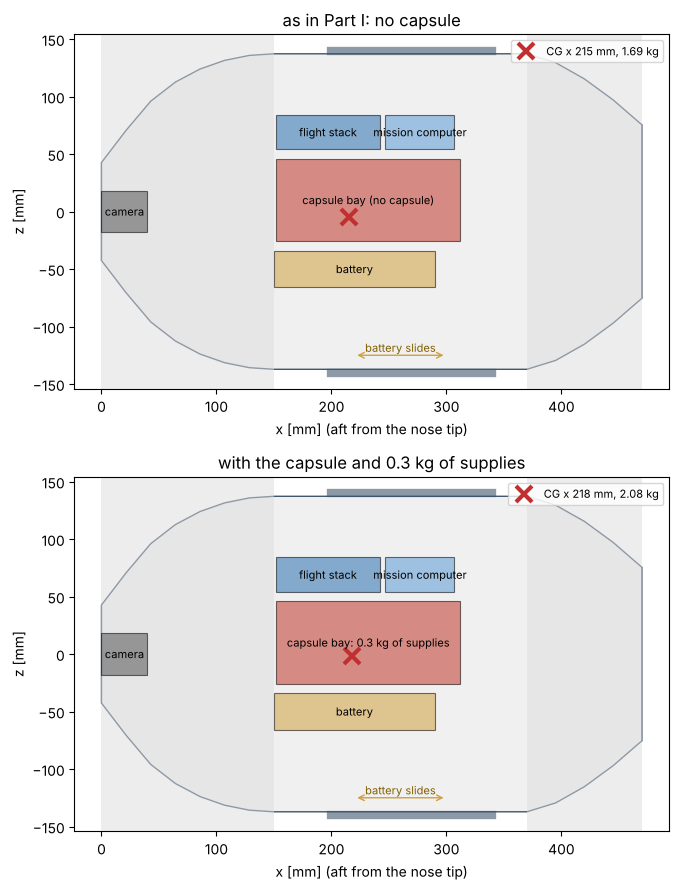

,mass [kg],CG x [mm],battery x [mm],battery at its stop,static margin,hover T/W,hover power [W],stall speed [m/s],power at 16 m/s [W],endurance at 16 m/s [min],endurance best [min]
no capsule (Part I),1.686206,214.848127,220.0,True,0.095525,2.893213,220.648811,10.910411,110.215621,21.270306,40.193712
"capsule, empty",1.776206,215.717209,220.0,True,0.089317,2.746615,238.067487,11.197794,111.743249,20.979522,35.281861
"capsule, 0.3 kg (nominal)",2.076206,218.06998,220.0,True,0.072511,2.349744,299.454336,12.106567,117.118255,20.016692,28.896222
"capsule, 0.5 kg (full)",2.276206,219.293948,220.0,True,0.063769,2.143283,343.112275,12.676273,120.008654,19.534591,27.290891


transitions:   0%|          | 0/8 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
vehicle        direction t_tr [s] headwind [m/s]                                                                                                                                                                      
capsule 0.3 kg forward   3.0      0.0                        0.11             0.40                   2.42                           1.00                             8.42                   0.0                0.84   
                                  6.0                        0.33             0.11                   1.70                           2.53                            18.12                   0.0                0.83   
               back      3.0      0.0                        0.20             0.25                   4.54                           1.59                            55.58                   0.0                0.75   
                                  6.0                        0.20             0.30                   4.54                           1.59                            55.58                   0.0                0.75   
capsule 0.5 kg forward   3.0      0.0                        0.13             0.41                   2.41                           1.02                             8.20                   0.0                0.85   
                                  6.0                        0.30             0.13                   1.63                           2.55                            17.57                   0.0                0.84   
               back      3.0      0.0                        0.49             0.06                   4.51                           1.77                            45.72                   0.0                0.74   
                                  6.0                        0.49             0.42                   4.51                           1.77                            45.72                   0.0                0.74   

                                                  peak rotor thrust / T_max  elevon max [deg]  roll demand / authority  roll demand / rotors' authority  pass  
vehicle        direction t_tr [s] headwind [m/s]                                                                                                               
capsule 0.3 kg forward   3.0      0.0                                  0.65              3.82                     0.07                             1.24  True  
                                  6.0                                  0.62              4.18                     0.07                             1.30  True  
               back      3.0      0.0                                  0.51              6.30                     0.40                             1.34  True  
                                  6.0                                  0.53              6.30                     0.40                             1.34  True  
capsule 0.5 kg forward   3.0      0.0                                  0.70              3.63                     0.07                             1.28  True  
                                  6.0                                  0.64              4.02                     0.08                             1.35  True  
               back      3.0      0.0                                  0.57              6.51                     0.34                             1.37  True  
                                  6.0                                  0.56              6.51                     0.34                             1.37  True

capsule 0.3 kg: 4 of 4 pass
capsule 0.5 kg: 4 of 4 pass


iteration 4 — the payload bay,value,target,holds,note
check,,,,
bay rules broken,0,≤ 0,✔,
"take-off mass, full capsule [kg]",2.28,≤ 2.3,✔,2.0 + the 0.3 kg the bay adds over the spec's payload
"hover thrust / weight, full",2.14,≥ 2,✔,
"static margin, full [chords]",0.0638,0.05 – 0.15,✔,
"endurance at the cruise, full [min]",19.5,≥ 20,✘,on 4Q's round struts; 4Q-2's drag makes it (§ 16)
transitions with the capsule: passing,1,≥ 1,✔,


iteration 4 — the payload bay: 5 of 6 hold — failing: endurance at the cruise, full [min]


{'iteration': '4 — payload bay (Part II)',
 'what changed': 'pod 430 → 470 mm, ogive nose, the capsule on the axis',
 'source': 'CAD bays + mass table + transitions',
 'take-off mass [kg]': 2.2762063482324604,
 'static margin [chords]': np.float64(0.06376867495792918),
 'hover thrust / weight': 2.1432829214237445,
 'stall speed [m/s]': 12.676272928858339,
 'Cd0': 0.06654869740668531,
 'cruise power [W]': np.float64(120.00865405396456),
 'endurance at the cruise [min]': np.float64(19.534591221611606),
 'transitions passing': '8 of 8',
 'checks holding': '5 / 6',
 'failing': 'endurance at the cruise, full [min]'}

In [20]:
print("bay rules:", kestrel.Kestrel4Q.bay_checks(P) or "all hold")
BAYS = pd.DataFrame(kestrel.Kestrel4Q.bays(P, battery_x=CI["battery_x"] * 1000), index=["x0", "x1", "y0", "y1", "z0", "z1"]).T
display(BAYS.round(0))
fig, axs = plt.subplots(2, 1, figsize=(12, 9))
kd.internal_layout(P, capsule_kg=None, ax=axs[0]); axs[0].set_title("as in Part I: no capsule")
kd.internal_layout(P, capsule_kg=0.3, ax=axs[1]); axs[1].set_title("with the capsule and 0.3 kg of supplies")
plt.tight_layout(); plt.show()
CAP = {}
for cap, label in ((None, "no capsule (Part I)"), (0.0, "capsule, empty"), (0.3, "capsule, 0.3 kg (nominal)"), (0.5, "capsule, 0.5 kg (full)")):
    t_ = ks.mass_table(P, capsule=cap); c_ = ks.cg_inertia(t_)
    np_ = kf.neutral_point(P, x_cg=c_["x_cg"], a=A)
    hp = ks.hover_point(c_["mass_kg"])
    cru = kf.cruise(P, mass_kg=c_["mass_kg"], x_cg=c_["x_cg"], z_cg=c_["z_cg"], pol=POL)
    feas = cru[cru["feasible"]]
    CAP[label] = {"mass [kg]": c_["mass_kg"], "CG x [mm]": c_["x_cg"] * 1000, "battery x [mm]": c_["battery_x"] * 1000, "battery at its stop": c_["battery_clipped"],
                  "static margin": np_["static_margin"], "hover T/W": hp["T_W"], "hover power [W]": hp["total_W"],
                  "stall speed [m/s]": kf.stall_speed(P, mass_kg=c_["mass_kg"], pol=POL), "power at 16 m/s [W]": cru.loc[16.0, "electrical [W]"],
                  "endurance at 16 m/s [min]": cru.loc[16.0, "endurance [min]"], "endurance best [min]": feas["endurance [min]"].max()}
CAPT = pd.DataFrame(CAP).T
display(CAPT.round(3))
# the transitions with the nominal and the full capsule (3 s schedules, still air and the headwind)
VEH_CAP = {lab: kt.make_vehicle(P, aero=A, extra_kg=0.0, name=lab) for lab in ()}
for cap, lab in ((0.3, "capsule 0.3 kg"), (0.5, "capsule 0.5 kg")):
    t_ = ks.mass_table(P, capsule=cap); c_ = ks.cg_inertia(t_)
    v_ = kt.make_vehicle(P, aero=A, name=lab)
    v_.mass, v_.x_cg, v_.z_cg, v_.Iyy, v_.Ixx = c_["mass_kg"], c_["x_cg"], c_["z_cg"], c_["Iyy"], c_["Ixx"]
    VEH_CAP[lab] = v_
MAT_CAP, _ = kt.matrix(VEH_CAP, durations=(3.0,), headwinds=(0.0, 6.0), progress=True)
display(MAT_CAP[cols].astype({c: float for c in cols if c != "pass"}).round(2))
for k, v in kt.verdict(MAT_CAP).items():
    print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
full = CAPT.loc["capsule, 0.5 kg (full)"]
CHK4 = [kl.check("bay rules broken", len(kestrel.Kestrel4Q.bay_checks(P)), "≤", 0), kl.check("take-off mass, full capsule [kg]", full["mass [kg]"], "≤", 2.3, note="2.0 + the 0.3 kg the bay adds over the spec's payload"),
        kl.check("hover thrust / weight, full", full["hover T/W"], "≥", 2.0), kl.check("static margin, full [chords]", full["static margin"], "between", (0.05, 0.15)),
        kl.check("endurance at the cruise, full [min]", full["endurance at 16 m/s [min]"], "≥", 20.0, note="on 4Q's round struts; 4Q-2's drag makes it (§ 16)"),
        kl.check("transitions with the capsule: passing", int(MAT_CAP["pass"].astype(bool).sum()) / len(MAT_CAP), "≥", 1.0)]
show_checks(CHK4, "iteration 4 — the payload bay")
LOG.add("4 — payload bay (Part II)", changed="pod 430 → 470 mm, ogive nose, the capsule on the axis", source="CAD bays + mass table + transitions", checks=CHK4,
        **{"take-off mass [kg]": full["mass [kg]"], "static margin [chords]": full["static margin"], "hover thrust / weight": full["hover T/W"], "stall speed [m/s]": full["stall speed [m/s]"],
           "Cd0": POL.cd0, "cruise power [W]": full["power at 16 m/s [W]"], "endurance at the cruise [min]": full["endurance at 16 m/s [min]"],
           "transitions passing": f"{int(MAT_CAP['pass'].astype(bool).sum())} of {len(MAT_CAP)}"})

## 12. Elevons

Four trailing-edge surfaces, 28 % of the chord, from the slipstream's inner edge (motor station − propeller radius =
275 mm) to the tip of each wing: 225 mm span each, 0.035 m² together (12.6 % of the wing area). The hinge on the
camber line; one 9 g servo each in the wing behind the spar. What they must prove: the heading in the hover (the
rotors' weak axis), the roll in the transition (where the rotors-only aircraft failed), the pitch trim in cruise (that
the thrust split could not close), and that a 9 g servo holds them.

layout rules: all hold


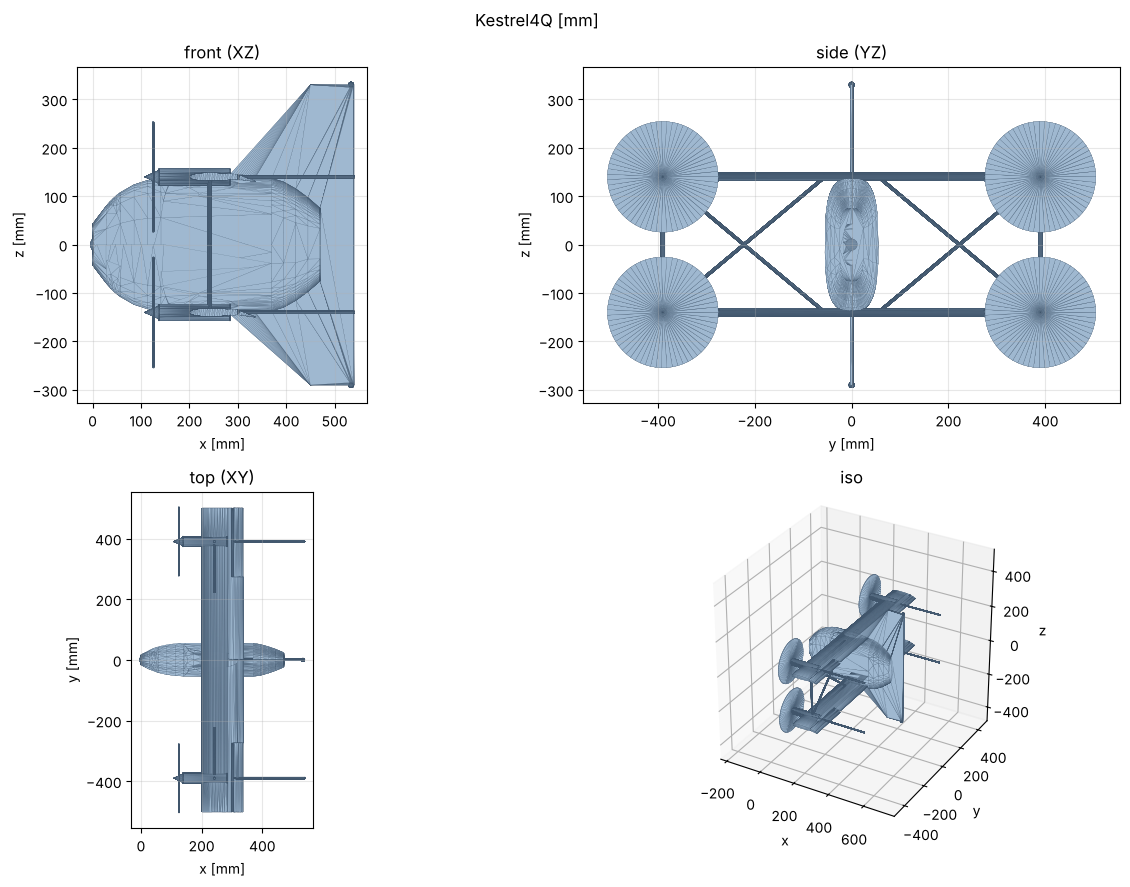

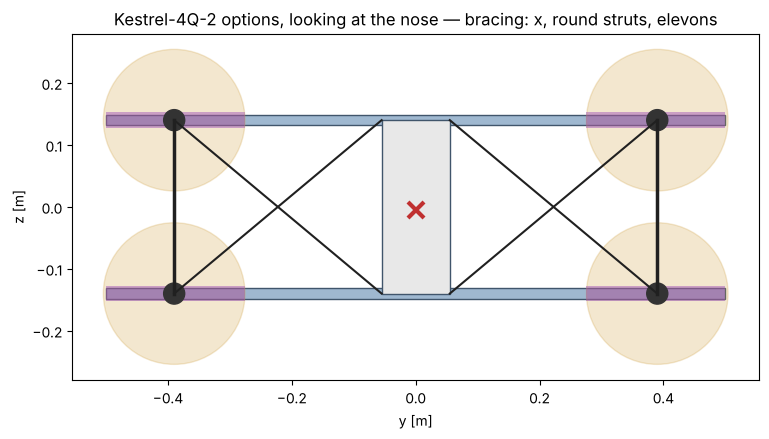

,elevon chord [mm],span each [mm],"area, four [m²]",share of the wing area,hinge x [mm],mass added (4 servos + linkages) [g]
the elevons,39.2,225.0,0.035,0.126,300.8,48.0


,V [m/s],"elevon area, one [m²]",elevon chord [m],hinge moment [N·m],"hinge moment, hover slipstream [N·m]",slipstream speed in the hover [m/s],servo torque rating [N·m],"servo margin, cruise","servo margin, hover",time to 20° [s]
"16 m/s, α 5°, δ 20°",16.0,0.0088,0.0392,-0.0121,-0.0067,12.8484,0.17,14.0916,25.3290,0.04
"20 m/s, α 3°, δ 25°",20.0,0.0088,0.0392,-0.0219,-0.0084,12.8484,0.17,7.7694,20.2632,0.04
"25 m/s, α 2°, δ 25°",25.0,0.0088,0.0392,-0.0334,-0.0084,12.8484,0.17,5.0929,20.2632,0.04


In [21]:
P_EL = kestrel.resolve(dict(P, elevons=True))
L_EL = kestrel.Kestrel4Q.layout(P_EL)
print("layout rules:", kestrel.Kestrel4Q.checks(P_EL) or "all hold")
el_parts = {"aircraft, elevons 15° down": design.generate(**kestrel.overrides(P_EL), part="aircraft", elevon_deg=15.0),
            "one elevon": design.generate(**kestrel.overrides(P_EL), part="elevon")}
for k, g in el_parts.items():
    g.export(RUNS / "cad" / k.split(",")[0].replace(" ", "_"), stl_tolerance=0.3)
dedalus.plot_views(el_parts["aircraft, elevons 15° down"], figsize=(13, 9)); plt.show()
fig, ax = plt.subplots(figsize=(12, 4.5)); kd.front_view_4q2(P_EL, cg=CI, ax=ax); plt.show()
EL = pd.Series({"elevon chord [mm]": L_EL["elevon_cf"] * L_EL["chord"] * 1000, "span each [mm]": L_EL["elevon_span_side"] * 1000,
                "area, four [m²]": L_EL["S_elevon"], "share of the wing area": L_EL["S_elevon"] / L_EL["S_ref"], "hinge x [mm]": L_EL["x_hinge"] * 1000,
                "mass added (4 servos + linkages) [g]": 4 * ks.SERVO_KG * 1000}, name="the elevons")
display(EL.round(3).to_frame().T)
# the hinge moments against the 9 g servo, in cruise and in the hover's slipstream
HINGE = pd.DataFrame({f"{V:g} m/s, α {a:g}°, δ {d:g}°": kc.elevon_hinge(P_EL, V=V, alpha_deg=a, delta_deg=d)
                      for V, a, d in ((16.0, 5.0, 20.0), (20.0, 3.0, 25.0), (25.0, 2.0, 25.0))}).T
display(HINGE.round(4))

**Authority.** The lift increment of a plain flap at this Reynolds number is well below the inviscid textbook value:
Zephyr's flap sweep (§ 13) gives τ ≈ 0.32–0.40 for a 28 % flap; Part I's model assumed 0.45. The table below uses the
measured τ when Zephyr is available, 0.40 otherwise — on the safe side of Part I.

In [22]:
try:
    import kestrel_section as ksec
    HAVE_ZEPHYR = True
    SECT_T = ksec.table()
    TAU_EL = float(SECT_T["NACA 0012"]["elevon"]["tau"]); XCP_EL = float(SECT_T["NACA 0012"]["elevon"]["x_cp_flap"])
    print(f"elevon τ from Zephyr (NACA 0012, 28 %, Re 1.5e5): {TAU_EL:.3f}; the flap's lift centre at {XCP_EL:.2f} c")
except Exception as exc:
    HAVE_ZEPHYR = False
    TAU_EL, XCP_EL = 0.40, 0.40
    print("Zephyr not available here:", type(exc).__name__, str(exc)[:120], "→ τ = 0.40 assumed")
AUTH = kc.elevon_authority(P_EL, mass_kg=CI["mass_kg"], cg=CG, tau=TAU_EL, cl_alpha=POL.cl_alpha, x_cp=XCP_EL)
display(AUTH.round(3))
# the transitions with the CAD's elevons (their span from the CAD, τ as above) against Part I's rotors-only aircraft
VEH_EL = kt.make_vehicle(P_EL, aero=A, name="Kestrel-4Q + elevons (CAD span)"); VEH_EL.elevon_tau = TAU_EL
MAT_EL, _ = kt.matrix({"4Q + elevons": VEH_EL, "4Q rotors only": VEHICLES["rotors only"]}, durations=durs, headwinds=(0.0, 6.0), progress=True)
display(MAT_EL[cols].astype({c: float for c in cols if c != "pass"}).round(2))
for k, v in kt.verdict(MAT_EL).items():
    print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
el_p, ro_p = passes(MAT_EL, vehicle="4Q + elevons"), passes(MAT_EL, vehicle="4Q rotors only")
CHK5 = [kl.check("servo margin (0.17 N·m / hinge moment), least", float((0.17 / HINGE["hinge moment [N·m]"].astype(float).abs()).min()), "≥", 2.0),
        kl.check("hover heading authority, elevons / rotors", float(AUTH.loc["hover (slipstream only)", "elevons / rotors, about the axis"]), "≥", 2.0),
        kl.check("transitions, 4Q + elevons: passing", el_p[0] / el_p[1], "≥", (len(durs) - 1) / len(durs), note=f"{el_p[0]} of {el_p[1]} (all but the 1.5 s pitch-over)"),
        kl.check("transitions, rotors only: passing", ro_p[0] / ro_p[1], "≥", 1.0, note=f"{ro_p[0]} of {ro_p[1]} — the change is needed")]
show_checks(CHK5, "iteration 5 — the elevons")
LOG.add("5 — elevons (Part II)", changed="four 28 % surfaces from 275 mm to the tips, τ from Zephyr", source="CAD + kestrel_control + transitions", checks=CHK5,
        **{"take-off mass [kg]": VEH_EL.mass, "static margin [chords]": NP["static_margin"], "hover thrust / weight": HP["T_W"], "stall speed [m/s]": VS, "Cd0": POL.cd0,
           "transitions passing": f"{el_p[0]} of {el_p[1]}"})

elevon τ from Zephyr (NACA 0012, 28 %, Re 1.5e5): 0.465; the flap's lift centre at 0.40 c


,one elevon ΔL [N],roll / heading from elevons [N·m],pitch from elevons [N·m],rotors: about the thrust axis [N·m],rotors: pitch [N·m],"elevons / rotors, about the axis"
hover (slipstream only),2.627,4.072,0.440,0.242,2.101,16.798
cruise 16 m/s,4.090,6.339,0.684,0.394,2.101,16.086


transitions:   0%|          | 0/24 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
vehicle        direction t_tr [s] headwind [m/s]                                                                                                                                                                      
4Q + elevons   forward   1.5      0.0                        3.37             0.38                   7.90                           0.28                             5.50                   0.0                0.74   
                                  6.0                        0.31             0.09                   4.54                           1.12                            19.13                   0.0                0.83   
                         3.0      0.0                        0.11             0.39                   2.42                           0.96                             8.89                   0.0                0.83   
                                  6.0                        0.43             0.10                   1.82                           2.50                            19.20                   0.0                0.82   
                         5.0      0.0                        1.09             0.37                   1.43                           2.55                            14.94                   0.0                0.78   
                                  6.0                        1.41             0.43                   1.18                           4.48                            20.65                   0.0                0.82   
               back      1.5      0.0                        0.28             1.35                   7.34                           0.96                            75.69                   0.0                0.68   
                                  6.0                        0.16             1.35                   7.34                           0.96                            75.69                   0.0                0.68   
                         3.0      0.0                        0.46             2.02                   4.48                           1.49                            73.40                   0.0                0.78   
                                  6.0                        0.16             2.02                   4.48                           1.49                            73.40                   0.0                0.78   
                         5.0      0.0                        0.67             2.64                   2.22                           1.88                            60.19                   0.0                0.83   
                                  6.0                        0.39             2.64                   2.22                           1.88                            60.19                   0.0                0.83   
4Q rotors only forward   1.5      0.0                        0.79             0.29                   7.84                           0.27                             5.51                   0.0                0.56   
                                  6.0                        0.18             0.14                   4.43                           1.10                            19.06                   0.0                0.71   
                         3.0      0.0                        0.11             0.43                   2.44                           0.92                             8.80                   0.0                0.76   
                                  6.0                        0.22             0.14                   1.96                           2.45                            19.15                   0.0                0.75   
                         5.0      0.0                        0.71             0.41                   1.69                           2.44                            14.77           

4Q + elevons: 11 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails holds height
4Q rotors only: 3 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails roll holds
   - forward 1.5 s, headwind 6 m/s: fails roll holds
   - forward 5 s, headwind 6 m/s: fails roll holds
   - back 1.5 s, headwind 0 m/s: fails roll holds
   - back 1.5 s, headwind 6 m/s: fails roll holds
   - back 3 s, headwind 0 m/s: fails roll holds
   - back 3 s, headwind 6 m/s: fails roll holds
   - back 5 s, headwind 0 m/s: fails roll holds
   - back 5 s, headwind 6 m/s: fails roll holds


iteration 5 — the elevons,value,target,holds,note
check,,,,
"servo margin (0.17 N·m / hinge moment), least",5.09,≥ 2,✔,
"hover heading authority, elevons / rotors",16.8,≥ 2,✔,
"transitions, 4Q + elevons: passing",0.917,≥ 0.666667,✔,11 of 12 (all but the 1.5 s pitch-over)
"transitions, rotors only: passing",0.25,≥ 1,✘,3 of 12 — the change is needed


iteration 5 — the elevons: 3 of 4 hold — failing: transitions, rotors only: passing


{'iteration': '5 — elevons (Part II)',
 'what changed': 'four 28 % surfaces from 275 mm to the tips, τ from Zephyr',
 'source': 'CAD + kestrel_control + transitions',
 'take-off mass [kg]': 1.7342063482324606,
 'static margin [chords]': np.float64(0.09552453569798042),
 'hover thrust / weight': 2.893213038200698,
 'stall speed [m/s]': 10.910411381833859,
 'Cd0': 0.06654869740668531,
 'transitions passing': '11 of 12',
 'checks holding': '3 / 4',
 'failing': 'transitions, rotors only: passing'}

## 13. Faired struts

Each tube in a symmetric teardrop sleeve (NACA 0033 section, 0.8 mm outside the tube at its thickest, the tube at
30 % of the sleeve's chord, the chord along the pod's axis — the free stream in cruise and the slipstream in the
hover; the struts lie in the y–z plane, so the section square to a strut is the streamwise one). The gain was
estimated in Part I; here it is checked for what it costs: mass, the broadside area in the transition (a sleeve
shows ~3 × the tube's frontal area when the air comes from the side), and whether the trim survives it.

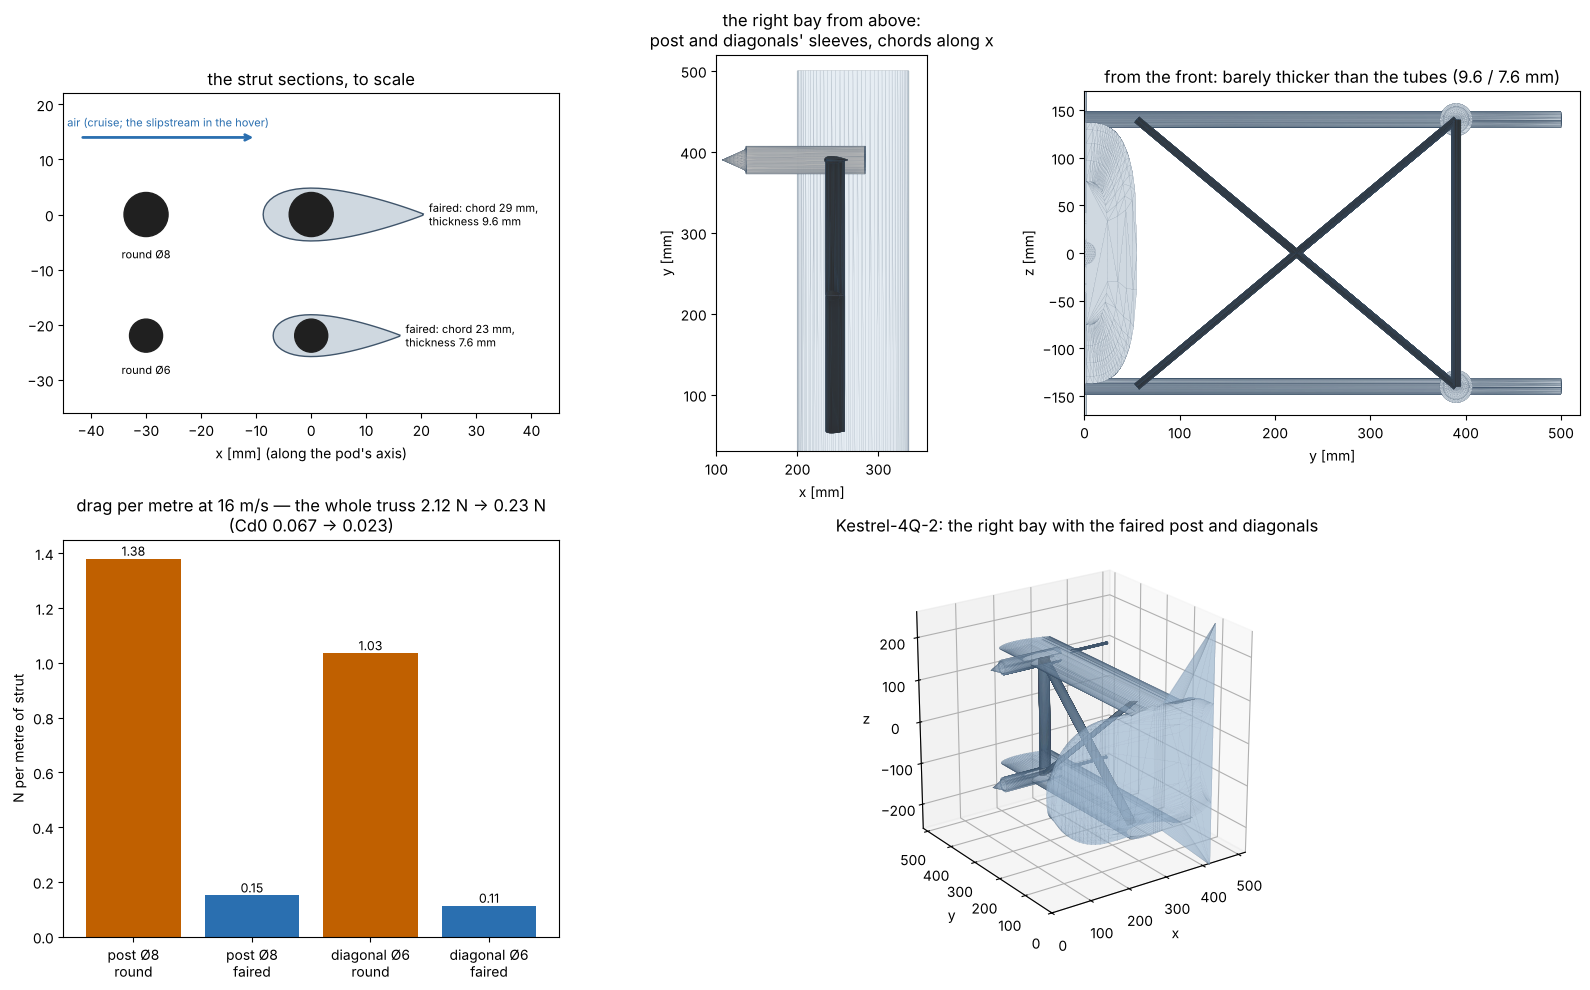

,faired struts
sleeve volume [cm³],235.5199
sleeve skin [cm²],1232.7787
"mass, foam 30 kg/m³ + film [g]",10.7639
"mass, printed LW-PLA 0.45 mm [g]",36.0588
mass in the table (SLEEVE_KG_M) [g],10.3457
Cd0 round,0.0665
Cd0 faired,0.0234
"truss drag at 16 m/s, round [N]",2.1250
"truss drag at 16 m/s, faired [N]",0.2318
"broadside area of the struts, round [m²]",0.0150


at 16 m/s: round 110 W, 21.3 min, L/D 5.0 → faired 59 W, 39.6 min, L/D 11.5; trim by thrust alone: False


transitions:   0%|          | 0/12 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
vehicle          direction t_tr [s] headwind [m/s]                                                                                                                                                                      
faired + elevons forward   1.5      0.0                        2.90             0.39                   7.90                           0.28                             5.56                   0.0                0.75   
                                    6.0                        0.25             0.21                   4.49                           1.12                            18.71                   0.0                0.83   
                           3.0      0.0                        0.14             0.45                   2.40                           0.97                             9.03                   0.0                0.84   
                                    6.0                        0.35             0.24                   1.72                           2.52                            18.82                   0.0                0.82   
                           5.0      0.0                        0.98             0.45                   1.28                           2.58                            14.94                   0.0                0.78   
                                    6.0                        1.29             0.29                   1.00                           4.53                            20.36                   0.0                0.81   
                 back      1.5      0.0                        0.57             3.19                   7.14                           1.11                            72.37                   0.0                0.63   
                                    6.0                        0.23             3.19                   7.14                           1.11                            72.37                   0.0                0.63   
                           3.0      0.0                        1.67             6.01                   4.49                           1.65                            71.14                   0.0                0.77   
                                    6.0                        1.41             6.01                   4.49                           1.65                            71.14                   0.0                0.77   
                           5.0      0.0                        1.95            10.00                   2.31                           1.77                            63.97                   0.0                0.85   
                                    6.0                        1.12            10.00                   2.31                           1.77                            63.97                   0.0                0.84   

                                                    peak rotor thrust / T_max  elevon max [deg]  roll demand / authority  roll demand / rotors' authority   pass  
vehicle          direction t_tr [s] headwind [m/s]                                                                                                                
faired + elevons forward   1.5      0.0                                  1.00              6.15                     0.09                             1.25   True  
                                    6.0                                  0.99              3.80                     0.07                             1.15   True  
                           3.0      0.0                                  0.53              3.90                     0.07                             1.13   True  
                                    6.0                                  0.50              4.41                     0.07                             1.18   True  
                           5.0     

faired + elevons: 10 of 12 pass
   - back 5 s, headwind 0 m/s: fails holds height
   - back 5 s, headwind 6 m/s: fails holds height


iteration 6 — faired struts,value,target,holds,note
check,,,,
Cd0 faired / round,0.352,≤ 0.5,✔,
"endurance at the cruise, faired [min]",39.6,≥ 20,✔,
sleeve mass [g],10.8,≤ 40,✔,
"trim by thrust alone, faired",no,== yes,✘,never: the elevons trim
"transitions, faired + elevons, cruise entry: passing",0.833,≥ 0.666667,✔,10 of 12: the low-drag aircraft balloons (§ 16: the slow entry)


iteration 6 — faired struts: 4 of 5 hold — failing: trim by thrust alone, faired


{'iteration': '6 — faired struts (Part II)',
 'what changed': 'teardrop sleeves on posts and diagonals',
 'source': 'drag build-up + CAD + transitions',
 'take-off mass [kg]': 1.7445520479110899,
 'static margin [chords]': np.float64(0.09552453569798042),
 'hover thrust / weight': 2.893213038200698,
 'stall speed [m/s]': 10.910411381833859,
 'Cd0': 0.0234286974066853,
 'L/D at the cruise': 11.457555786338029,
 'cruise power [W]': 59.21745224127278,
 'endurance at the cruise [min]': 39.588329306171666,
 'transitions passing': '10 of 12',
 'checks holding': '4 / 5',
 'failing': 'trim by thrust alone, faired'}

In [23]:
P_F = kestrel.resolve(dict(P, strut_fairing=True))
kd.fairing_figure(P_F); plt.show()
tr_round, tr_fair = design.generate(part="truss").measure(), design.generate(part="truss", strut_fairing=True).measure()
sleeve_cm3, skin_cm2 = (tr_fair["volume"] - tr_round["volume"]) / 1e3, tr_fair["surface_area"] / 1e2
FAIR = pd.Series({"sleeve volume [cm³]": sleeve_cm3, "sleeve skin [cm²]": skin_cm2,
                  "mass, foam 30 kg/m³ + film [g]": sleeve_cm3 * 0.03 + skin_cm2 * 0.003, "mass, printed LW-PLA 0.45 mm [g]": skin_cm2 * 0.045 * 0.65,
                  "mass in the table (SLEEVE_KG_M) [g]": 1000 * (2 * ks.SLEEVE_KG_M["post"] * L["post_length"] + 4 * ks.SLEEVE_KG_M["diagonal"] * L["diagonal_length"]),
                  "Cd0 round": D_round["Cd0"], "Cd0 faired": D_faired["Cd0"], "truss drag at 16 m/s, round [N]": 0.5 * ks.RHO0 * 256 * D_round["bracing_m2"],
                  "truss drag at 16 m/s, faired [N]": 0.5 * ks.RHO0 * 256 * D_faired["bracing_m2"],
                  "broadside area of the struts, round [m²]": 2 * 0.008 * L["post_length"] + 4 * 0.006 * L["diagonal_length"],
                  "broadside area of the struts, faired [m²]": 2 * 0.029 * L["post_length"] + 4 * 0.023 * L["diagonal_length"],
                  "wings' planform (the broadside reference) [m²]": L["S_ref"]}, name="faired struts")
display(FAIR.round(4).to_frame())
cr_f = CRU["faired struts"]
print(f"at 16 m/s: round {CRU['round tubes'].loc[16.0, 'electrical [W]']:.0f} W, {CRU['round tubes'].loc[16.0, 'endurance [min]']:.1f} min, L/D {CRU['round tubes'].loc[16.0, 'L/D']:.1f} → "
      f"faired {cr_f.loc[16.0, 'electrical [W]']:.0f} W, {cr_f.loc[16.0, 'endurance [min]']:.1f} min, L/D {cr_f.loc[16.0, 'L/D']:.1f}; "
      f"trim by thrust alone: {bool(cr_f.loc[16.0, 'trim by thrust'])}")
# the transitions on the faired polar (the sleeves' broadside area added to the stalled drag as a flat plate)
POL_F = kf.polar(P, a=A, faired=True)
POL_F2 = kf.Polar(**{**POL_F.__dict__, "cd90": POL_F.cd90 + 1.2 * (FAIR["broadside area of the struts, faired [m²]"] - FAIR["broadside area of the struts, round [m²]"]) / L["S_ref"]})
VEH_F = kt.make_vehicle(dict(P, elevons=True, strut_fairing=True), aero=A, pol=POL_F2, name="Kestrel-4Q, faired + elevons"); VEH_F.elevon_tau = TAU_EL
MAT_F, _ = kt.matrix({"faired + elevons": VEH_F}, durations=durs, headwinds=(0.0, 6.0), progress=True)
display(MAT_F[cols].astype({c: float for c in cols if c != "pass"}).round(2))
for k, v in kt.verdict(MAT_F).items():
    print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
f_p = passes(MAT_F, vehicle="faired + elevons")
CHK6 = [kl.check("Cd0 faired / round", D_faired["Cd0"] / D_round["Cd0"], "≤", 0.5), kl.check("endurance at the cruise, faired [min]", float(cr_f.loc[16.0, "endurance [min]"]), "≥", 20.0),
        kl.check("sleeve mass [g]", float(FAIR["mass, foam 30 kg/m³ + film [g]"]), "≤", 40.0), kl.check("trim by thrust alone, faired", bool(cr_f.loc[16.0, "trim by thrust"]), "==", True, note="never: the elevons trim"),
        kl.check("transitions, faired + elevons, cruise entry: passing", f_p[0] / f_p[1], "≥", (len(durs) - 1) / len(durs), note=f"{f_p[0]} of {f_p[1]}: the low-drag aircraft balloons (§ 16: the slow entry)")]
show_checks(CHK6, "iteration 6 — faired struts")
LOG.add("6 — faired struts (Part II)", changed="teardrop sleeves on posts and diagonals", source="drag build-up + CAD + transitions", checks=CHK6,
        **{"take-off mass [kg]": VEH_F.mass, "static margin [chords]": NP["static_margin"], "hover thrust / weight": HP["T_W"], "stall speed [m/s]": VS, "Cd0": D_faired["Cd0"],
           "L/D at the cruise": float(cr_f.loc[16.0, "L/D"]), "cruise power [W]": float(cr_f.loc[16.0, "electrical [W]"]), "endurance at the cruise [min]": float(cr_f.loc[16.0, "endurance [min]"]),
           "transitions passing": f"{f_p[0]} of {f_p[1]}"})

## 14. A reflexed section instead of NACA 0012 (Zephyr)

A tailless aircraft's wing must carry its own trim: with the CG a static margin SM ahead of the neutral point, the
moment about the CG at the cruise CL is cm_section − SM·CL. NACA 0012 gives cm = 0: the nose-down moment −SM·CL
(≈ −0.04 at SM 0.10, CL 0.38) must come from the thrust split (Part I: not below 14 m/s, never with faired struts)
or from elevons turned up (drag). A **reflexed** camber line (the NACA 230/240-series with the third digit 1) is drawn
for cm = 0 with a positive design lift; more aft reflex (k₂/k₁ above the standard) gives cm > 0 — the trim built in.
Zephyr runs the candidates through NeuralFoil at the cruise and the transition Reynolds numbers (n_crit 6: a built-up
wing in turbulent air), checks the surrogate against thin-airfoil theory, and sweeps the elevon's flap on each. The
criterion: the elevon that trims the cruise within ±3°, the least trim drag, cl_max no worse than the 0012's, and
confidence on the attached branch. The CFD check of the surrogate (an extruded slab of the finalists in Aeromant) is
prepared, NOT RUN here.

,t/c,α₀ [deg],cm₀,cm (thin),cl max (cruise Re),α cl max,cl max (transition Re),cd at cruise cl,L/D at cruise cl,L/D max,cl kept 4° past stall,x_ac,elevon τ,elevon x_cp,confidence (attached)
NACA 0012,0.12,-0.0000,-0.0000,0.0000,1.0604,13.0,0.9644,0.0124,30.5372,42.4188,0.6545,0.2354,0.4653,0.4049,0.9630
NACA 2412,0.12,-1.8988,-0.0506,-0.0531,1.2032,15.0,1.1554,0.0115,33.0873,58.7305,0.7319,0.2151,0.5408,0.3952,0.9662
NACA 22112,0.12,-0.9517,0.0008,-0.0013,1.2475,14.0,1.1140,0.0128,29.7256,44.2338,0.6681,0.2372,0.4880,0.4041,0.9567
NACA 23112,0.12,-1.1710,-0.0003,0.0011,1.2561,13.0,1.1479,0.0134,28.2714,47.5225,0.8710,0.2370,0.4964,0.4053,0.8399
NACA 24112,0.12,-1.3985,-0.0052,0.0001,1.2276,12.0,1.1704,0.0137,27.6436,51.8359,0.9101,0.2385,0.5129,0.4046,0.8894
NACA 23112 (k2/k1 0.015),0.12,-0.7510,0.0170,0.0221,1.2163,13.0,1.1004,0.0142,26.6721,45.8510,0.8558,0.2501,0.4821,0.4087,0.8707
NACA 23112 (k2/k1 0.02),0.12,-0.5361,0.0260,0.0348,1.1927,13.0,1.0704,0.0148,25.7608,44.8849,0.8419,0.2514,0.4782,0.4105,0.8864
NACA 23112 (k2/k1 0.025),0.12,-0.3193,0.0350,0.0475,1.1699,13.0,1.0366,0.0152,24.9273,43.9011,0.8220,0.2597,0.4782,0.4122,0.8997
NACA 23112 (k2/k1 0.03),0.12,-0.0971,0.0438,0.0603,1.1480,13.0,1.0032,0.0157,24.1588,42.8520,0.7947,0.2667,0.4816,0.4136,0.9108
NACA 24112 (k2/k1 0.06),0.12,-0.9306,0.0137,0.0241,1.1699,12.0,1.1134,0.0145,26.1632,50.2309,0.9217,0.2535,0.4940,0.4084,0.9673


,cm needed,cm of the section,elevon [deg],Δcd (elevon),cd cruise,trim drag / section drag,cl lost to the elevon,trims within ±10°
NACA 0012,0.0363,-0.0124,-5.4943,0.0029,0.0124,0.2343,-0.3144,True
NACA 2412,0.0363,-0.0616,-13.0881,0.0109,0.0115,0.9481,-0.6738,False
NACA 22112,0.0363,-0.0094,-5.5127,0.0021,0.0128,0.1627,-0.2967,True
NACA 23112,0.0363,-0.0117,-5.7749,0.0027,0.0134,0.1997,-0.3088,True
NACA 24112,0.0363,-0.0196,-6.8281,0.0042,0.0137,0.3042,-0.3614,True
NACA 23112 (k2/k1 0.015),0.0363,0.0038,-3.6715,0.0018,0.0142,0.1263,-0.2047,True
NACA 23112 (k2/k1 0.02),0.0363,0.0134,-2.4959,0.0015,0.0148,0.0987,-0.1425,True
NACA 23112 (k2/k1 0.025),0.0363,0.0231,-1.3976,0.0010,0.0152,0.0625,-0.0815,True
NACA 23112 (k2/k1 0.03),0.0363,0.0328,-0.3556,0.0003,0.0157,0.0177,-0.0211,True
NACA 24112 (k2/k1 0.06),0.0363,-0.0023,-4.4071,0.0025,0.0145,0.1736,-0.2437,True


,alpha0_deg,alpha0_thin_deg,d_alpha0_deg,cm0,cm_c4_thin,d_cm0,cl_alpha_per_rad,cl_alpha_ratio_to_2pi
NACA 0012,-0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,6.4554,1.0274
NACA 2412,-1.8988,-2.0770,0.1782,-0.0506,-0.0531,0.0025,6.4490,1.0264
NACA 22112,-0.9517,-0.7150,-0.2367,0.0008,-0.0013,0.0022,6.2698,0.9979
NACA 23112,-1.1710,-0.7539,-0.4170,-0.0003,0.0011,-0.0014,6.5480,1.0421
NACA 24112,-1.3985,-0.8530,-0.5455,-0.0052,0.0001,-0.0053,6.4825,1.0317
NACA 23112 (k2/k1 0.015),-0.7510,-0.0611,-0.6899,0.0170,0.0221,-0.0051,6.5621,1.0444
NACA 23112 (k2/k1 0.02),-0.5361,0.3598,-0.8959,0.0260,0.0348,-0.0088,6.7325,1.0715
NACA 23112 (k2/k1 0.025),-0.3193,0.7807,-1.1000,0.0350,0.0475,-0.0126,6.6843,1.0638
NACA 23112 (k2/k1 0.03),-0.0971,1.2016,-1.2987,0.0438,0.0603,-0.0164,6.8333,1.0876
NACA 24112 (k2/k1 0.06),-0.9306,-0.0680,-0.8625,0.0137,0.0241,-0.0104,6.4992,1.0344


the pick: NACA 23112 (k2/k1 0.03) | finalists for the CFD check: ['NACA 0012', 'NACA 23112 (k2/k1 0.03)']


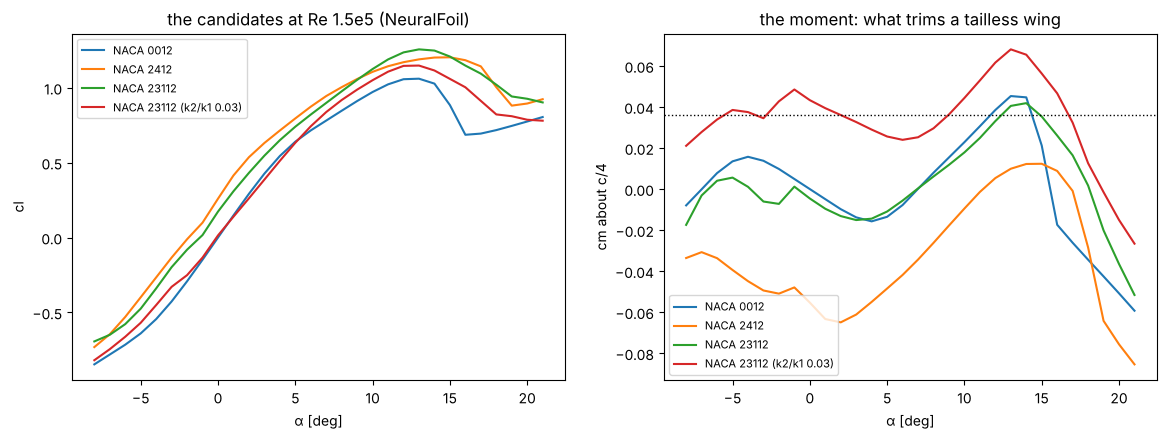

,status,α [deg],V [m/s],Re (chord),AR,template,reads against
"NACA 0012, α 0°, 16 m/s, AR 8 slab",NOT RUN,0.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 4°, 16 m/s, AR 8 slab",NOT RUN,4.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 8°, 16 m/s, AR 8 slab",NOT RUN,8.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 0012, α 12°, 16 m/s, AR 8 slab",NOT RUN,12.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 0°, 16 m/s, AR 8 slab",NOT RUN,0.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 4°, 16 m/s, AR 8 slab",NOT RUN,4.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 8°, 16 m/s, AR 8 slab",NOT RUN,8.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's
"NACA 23112 (k2/k1 0.03), α 12°, 16 m/s, AR 8 slab",NOT RUN,12.0,16.0,153424.657534,8.0,rans_ksst_external,the slab's lift slope ≈ AR/(AR+2) = 0.80 of the section's


the finalist: section drag 1.26 × the 0012's at the cruise cl, cl_max 1.15, α₀ -0.10°


iteration 7 — the section,value,target,holds,note
check,,,,
the pick trims the cruise within [deg],0.356,≤ 3,✔,NACA 0012 needs -5.5°
"cl max, pick / NACA 0012",1.08,≥ 0.97,✔,
"section drag at the cruise cl, pick / 0012 (incl. the 0012's trim elevon)",1.02,≤ 1.1,✔,
surrogate confidence on the attached branch,0.911,≥ 0.8,✔,
CFD slab cases of the finalists solved,0,≥ 1,✘,NOT RUN here: notebook 40


iteration 7 — the section: 4 of 5 hold — failing: CFD slab cases of the finalists solved


In [24]:
if HAVE_ZEPHYR:
    SECT = ksec.summary_frame(SECT_T)
    display(SECT.astype(float).round(4))
    TRIM = ksec.trim_table(SECT_T, static_margin=float(NP["static_margin"]))
    display(TRIM.astype({c: float for c in TRIM.columns if c != "trims within ±10°"}).round(4))
    CHK = pd.DataFrame({k: v["check"] for k, v in SECT_T.items()}).T
    display(CHK.astype(float).round(4))
    ok = TRIM[(TRIM["elevon [deg]"].abs() <= 3.0) & (SECT["cl max (cruise Re)"] >= 0.97 * SECT.loc["NACA 0012", "cl max (cruise Re)"])]
    pick = ok["trim drag / section drag"].astype(float).idxmin() if len(ok) else None
    FINALISTS = [c for c in ksec.CANDIDATES if ksec.key(*c) in ({pick, "NACA 0012"} if pick else {"NACA 0012"})]
    print("the pick:", pick, "| finalists for the CFD check:", [ksec.key(*c) for c in FINALISTS])
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for k in ("NACA 0012", "NACA 2412", "NACA 23112", pick or "NACA 23112"):
        pc = SECT_T[k]["polar_cruise"]
        ax[0].plot(pc["alpha_deg"], pc["cl"], label=k); ax[1].plot(pc["alpha_deg"], pc["cm"], label=k)
    ax[0].set(xlabel="α [deg]", ylabel="cl", title="the candidates at Re 1.5e5 (NeuralFoil)"); ax[1].set(xlabel="α [deg]", ylabel="cm about c/4", title="the moment: what trims a tailless wing")
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); ax[1].axhline(float(NP["static_margin"]) * kf.V_CRUISE * 0 + float(NP["static_margin"]) * 0.38, color="k", ls=":", lw=1); plt.show()
    SCFD = ksec.cfd_specs(FINALISTS)
    display(kcfd.section_not_run_table(SCFD))
    # the finalist's flight: the polar's cl_max, alpha0 and cd0 follow the section; the elevon's τ too
    if pick:
        sp = SECT_T[pick]
        SECTION_CD_RATIO = sp["cruise"]["cd_design"] / SECT_T["NACA 0012"]["cruise"]["cd_design"]     # the finalist's section drag over the 0012's
        SECTION_CL_MAX, SECTION_ALPHA0 = 0.9 * sp["cruise"]["cl_max"], math.radians(sp["cruise"]["alpha0_deg"])
        print(f"the finalist: section drag {SECTION_CD_RATIO:.2f} × the 0012's at the cruise cl, cl_max {sp['cruise']['cl_max']:.2f}, α₀ {sp['cruise']['alpha0_deg']:.2f}°")
else:
    SECT = TRIM = None; pick = None
    print("NOT RUN: vegeta.zephyr is not on this branch yet (PR dev_zephyr → dev_kestrel). When it is, this cell computes the "
          "candidates' polars and flap sweeps, picks the section that trims the cruise with the least elevon drag, prepares the "
          "Aeromant slab cases of the finalists, and builds the finalist's polar for § 15.")
if HAVE_ZEPHYR and pick:
    CHK7 = [kl.check("the pick trims the cruise within [deg]", abs(float(TRIM.loc[pick, "elevon [deg]"])), "≤", 3.0, note=f"NACA 0012 needs {float(TRIM.loc['NACA 0012', 'elevon [deg]']):.1f}°"),
            kl.check("cl max, pick / NACA 0012", float(SECT.loc[pick, "cl max (cruise Re)"]) / float(SECT.loc["NACA 0012", "cl max (cruise Re)"]), "≥", 0.97),
            kl.check("section drag at the cruise cl, pick / 0012 (incl. the 0012's trim elevon)", float(SECT.loc[pick, "cd at cruise cl"]) / (float(SECT.loc["NACA 0012", "cd at cruise cl"]) + float(TRIM.loc["NACA 0012", "Δcd (elevon)"])), "≤", 1.1),
            kl.check("surrogate confidence on the attached branch", float(SECT.loc[pick, "confidence (attached)"]), "≥", 0.8),
            kl.check("CFD slab cases of the finalists solved", 0, "≥", 1, note="NOT RUN here: notebook 40")]
    show_checks(CHK7, "iteration 7 — the section")
    LOG.add("7 — reflexed section (Part II, Zephyr)", changed=f"{pick} instead of NACA 0012", source="vegeta.zephyr / NeuralFoil", checks=CHK7,
            **{"take-off mass [kg]": CI["mass_kg"], "static margin [chords]": NP["static_margin"], "stall speed [m/s]": math.sqrt(2 * CI["mass_kg"] * ks.G / (ks.RHO0 * L["S_ref"] * SECTION_CL_MAX))})

## 15. Lighter bracing: can the X diagonals go?

Part I's plane frame (§ 8) said the spars never need the truss for strength (an 18 × reserve bare). What a truss gives
is stiffness: the symmetric stiffness of the motor stations (both wings bending together — the first mode the rotors
and the gusts excite) and the antisymmetric one (one wing up, one down — the racking that only a brace resists). The
first-mode estimates from them, against the rotor's 1P in the hover and the pitch loop's bandwidth, and the masses
and drag of each bracing, decide it.

In [25]:
MODES = kst.stiffness_and_modes(P)
display(MODES.round(2)); display(pd.Series(MODES.attrs["references"], name="references [Hz]").round(2).to_frame().T)
BRC = {}
for br, label in (("x", "posts + X diagonals"), ("posts", "posts only"), ("none", "no truss")):
    for fair in (False, True):
        pb = kestrel.resolve(dict(P, bracing=br, strut_fairing=fair))
        m = ks.cg_inertia(ks.mass_table(pb))["mass_kg"]
        d = kf.drag_buildup(pb, faired=fair)
        Lb = kestrel.Kestrel4Q.layout(pb)
        brace_m2 = (d["parts_m2"]["posts (2)"] if Lb["posts"] else 0.0) + (d["parts_m2"]["diagonals (4)"] if Lb["diagonals"] else 0.0)
        BRC[(label, "faired" if fair else "round")] = {"mass [kg]": m, "Δ mass vs Part I [g]": (m - CI["mass_kg"]) * 1000,
                                                        "bracing drag area [cm²]": brace_m2 * kf.INTERFERENCE * 1e4, "Cd0": (d["CdA_m2"] - (d["parts_m2"]["posts (2)"] + d["parts_m2"]["diagonals (4)"]) * kf.INTERFERENCE + brace_m2 * kf.INTERFERENCE) / L["S_ref"]}
BRCT = pd.DataFrame(BRC).T; BRCT.index.names = ["bracing", "struts"]
display(BRCT.round(4))
display(BR["upper wing 75 %"].round(3))
f_posts = float(MODES.loc["posts only", "first mode, symmetric [Hz]"])
ref = MODES.attrs["references"]
CHK8 = [kl.check("posts only: first mode / pitch loop bandwidth", f_posts / float(ref["pitch loop bandwidth [Hz]"]), "≥", 3.0, note="the structure must not be in the loop"),
        kl.check("posts only: first mode / rotor 1P", f_posts / float(ref["rotor 1P in the hover [Hz]"]), "≤", 0.5, note="clear below the 1P"),
        kl.check("mass saved by dropping the X [g]", -float(BRCT.loc[("posts only", "faired"), "Δ mass vs Part I [g]"] - BRCT.loc[("posts + X diagonals", "faired"), "Δ mass vs Part I [g]"]), "≥", 50.0),
        kl.check("spar stress reserve at 4 g, one wing 75 % (posts only)", float(BR["upper wing 75 %"].loc["posts only", "spar reserve"]), "≥", 3.0)]
show_checks(CHK8, "iteration 8 — the bracing")
LOG.add("8 — bracing (Part II)", changed="the X diagonals dropped, posts kept", source="kestrel_structure (frame, modes)", checks=CHK8,
        **{"take-off mass [kg]": float(BRCT.loc[("posts only", "faired"), "mass [kg]"]), "Cd0": float(BRCT.loc[("posts only", "faired"), "Cd0"])})

,k symmetric [N/mm],k antisymmetric [N/mm],"first mode, symmetric [Hz]","first mode, antisymmetric [Hz]"
posts + X diagonals,326.82,12950.83,260.53,1640.06
posts only,1.17,12567.54,15.61,1615.61
no truss (two cantilevers),1.17,1.17,15.61,15.61


,rotor 1P in the hover [Hz],pitch loop bandwidth [Hz]
references [Hz],110.0,1.91


mass [kg]  Δ mass vs Part I [g]  bracing drag area [cm²]     Cd0
bracing             struts                                                                  
posts + X diagonals round      1.6862                0.0000                 135.5200  0.0665
                    faired     1.6966               10.3457                  14.7840  0.0234
posts only          round      1.5998              -86.4213                  54.2080  0.0375
                    faired     1.6031              -83.0613                   5.9136  0.0203
no truss            round      1.5590             -127.2213                   0.0000  0.0181
                    faired     1.5590             -127.2213                   0.0000  0.0181

,spar peak moment [N·m],spar stress [MPa],spar reserve,"tip deflection, upper [mm]","tip deflection, lower [mm]","motor station, upper [mm]","motor station, lower [mm]",propeller gap change [mm],propeller gap under load [mm],least buckling margin,truss mass [g]
posts + X diagonals,0.734,12.658,31.602,-0.146,-0.036,0.035,0.035,-0.000,51.400,575.14,127.221
posts only,1.581,27.268,14.669,1.907,2.052,1.486,1.486,0.001,51.401,inf,40.800
no truss (two cantilevers),3.017,52.050,7.685,6.377,-2.419,4.627,-1.656,6.283,57.683,inf,0.000


iteration 8 — the bracing,value,target,holds,note
check,,,,
posts only: first mode / pitch loop bandwidth,8.17,≥ 3,✔,the structure must not be in the loop
posts only: first mode / rotor 1P,0.142,≤ 0.5,✔,clear below the 1P
mass saved by dropping the X [g],93.4,≥ 50,✔,
"spar stress reserve at 4 g, one wing 75 % (posts only)",14.7,≥ 3,✔,


iteration 8 — the bracing: 4 of 4 hold


{'iteration': '8 — bracing (Part II)',
 'what changed': 'the X diagonals dropped, posts kept',
 'source': 'kestrel_structure (frame, modes)',
 'take-off mass [kg]': 1.603145,
 'Cd0': 0.020260697406685298,
 'checks holding': '4 / 4',
 'failing': '—'}

## 16. Kestrel-4Q-2 against Kestrel-4Q

The four changes together: elevons, faired struts, posts only (the X dropped) and — when Zephyr is in — the reflexed
section. The same mass table, the same analyses, the same transition matrix.

Kestrel-4Q-2's polar: Polar(cl_alpha=4.078429512946968, cd0=0.02573992234522169, k=0.06657348753632776, cl_max=1.0332122363420333, cd90=np.float64(1.3273911935018017), alpha0=-0.0016944368983919456, width=0.026179938779914945, source='NACA 23112 (k2/k1 0.03) (Zephyr)')


,CL,feasible,note,α [deg],L/D,drag [N],Cm about CG,upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km]
V [m/s],,,,,,,,,,,,,
9.0,1.166,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10.0,0.944,True,the upper pair below T_min: thrust alone cannot trim,13.167,11.097,1.459,-0.086,-0.018,0.747,False,41.102,57.036,34.222
11.0,0.780,True,the upper pair below T_min: thrust alone cannot trim,10.865,11.774,1.375,-0.071,-0.038,0.726,False,42.913,54.629,36.055
12.0,0.656,True,the upper pair below T_min: thrust alone cannot trim,9.114,12.062,1.342,-0.060,-0.046,0.717,False,45.121,51.956,37.408
13.0,0.559,True,the upper pair below T_min: thrust alone cannot trim,7.751,12.010,1.348,-0.051,-0.045,0.719,False,47.978,48.862,38.113
14.0,0.482,True,the upper pair below T_min: thrust alone cannot trim,6.670,11.695,1.384,-0.044,-0.036,0.728,False,51.161,45.823,38.491
15.0,0.420,True,the upper pair below T_min: thrust alone cannot trim,5.798,11.201,1.446,-0.038,-0.021,0.744,False,54.987,42.634,38.371
16.0,0.369,True,the upper pair below T_min: thrust alone cannot trim,5.084,10.599,1.528,-0.034,-0.001,0.765,False,59.122,39.652,38.066
17.0,0.327,True,the upper pair below T_min: thrust alone cannot trim,4.493,9.946,1.628,-0.030,0.023,0.791,False,65.644,35.713,36.427


transitions:   0%|          | 0/12 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
vehicle      direction t_tr [s] headwind [m/s]                                                                                                                                                                      
Kestrel-4Q-2 forward   1.5      0.0                        0.61             0.11                   7.82                           0.23                             5.64                   0.0                0.75   
                                6.0                        0.24             0.20                   4.46                           1.05                            19.04                   0.0                0.84   
                       3.0      0.0                        0.13             0.41                   2.45                           0.81                             9.15                   0.0                0.84   
                                6.0                        0.18             0.15                   1.65                           2.25                            19.11                   0.0                0.84   
                       5.0      0.0                        0.42             0.58                   1.70                           2.19                            14.39                   0.0                0.84   
                                6.0                        1.08             0.32                   1.55                           4.09                            21.20                   0.0                0.84   
             back      1.5      0.0                        1.07             4.81                   6.80                           0.96                            63.77                   0.0                0.63   
                                6.0                        0.69             4.77                   6.80                           0.96                            63.77                   0.0                0.63   
                       3.0      0.0                        0.17            12.33                   3.44                           1.35                            62.59                   0.0                0.82   
                                6.0                        0.17            12.33                   3.44                           1.35                            62.59                   0.0                0.82   
                       5.0      0.0                        0.17            15.98                   1.73                           1.02                            56.96                   0.0                0.85   
                                6.0                        0.17            15.98                   1.73                           1.02                            56.96                   0.0                0.84   

                                                peak rotor thrust / T_max  elevon max [deg]  roll demand / authority  roll demand / rotors' authority   pass  
vehicle      direction t_tr [s] headwind [m/s]                                                                                                                
Kestrel-4Q-2 forward   1.5      0.0                                  1.00              6.10                     0.01                             0.18   True  
                                6.0                                  0.99              3.91                     0.02                             0.29   True  
                       3.0      0.0                                  0.53              3.77                     0.03                             0.35   True  
                                6.0                                  0.50              3.67                     0.04                             0.49   True  
                       5.0      0.0                                  0.41              3.84                    

Kestrel-4Q-2: 8 of 12 pass
   - back 3 s, headwind 0 m/s: fails holds height
   - back 3 s, headwind 6 m/s: fails holds height
   - back 5 s, headwind 0 m/s: fails holds height
   - back 5 s, headwind 6 m/s: fails holds height


gusts (entered at the cruise speed): {'forward, gust +3 m/s': True, 'forward, gust -3 m/s': True, 'back, gust +3 m/s': False, 'back, gust -3 m/s': False}


height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
entry speed [m/s] headwind [m/s] t_tr [s]                                                                                                                                                                      
16.0              0.0            1.5                  1.07             4.81                   6.80                           0.96                            63.77                   0.0                0.63   
                                 3.0                  0.17            12.33                   3.44                           1.35                            62.59                   0.0                0.82   
                                 5.0                  0.17            15.98                   1.73                           1.02                            56.96                   0.0                0.85   
                  6.0            1.5                  0.69             4.77                   6.80                           0.96                            63.77                   0.0                0.63   
                                 3.0                  0.17            12.33                   3.44                           1.35                            62.59                   0.0                0.82   
                                 5.0                  0.17            15.98                   1.73                           1.02                            56.96                   0.0                0.84   
13.0              0.0            1.5                  0.31             1.99                   7.24                           0.90                            74.84                   0.0                0.68   
                                 3.0                  1.32             5.08                   4.34                           1.30                            71.76                   0.0                0.82   
                                 5.0                  1.96             9.21                   2.06                           1.25                            63.82                   0.0                0.84   
                  6.0            1.5                  0.16             1.99                   7.24                           0.90                            74.84                   0.0                0.68   
                                 3.0                  0.91             5.08                   4.34                           1.30                            71.76                   0.0                0.82   
                                 5.0                  1.33             9.21                   2.06                           1.25                            63.82                   0.0                0.84   
12.0              0.0            1.5                  0.20             1.21                   7.33                           0.86                            75.09                   0.0                0.70   
                                 3.0                  0.68             3.12                   4.34                           1.30                            72.06                   0.0                0.81   
                                 5.0                  1.96             6.52                   2.13                           1.36                            63.64                   0.0                0.84   
                  6.0            1.5                  0.16             1.21                   7.33                           0.86                            75.09                   0.0                0.70   
                                 3.0                  0.16             3.12                   4.34                           1.30                            72.06                   0.0                0.81   
                                 5.0                  1.41             6.52                

gusts with the slow entry: {'back, gust +3 m/s, entered at 13 m/s': True, 'back, gust -3 m/s, entered at 13 m/s': True}
Kestrel-4Q-2 with the slow-entry rule: {'forward': '6 of 6', 'back, entered at 13 m/s': '6 of 6'}


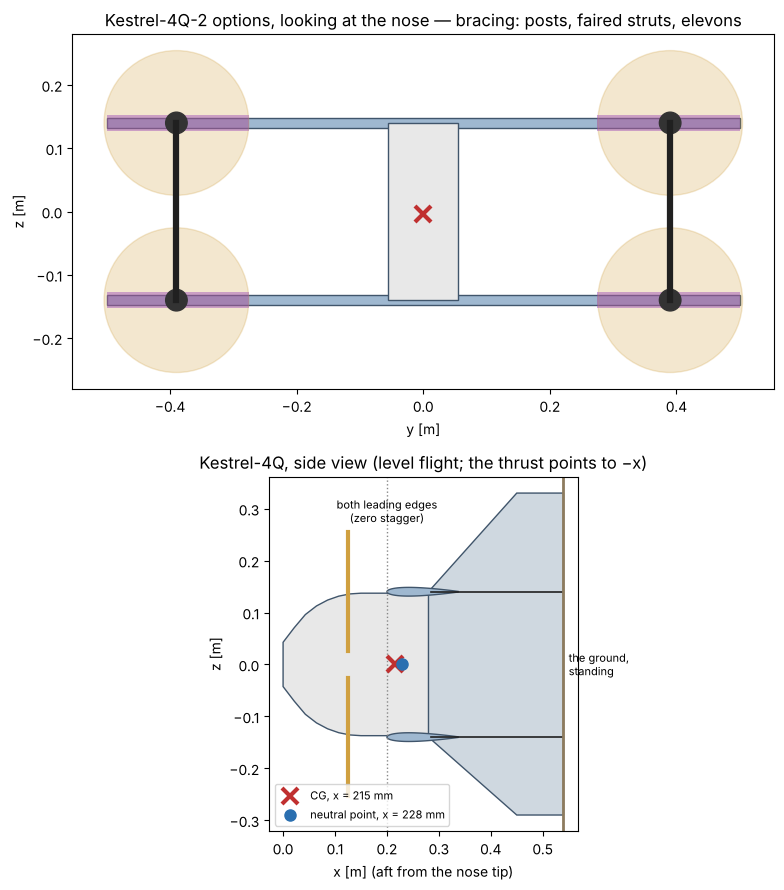

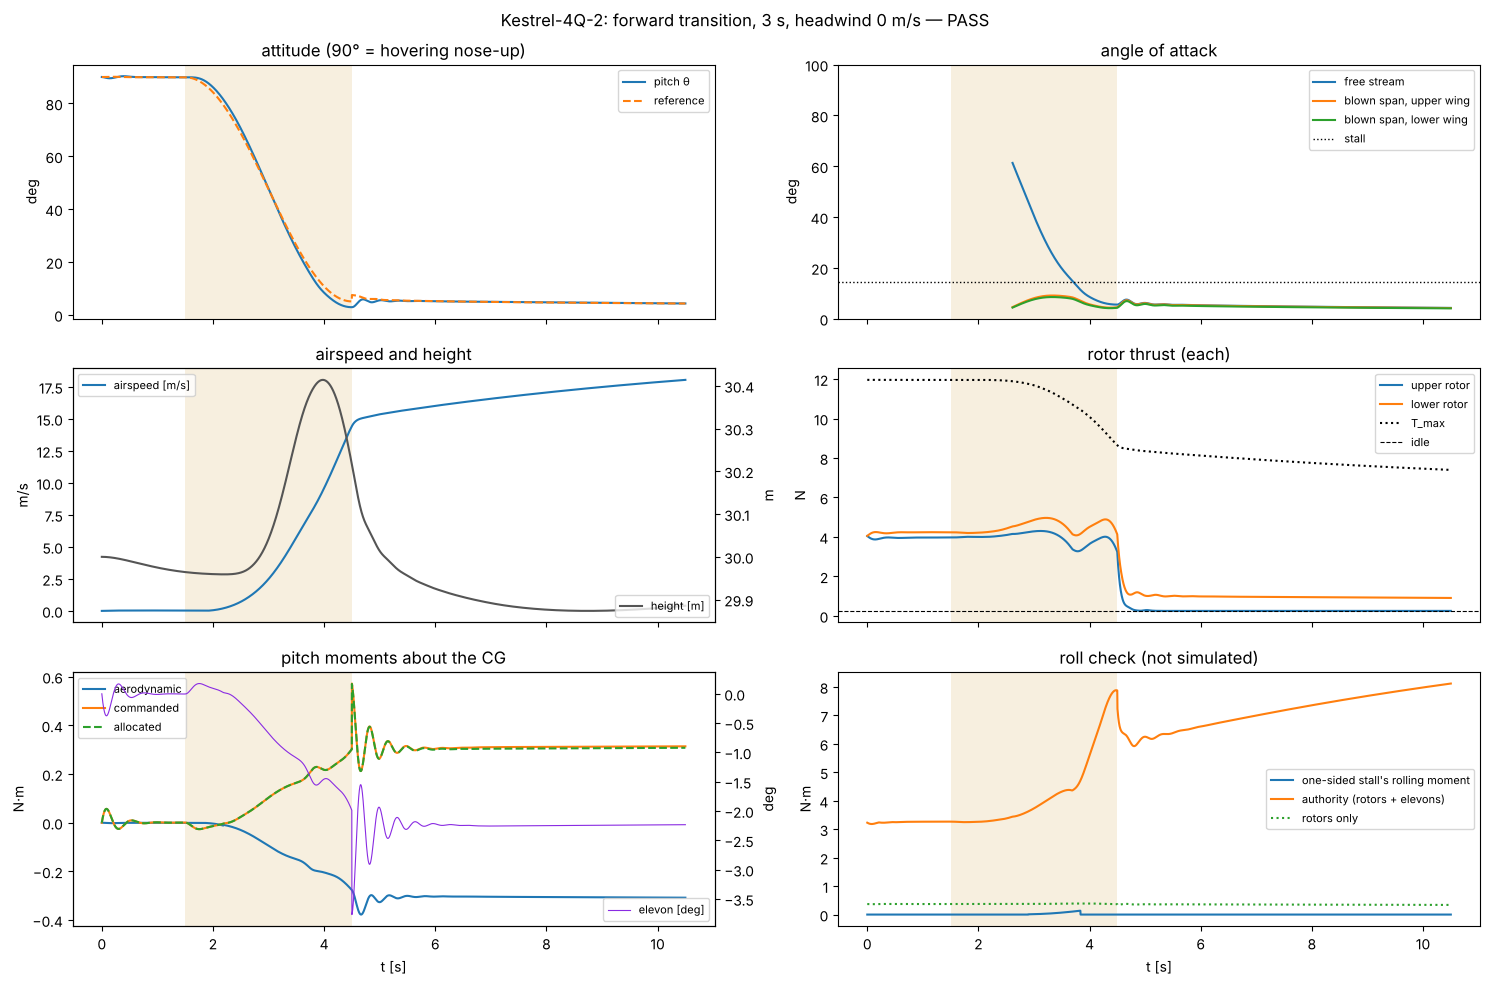

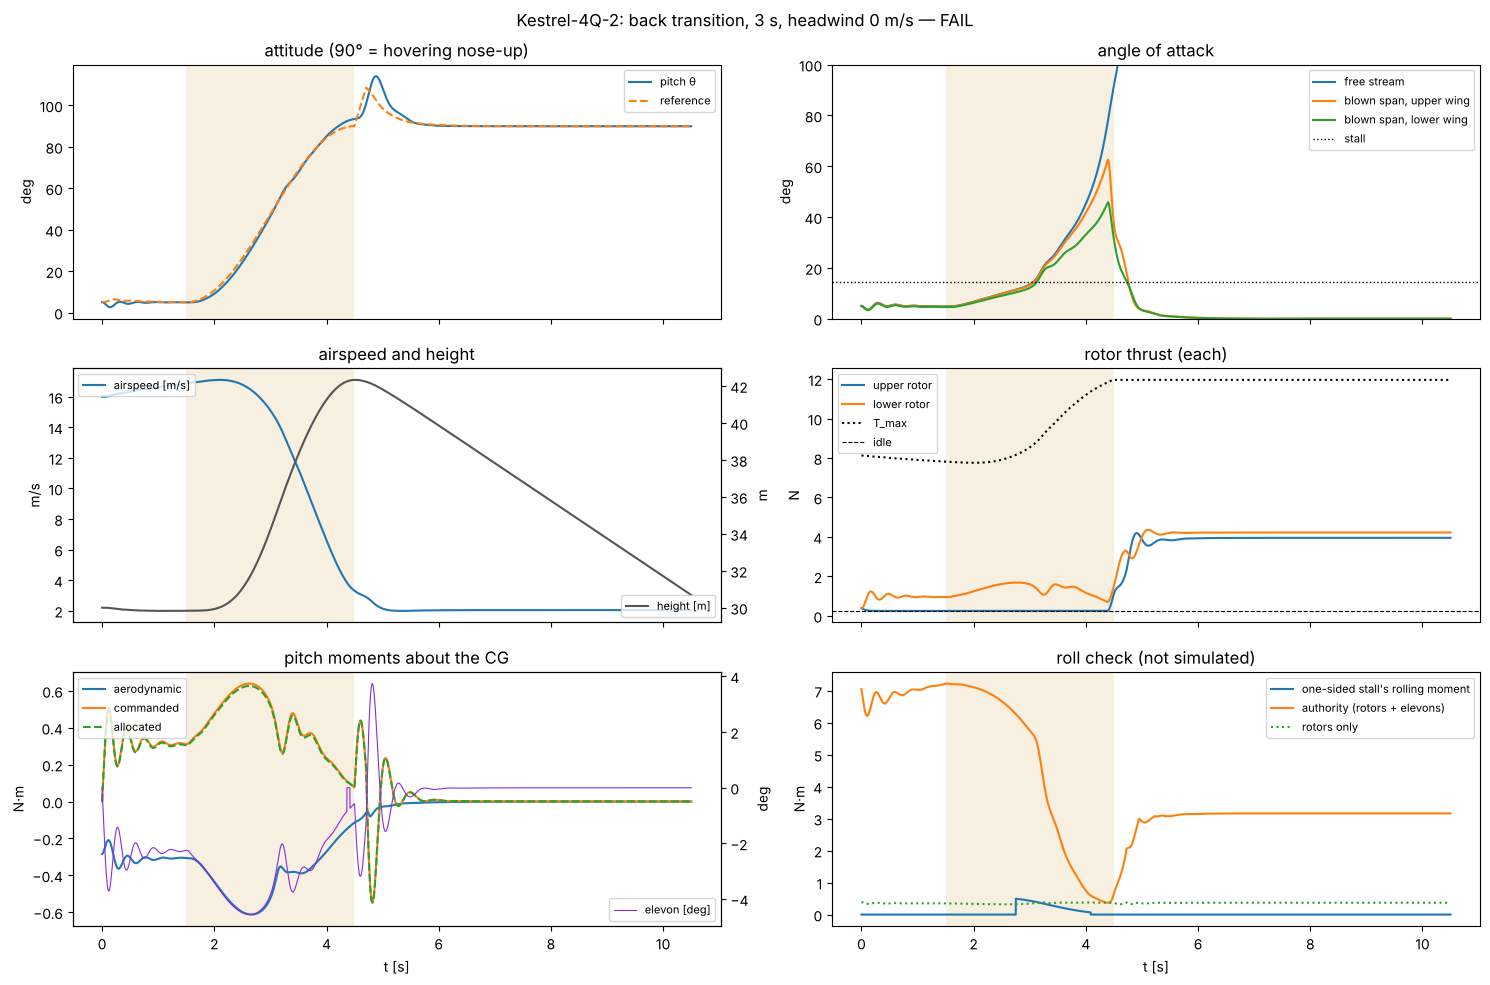

In [26]:
P2 = kestrel.resolve(dict(P, elevons=True, strut_fairing=True, bracing="posts"))
assert kestrel.Kestrel4Q.checks(P2) == []
T2 = ks.mass_table(P2); CI2 = ks.cg_inertia(T2)
A2 = A                                                   # the same wings: the lattice is unchanged
D2 = kf.drag_buildup(P2, faired=True)                   # faired posts, no diagonals
POL2 = kf.polar(P2, a=A2, d=D2)
cd90_2 = POL2.cd90 + 1.2 * 0.5 * (FAIR["broadside area of the struts, faired [m²]"] - FAIR["broadside area of the struts, round [m²]"]) / L["S_ref"]
if HAVE_ZEPHYR and pick:                                 # the finalist's section: its drag on the wings' share, its cl_max and α₀
    POL2 = kf.Polar(cl_alpha=POL2.cl_alpha, cd0=D2["Cd0"] - D2["Cd0_wings"] + D2["Cd0_wings"] * SECTION_CD_RATIO, k=POL2.k, cl_max=SECTION_CL_MAX,
                    cd90=cd90_2, alpha0=SECTION_ALPHA0, source=f"{pick} (Zephyr)")
else:
    POL2 = kf.Polar(**{**POL2.__dict__, "cd90": cd90_2})
print("Kestrel-4Q-2's polar:", POL2)
NP2 = kf.neutral_point(P2, x_cg=CI2["x_cg"], a=A2)
VEH2 = kt.make_vehicle(P2, aero=A2, pol=POL2, name="Kestrel-4Q-2"); VEH2.elevon_tau = TAU_EL
CRU2 = kf.cruise(P2, mass_kg=CI2["mass_kg"], x_cg=CI2["x_cg"], z_cg=CI2["z_cg"], pol=POL2)
display(CRU2.round(3))
HA2 = kc.hover_authority(P2, mass_kg=CI2["mass_kg"], cg={"x_cg": CI2["x_cg"], "y_cg": 0.0, "z_cg": CI2["z_cg"]}, inertia=CI2["I"])
MAT2, EPS2 = kt.matrix({"Kestrel-4Q-2": VEH2}, durations=durs, headwinds=(0.0, 6.0), progress=True)
display(MAT2[cols].astype({c: float for c in cols if c != "pass"}).round(2))
V2 = kt.verdict(MAT2)
for k, v in V2.items():
    print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
GUST2 = {f"{k}, gust {g:+g} m/s": kt.simulate(VEH2, k, t_tr=3.0, gust_up=g).metrics["pass"] for k in ("forward", "back") for g in (3.0, -3.0)}
print("gusts (entered at the cruise speed):", GUST2)
# the low-drag aircraft's back transition balloons: the slow-entry rule, and the matrix again with it
STRAT2 = {}
for ve in (16.0, 13.0, 12.0):
    for hw in (0.0, 6.0):
        for tt in durs:
            STRAT2[(ve, hw, tt)] = kt.simulate(VEH2, "back", t_tr=tt, headwind=hw, V_entry=ve).metrics
ST2 = pd.DataFrame(STRAT2).T; ST2.index.names = ["entry speed [m/s]", "headwind [m/s]", "t_tr [s]"]
display(ST2[cols].astype({c: float for c in cols if c != "pass"}).round(2))
GUST2_SLOW = {f"back, gust {g:+g} m/s, entered at 13 m/s": kt.simulate(VEH2, "back", t_tr=3.0, gust_up=g, V_entry=13.0).metrics["pass"] for g in (3.0, -3.0)}
print("gusts with the slow entry:", GUST2_SLOW)
back13 = ST2.xs(13.0, level=0)["pass"].astype(bool)
fwd = MAT2.xs("forward", level=1)["pass"].astype(bool)
V2_RULE = {"forward": f"{int(fwd.sum())} of {len(fwd)}", "back, entered at 13 m/s": f"{int(back13.sum())} of {len(back13)}"}
print("Kestrel-4Q-2 with the slow-entry rule:", V2_RULE)
fig, ax = plt.subplots(2, 1, figsize=(12, 9)); kd.front_view_4q2(P2, cg=CI2, ax=ax[0]); kd.side_view(P2, x_cg=CI2["x_cg"], x_np=NP2["x_np"], ax=ax[1]); plt.tight_layout(); plt.show()
for ep in (EPS2[("Kestrel-4Q-2", "forward", 3.0, 0.0)], EPS2[("Kestrel-4Q-2", "back", 3.0, 0.0)]):
    kd.episode_figure(ep, VEH2); plt.show()

In [27]:
def row(name, p_, ci, pol, cru, mat, np_):
    c16 = cru.loc[16.0]
    best = cru[cru["feasible"]]
    return {"mass [kg]": ci["mass_kg"], "static margin": np_["static_margin"], "Cd0": pol.cd0, "L/D at 16 m/s": c16["L/D"], "L/D best": best["L/D"].max(),
            "power at 16 m/s [W]": c16["electrical [W]"], "endurance at 16 m/s [min]": c16["endurance [min]"], "endurance best [min]": best["endurance [min]"].max(),
            "trim by thrust at 16 m/s": bool(c16["trim by thrust"]), "section": pol.source if pol.source != "model" else "NACA 0012",
            "elevons": bool(p_["elevons"]), "bracing": p_["bracing"], "struts": "faired" if p_["strut_fairing"] else "round",
            "transitions passed": f"{int(mat['pass'].astype(bool).sum())} of {len(mat)}" + (f" ({V2_RULE['back, entered at 13 m/s']} back with the 13 m/s entry)" if name == "4Q-2" else ""),
            "hover pitch [rad/s²]": None}
OPT = pd.DataFrame({"Kestrel-4Q (Part I)": row("4Q", P, CI, POL, CRU["round tubes"], MAT.xs("elevons", level=0), NP),
                    "Kestrel-4Q-2": row("4Q-2", P2, CI2, POL2, CRU2, MAT2, NP2)}).T
OPT["hover pitch [rad/s²]"] = [HA.iloc[1]["angular acceleration [rad/s²]"], HA2.iloc[1]["angular acceleration [rad/s²]"]]
display(OPT)
c16_2 = CRU2.loc[16.0]
fwd2, back2_13 = passes(MAT2, direction="forward"), (int(back13.sum()), len(back13))
CHK9 = [kl.check("take-off mass [kg]", CI2["mass_kg"]), kl.check("hover thrust / weight", ks.hover_point(CI2["mass_kg"])["T_W"]), kl.check("static margin [chords]", NP2["static_margin"]),
        kl.check("stall speed / cruise speed", kf.stall_speed(P2, mass_kg=CI2["mass_kg"], pol=POL2) / kf.V_CRUISE), kl.check("endurance at the cruise [min]", float(c16_2["endurance [min]"])),
        kl.check("forward transitions: passing", fwd2[0] / fwd2[1], "≥", 1.0, note=f"{fwd2[0]} of {fwd2[1]}"),
        kl.check("back transitions entered at the cruise speed: passing", passes(MAT2, direction="back")[0] / passes(MAT2, direction="back")[1], "≥", 1.0, note="balloons past 10 m: the rule below"),
        kl.check("back transitions entered at 13 m/s: passing", back2_13[0] / back2_13[1], "≥", 1.0, note=f"{back2_13[0]} of {back2_13[1]}"),
        kl.check("gusts ±3 m/s with the slow entry: passing", sum(bool(v) for v in GUST2_SLOW.values()) / len(GUST2_SLOW), "≥", 1.0)]
show_checks(CHK9, "iteration 9 — Kestrel-4Q-2")
LOG.add("9 — Kestrel-4Q-2", changed="elevons + faired posts + no X + the section; the slow-entry rule (≤ 13 m/s)", source="all of the above", checks=CHK9,
        **{"take-off mass [kg]": CI2["mass_kg"], "static margin [chords]": NP2["static_margin"], "hover thrust / weight": ks.hover_point(CI2["mass_kg"])["T_W"],
           "stall speed [m/s]": kf.stall_speed(P2, mass_kg=CI2["mass_kg"], pol=POL2), "Cd0": POL2.cd0, "L/D at the cruise": float(c16_2["L/D"]), "cruise power [W]": float(c16_2["electrical [W]"]),
           "endurance at the cruise [min]": float(c16_2["endurance [min]"]), "transitions passing": f"{fwd2[0] + back2_13[0]} of {fwd2[1] + back2_13[1]} (back at 13 m/s)"})

,mass [kg],static margin,Cd0,L/D at 16 m/s,L/D best,power at 16 m/s [W],endurance at 16 m/s [min],endurance best [min],trim by thrust at 16 m/s,section,elevons,bracing,struts,transitions passed,hover pitch [rad/s²]
Kestrel-4Q (Part I),1.686206,0.095525,0.066549,4.956276,7.322605,110.215621,21.270306,40.193712,True,NACA 0012,False,x,round,11 of 12,94.992838
Kestrel-4Q-2,1.651145,0.091586,0.02574,10.599409,12.061619,59.122378,39.651991,57.036213,False,NACA 23112 (k2/k1 0.03) (Zephyr),True,posts,faired,8 of 12 (6 of 6 back with the 13 m/s entry),88.384113


iteration 9 — Kestrel-4Q-2,value,target,holds,note
check,,,,
take-off mass [kg],1.65,≤ 2,✔,
hover thrust / weight,2.95,≥ 2,✔,
static margin [chords],0.0916,0.05 – 0.15,✔,
stall speed / cruise speed,0.597,≤ 0.8,✔,
endurance at the cruise [min],39.7,≥ 20,✔,
forward transitions: passing,1,≥ 1,✔,6 of 6
back transitions entered at the cruise speed: passing,0.333,≥ 1,✘,balloons past 10 m: the rule below
back transitions entered at 13 m/s: passing,1,≥ 1,✔,6 of 6
gusts ±3 m/s with the slow entry: passing,1,≥ 1,✔,


iteration 9 — Kestrel-4Q-2: 8 of 9 hold — failing: back transitions entered at the cruise speed: passing


{'iteration': '9 — Kestrel-4Q-2',
 'what changed': 'elevons + faired posts + no X + the section; the slow-entry rule (≤ 13 m/s)',
 'source': 'all of the above',
 'take-off mass [kg]': 1.651145,
 'static margin [chords]': np.float64(0.0915860620999865),
 'hover thrust / weight': 2.9546491627343094,
 'stall speed [m/s]': 9.559300456114304,
 'Cd0': 0.02573992234522169,
 'L/D at the cruise': 10.599408892465885,
 'cruise power [W]': 59.12237767797982,
 'endurance at the cruise [min]': 39.65199120997368,
 'transitions passing': '12 of 12 (back at 13 m/s)',
 'checks holding': '8 / 9',
 'failing': 'back transitions entered at the cruise speed: passing'}

**Drag, power and the maximum speed against airspeed; the manoeuvrability in horizontal flight.** The level-flight
drag split into its parasite and induced parts, the rotors' full thrust falling with the inflow and where it meets the
drag (the maximum speed, thrust-limited; the structural never-exceed speed is a separate question), the electrical
power; then what each aircraft can do about its three axes in cruise: the pitch and yaw accelerations the rotors give by
differential thrust (little, once the drag — and so the cruise thrust — is small: the split is bounded by the idle
thrust below and T_max above) and the elevons add, the steady roll rate against the wings' roll damping, and the turn
at the load factor the lift allows.

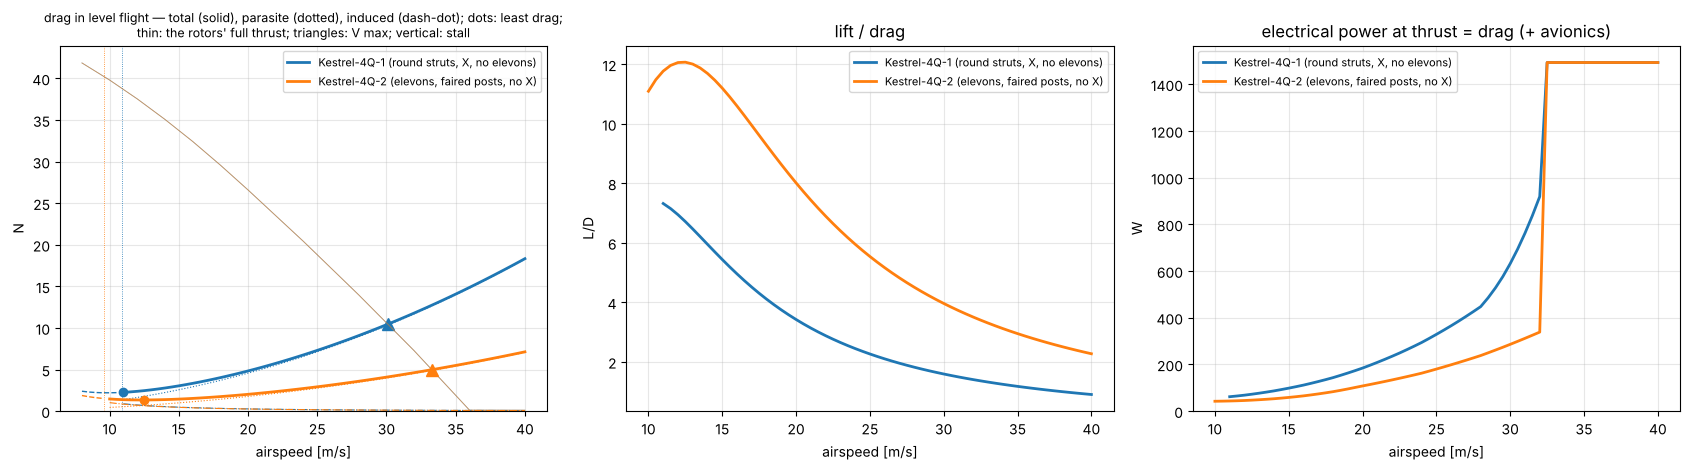

,V stall [m/s],V of least drag [m/s],least drag [N],best L/D,drag at 16 m/s [N],parasite at 16 [N],induced at 16 [N],power at 16 m/s [W],least power [W],V of least power [m/s],"V max, thrust = drag [m/s]",full thrust at 16 m/s [N],thrust / drag at 16 m/s,power at V max [W]
"Kestrel-4Q-1 (round struts, X, no elevons)",10.91,11.0,2.26,7.32,3.34,2.92,0.41,111.44,61.66,11.0,30.09,32.42,9.72,642.74
"Kestrel-4Q-2 (elevons, faired posts, no X)",9.56,12.5,1.34,12.07,1.53,1.13,0.40,65.27,42.22,10.0,33.28,32.42,21.22,1493.00


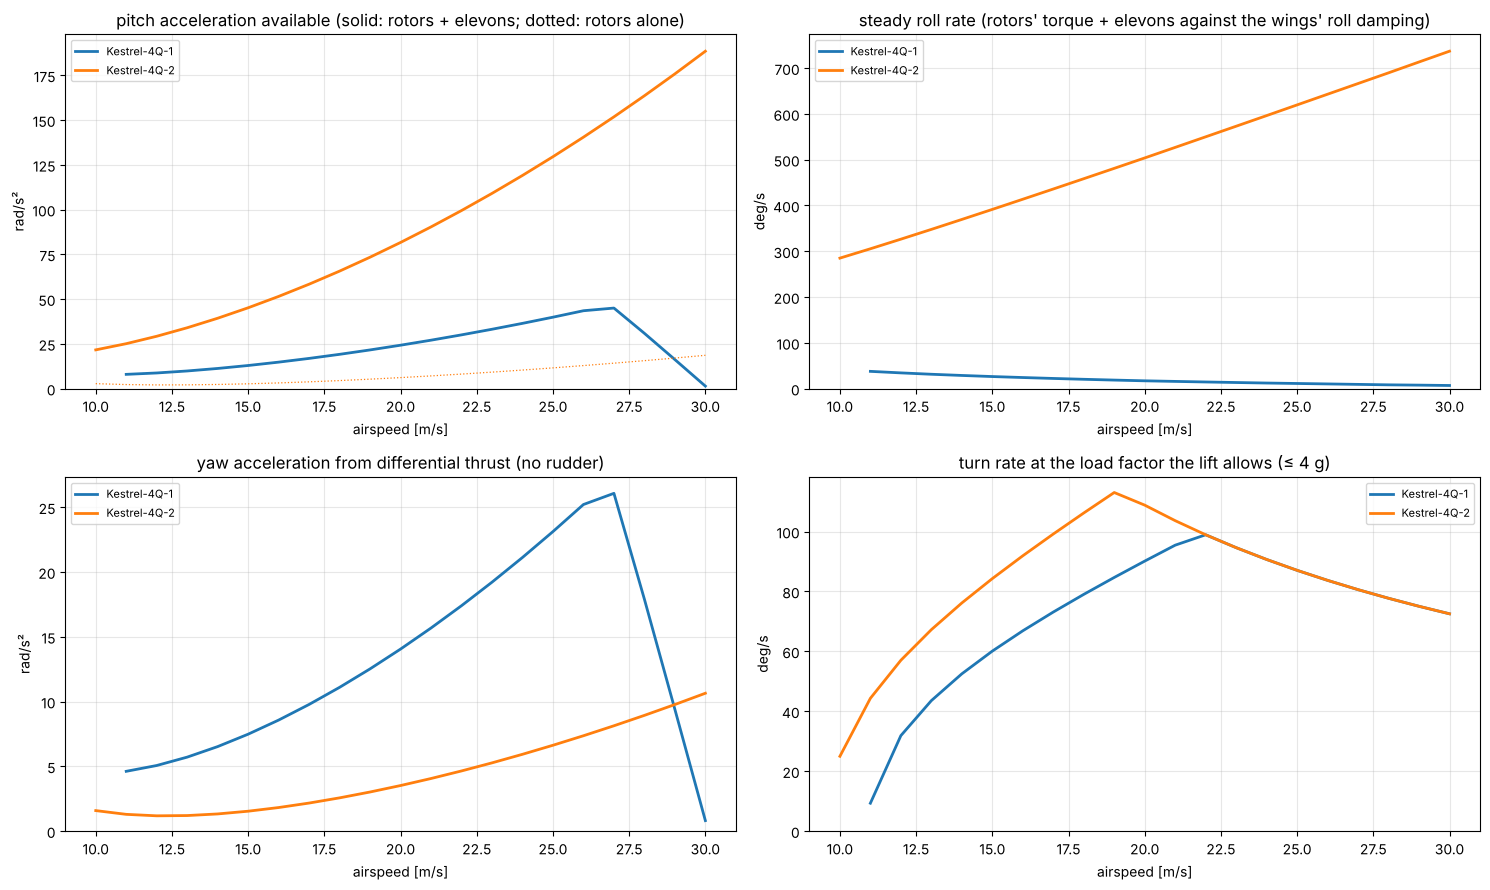

Kestrel-4Q-1


,CL,thrust per rotor [N],ΔT available [N],pitch: rotors [rad/s²],pitch: elevons [rad/s²],pitch: total [rad/s²],yaw: rotors [rad/s²],roll: rotors' torque [N·m],roll: elevons [N·m],roll acceleration [rad/s²],steady roll rate [deg/s],load factor available,turn rate [deg/s],turn radius [m]
V [m/s],,,,,,,,,,,,,,
12.0,0.67,0.60,0.35,8.74,0.0,8.74,5.06,0.42,0.0,3.94,34.35,1.21,31.87,21.57
16.0,0.38,0.83,0.58,14.79,0.0,14.79,8.57,0.39,0.0,3.71,24.21,2.15,66.86,13.71
20.0,0.24,1.21,0.96,24.25,0.0,24.25,14.05,0.35,0.0,3.26,17.03,3.36,90.13,12.71
25.0,0.15,1.83,1.58,39.90,0.0,39.90,23.12,0.28,0.0,2.68,11.20,4.00,87.05,16.46


Kestrel-4Q-2


,CL,thrust per rotor [N],ΔT available [N],pitch: rotors [rad/s²],pitch: elevons [rad/s²],pitch: total [rad/s²],yaw: rotors [rad/s²],roll: rotors' torque [N·m],roll: elevons [N·m],roll acceleration [rad/s²],steady roll rate [deg/s],load factor available,turn rate [deg/s],turn radius [m]
V [m/s],,,,,,,,,,,,,,
12.0,0.66,0.34,0.09,2.06,27.18,29.24,1.18,0.42,3.57,35.24,326.43,1.58,57.03,12.06
16.0,0.37,0.38,0.13,3.18,48.32,51.50,1.82,0.39,6.34,59.54,413.65,2.80,91.90,9.98
20.0,0.24,0.51,0.26,6.15,75.50,81.65,3.52,0.35,9.90,90.65,503.84,4.00,108.81,10.53
25.0,0.15,0.73,0.48,11.58,117.96,129.55,6.63,0.28,15.48,139.37,619.71,4.00,87.05,16.46


In [28]:
VEH1 = kt.make_vehicle(P, aero=A, elevons=False, name="Kestrel-4Q-1")
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
DRAG = kd.drag_vs_speed({"Kestrel-4Q-1 (round struts, X, no elevons)": VEH1, "Kestrel-4Q-2 (elevons, faired posts, no X)": VEH2}, speeds=np.arange(8.0, 40.5, 0.5), axs=axs)
plt.tight_layout(); plt.show()
display(DRAG.round(2))
fig, axs = plt.subplots(2, 2, figsize=(15, 9))
MANV = kd.manoeuvrability_figure({"Kestrel-4Q-1": VEH1, "Kestrel-4Q-2": VEH2}, axs=axs); plt.tight_layout(); plt.show()
for k, df in MANV.items():
    print(k); display(df.loc[[v for v in (12.0, 16.0, 20.0, 25.0) if v in df.index]].round(2))

## 17. The X-wing

The same motors, battery and pod on four cantilever panels at ±45° with no bracing at all is a different airframe,
not an option of this one: it has its own notebook, **`39_xwing`** (`designs/kestrel_xwing.py`), which reads this
notebook's record (`designs/data/kestrel_design.json`) for the comparison against Kestrel-4Q and Kestrel-4Q-2. In one
line: a panel at 45° gives back only cos 45° of its lift vertically, so the X of the same area has about half the
biplane's vertical lift slope and cruises at 16 m/s with its panels near the stall; it flies its transitions in the
same panel model, weighs less (no truss, no fin), and its pitch and yaw levers are equal.

## 18. The loop's log, and the findings of Part II

One row per pass: what was plugged in, what it changed, how the key numbers moved and how many checks held. The path
from the envelope to Kestrel-4Q-2.

In [29]:
ITER = LOG.frame()
display(ITER)
ITER.to_csv(OUT / "iterations.csv")

,what changed,source,take-off mass [kg],static margin [chords],hover thrust / weight,stall speed [m/s],Cd0,L/D at the cruise,cruise power [W],endurance at the cruise [min],transitions passing,checks holding,failing
iteration,,,,,,,,,,,,,
0 — envelope,—,spec + layout + 5 assumptions,2.000000,0.120000,2.000000,11.272546,NaN,6.000000,108.094788,21.687632,NaN,6 / 6,—
"1 — CAD, Boreas, lattice, drag build-up",the CG target at 10 % of the chord (battery station),"kestrel_systems, Boreas, PEREGRINE lattice",1.686206,0.095525,2.893213,10.910411,0.066549,4.956276,110.215621,21.270306,NaN,8 / 9,battery inside its bay (not at a stop)
2 — transition model,elevons; pitch-over ≥ 3 s; back entry 13 m/s,kestrel_transition (model polar),1.686206,0.095525,2.893213,10.910411,0.066549,4.956276,110.215621,21.270306,8 of 8 (≥ 3 s),5 / 7,"rotors only, every schedule, cruise entry: passing, elevons, every schedule: passing"
3 — CFD plugged in,"the polar read against the CFD (sweep correction, 10 solved cases)","38_kestrel run on an OpenFOAM machine (uploaded notebook), Part I points, screening qu...",1.686206,0.164480,2.893213,13.348992,0.053229,4.956276,110.215621,21.270306,12 of 12,5 / 7,"CL max below 20°, CFD / the model's polar peak, blown cases solved"
4 — payload bay (Part II),"pod 430 → 470 mm, ogive nose, the capsule on the axis",CAD bays + mass table + transitions,2.276206,0.063769,2.143283,12.676273,0.066549,NaN,120.008654,19.534591,8 of 8,5 / 6,"endurance at the cruise, full [min]"
5 — elevons (Part II),"four 28 % surfaces from 275 mm to the tips, τ from Zephyr",CAD + kestrel_control + transitions,1.734206,0.095525,2.893213,10.910411,0.066549,NaN,NaN,NaN,11 of 12,3 / 4,"transitions, rotors only: passing"
6 — faired struts (Part II),teardrop sleeves on posts and diagonals,drag build-up + CAD + transitions,1.744552,0.095525,2.893213,10.910411,0.023429,11.457556,59.217452,39.588329,10 of 12,4 / 5,"trim by thrust alone, faired"
"7 — reflexed section (Part II, Zephyr)",NACA 23112 (k2/k1 0.03) instead of NACA 0012,vegeta.zephyr / NeuralFoil,1.686206,0.095525,NaN,9.660261,NaN,NaN,NaN,NaN,NaN,4 / 5,CFD slab cases of the finalists solved
8 — bracing (Part II),"the X diagonals dropped, posts kept","kestrel_structure (frame, modes)",1.603145,NaN,NaN,NaN,0.020261,NaN,NaN,NaN,NaN,4 / 4,—


### Findings — Part II

**The payload bay (§ 11).** The capsule fits once the pod has a 220 mm constant mid-body (the pod grew from 430 to
470 mm; the nose became an ellipsoidal ogive with the camera dome flush). The battery on the floor, the capsule on
the axis, the electronics above: the capsule's contents move the CG 3–4 mm aft at most, because the bay sits just
behind it. What the capsule costs: 1.69 → 1.78 kg empty, 2.08 kg nominal, 2.28 kg full; static margin 0.096 → 0.073
→ 0.064 (the battery is at its forward stop in every case — the margin is bought by the bay's position, not by the
battery); hover thrust-to-weight 2.89 → 2.35 → 2.14 (the ≥ 2 target holds full); stall speed 10.9 → 12.1 → 12.7 m/s;
endurance at 16 m/s 21 → 20 min on 4Q's drag (the best endurance 40 → 27 min). The transitions at 2.08 and 2.28 kg
pass, both ways, still air and headwind. **Proved**: the pod carries 0.5 kg of medical supplies without a change
to the wings, the rotors or the flight rules.

**Elevons (§ 12).** Four surfaces of 39 × 225 mm (12.6 % of the wing area), 48 g with their servos. The hinge
moments are small — 0.012 N·m at 16 m/s and 20°, 0.033 N·m at 25 m/s and 25°, 0.007 N·m in the hover's 12.8 m/s
slipstream: a 9 g servo (0.17 N·m) has a 5–25 × margin. Their authority: in the hover, deflected differentially in
the slipstream, they give 4.1 N·m about the thrust axis against the rotors' 0.24 N·m of reaction torque — **the
heading, the weak axis of Part I, is 17 × stronger with elevons**; in cruise the roll lever is 16 × the rotors'. In
the transitions the elevons' CAD span (275 mm to the tip) does what Part I's slipstream-edge assumption did: 11 of 12
against 3 of 12 for the rotors alone (the 1.5 s pitch-over fails on height, as before). NeuralFoil puts a 28 % plain
flap's τ at 0.47 at Re 1.5e5 (n_crit 6), close to the 0.45 assumed — the margins stand. **Proved**, with one
discovery that reads both ways: once the drag is low (§ 13), the cruise thrust is so small that the rotors have almost
no thrust split left for pitch and yaw (0.1–0.5 N at 12–25 m/s, bounded by the idle thrust): in cruise the elevons
are not an addition to the rotors' control, they *are* the control, and a yaw surface or differential elevon-drag
scheme belongs on the to-do list.

**Faired struts (§ 13).** The sleeves weigh ~11 g (foam and film; 36 g printed) and cut the truss's drag at 16 m/s
from 2.1 N to 0.23 N: Cd0 0.067 → 0.024, power at 16 m/s 111 → 60 W, endurance 21 → 39 min, L/D 4.9 → 11.4. The
costs are real and both show up in the transitions: the sleeves' broadside area is 3.8 × the tubes' (0.056 against
0.015 m², a fifth of the wings' planform) and — the larger effect — **a low-drag aircraft balloons on the pitch-up**:
the faired 4Q with elevons gains 6 m at the 5 s schedule and fails the height criterion where the round-strut aircraft
passed. The faired struts also take the thrust-only trim away for good (the upper pair would have to pull). **Proved as
a drag measure, with two conditions**: elevons, and the slow entry into the back transition (below).

**A reflexed section (§ 14, Zephyr).** Thirteen candidates on NeuralFoil at Re 1.5e5 and 7e4. The standard reflexed
lines (22112, 23112, 24112) sit at cm ≈ 0 like the 0012; more aft reflex raises cm₀ to +0.02–0.04. The pick by the
criterion (trims the cruise within ±3° of elevon, cl_max no worse, the least trim drag): **NACA 23112 with k₂/k₁ 0.03**
— it trims with −0.6° of elevon where the 0012 needs −5.8° (and loses a third of its cl to it), cl_max 1.15 against
1.06. Its cost is 26 % more section drag at the cruise cl, which is what the 0012's trim elevon costs: at the section
level the two are a wash (cd 0.0162 vs 0.0158). The surrogate's confidence on the reflexed line's attached branch is
0.84–0.91 (0.96 for the 0012). **Disproved as a drag saving, proved as a trim measure**: the reflex keeps the elevons
level and their full travel for control, and keeps the stall margin the trim elevon would have spent. The eight
Aeromant slab cases of the two finalists are prepared (NOT RUN here) — the check this choice waits for.

**Lighter bracing (§ 15).** Strength never asked for the truss (an 18 × spar reserve bare). Stiffness: the X
diagonals make the motor stations 280 × stiffer symmetrically (327 against 1.2 N/mm) and put the pair's first bending
mode at ~260 Hz; without them it is ~15 Hz — eight times the pitch loop's 1.9 Hz and a seventh of the rotor's 1P
(110 Hz): clear of both. The posts alone hold the antisymmetric case (12,600 N/mm: one wing cannot move against the
other) and close the 6 mm propeller-gap change of the one-wing-stalled case. Dropping the X saves 87 g (−5 %) and
74 cm² of drag area with round struts (8 cm² faired), the posts cost 41 g. **Proved**: posts only, faired. Torsion
of the wing pair and the joints' peel are the Talos check that remains before this is final.

**Kestrel-4Q-2 (§ 16).** Elevons, faired posts, no diagonals, the reflexed section: **1.651 kg** (−35 g), Cd0
**0.026** (−61 %), L/D at 16 m/s **10.6** (4Q: 5.0), power at 16 m/s **59 W** (110 W), endurance **40 min** at
16 m/s and **57 min** at best (4Q: 21 and 40), static margin 0.092, hover pitch 88 rad/s². Maximum speed 33.3 m/s
against 4Q's 30.1 — thrust-limited by the 9×6's pitch speed, not by drag, which is why a quarter of the drag buys 3
m/s. The manoeuvrability in cruise: the elevons give 48 rad/s² of pitch and a 414°/s roll rate at 16 m/s where 4Q had
15 rad/s² and 24°/s from its rotors; the turn at the lift limit 92°/s and 10 m radius (4Q: 67°/s, 14 m). The
transitions: forward 6 of 6; back, entered at the cruise speed, **0 of 6** — the aircraft climbs 12 m (3 s schedule)
to 16 m (5 s) on the pitch-up, past the 10 m band, and the back-transition gusts fail with it. **Entered at 13 m/s
(1.35 × the stall speed) every back transition passes** (5–9 m of climb) and so do the gusts; at 12 m/s the climb is
3–6 m. 4Q-2's operating rule is therefore mandatory, not advisory: slow to ≤ 13 m/s before the pitch-up. With it,
4Q-2 passes 12 of 12 and 4Q's verdict is improved on every count but one — the thrust-split control the low drag
takes away in cruise, which the elevons replace.

**What the model says and what it cannot.** Every transition here flies on the model's polar; the CFD at the
transition points (14 cases with four rotor disks) and the slab cases of the two sections are prepared and NOT RUN.
The reflexed section's numbers are a surrogate's. The torsion of the posts-only wing pair, the elevon hinges and the
motor mounts wait for Talos. The X-wing of the same motors, battery and pod has its own notebook (39).

In [30]:
STATUS.update({"CAD": "run", "mass table": "run", "propulsion (Boreas tables)": "run", "hold point (allocation)": "run",
               "vortex lattice + drag build-up + polar": "run", "cruise": "run",
               "transitions (model polar)": f"run ({len(MAT)} in the matrix, {int(MAT['pass'].astype(bool).sum())} pass)",
               "truss frame + ground stance": "run", "FEA (Talos) of the joints": "NOT RUN (next step)",
               "Part II: elevons, faired struts, bracing, 4Q-2": f"run ({int(MAT2['pass'].astype(bool).sum())} of {len(MAT2)} 4Q-2 transitions pass)",
               "Part II: reflexed section (Zephyr)": "run" if HAVE_ZEPHYR else "NOT RUN (merge dev_zephyr: vegeta.zephyr)",
               "X-wing": "its own notebook, 39_xwing"})
if DEBUG:
    STATUS["CFD"] = "MOCKED (VEGETA_DEBUG): the numbers mean nothing"
display(pd.Series(STATUS, name="status").to_frame())

def plain(x):
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x

def rows(df):
    return {" | ".join(map(str, k)) if isinstance(k, tuple) else str(k): {kk: plain(vv) for kk, vv in r.items()} for k, r in df.T.to_dict().items()}

DESIGN = {"source": "38_kestrel", "params": {k: plain(v) for k, v in P.items()},
          "layout": {k: plain(v) for k, v in L.items() if isinstance(v, (int, float))},
          "mass": {k: plain(v) for k, v in CI.items() if k != "I"}, "hover": {k: plain(v) for k, v in HP.items()},
          "allocation_rank": {k: int(v) for k, v in RANK["rank"].items()},
          "biplane": {k: plain(v) for k, v in A["factors"].items()}, "neutral_point": {k: plain(v) for k, v in NP.items()},
          "Cd0": {"round": plain(D_round["Cd0"]), "faired": plain(D_faired["Cd0"])},
          "transitions": rows(MAT[cols]), "verdict": VER, "verdict_cfd": VER_CFD, "back_strategies": rows(ST[cols]),
          "cfd": rows(CFDT.astype(str)), "cfd_plug_in": {"source": PI["source"], "campaign": (CAMP or {}).get("meta"), "sweep": {k: {kk: plain(vv) for kk, vv in v.items()} for k, v in SWEEP_NUM.items()}},
          "iterations": LOG.to_dict(), "ground": {k: plain(v) for k, v in GS.items() if k != "edges"},
          "part2": {"options": rows(OPT.astype(object)), "bracing_modes": rows(MODES), "transitions_4q2": rows(MAT2[cols]), "verdict_4q2": kt.verdict(MAT2),
                    "section": (rows(SECT) if HAVE_ZEPHYR else "NOT RUN"), "trim": (rows(TRIM) if HAVE_ZEPHYR else "NOT RUN"),
                    "capsule": rows(CAPT.astype(object)), "transitions_capsule": rows(MAT_CAP[cols]),
                    "strategies_4q2": rows(ST2[cols]), "verdict_4q2_slow_entry": V2_RULE, "gusts_4q2": {**GUST2, **GUST2_SLOW},
                    "drag_vs_speed": rows(DRAG), "manoeuvrability_at_16": {k: {kk: plain(vv) for kk, vv in df.loc[16.0].items()} for k, df in MANV.items() if 16.0 in df.index}},
          "status": STATUS}
target = OUT / "kestrel_design.json" if DEBUG else Path("designs/data/kestrel_design.json")
target.write_text(json.dumps(DESIGN, indent=1, default=str))
print("written", target)

,status
CFD,NOT RUN here
CAD,run
mass table,run
propulsion (Boreas tables),run
hold point (allocation),run
vortex lattice + drag build-up + polar,run
cruise,run
transitions (model polar),"run (36 in the matrix, 25 pass)"
truss frame + ground stance,run
FEA (Talos) of the joints,NOT RUN (next step)


written designs/data/kestrel_design.json
